---

# Data Science Competition JOINTS x INSPIRE UGM 2026 (v19)

*Memprediksi penjualan tiket harian D4 sampai D10 per pasangan film dan klaster bioskop dari tiga hari pertama, dengan TabPFN-3.5 penuh dan Causilo yang dikompresi agar keduanya muat di bawah 200 MB, label latih yang dibersihkan dari anomali pelaporan Juni 2025, dan minggu Lebaran yang levelnya diukur dari data Lebaran 2025 serta kapasitas kursi 2026.*

---

## RestuAyahDoaIbu

- Mochamad Fachri Alfaridzi (Ketua)
- Riantama Putra
- Tiara Kusuma Wardhani

---

## Table of Contents

1. [**Introduction**](#1)
2. [**Initialization**](#2)
3. [**Data Acquisition & Audit**](#3)
4. [**Exploratory Data Analysis**](#4)
5. [**Data Cleaning**](#5)
6. [**Preprocessing**](#6)
7. [**Feature Engineering**](#7)
8. [**Modeling**](#8)
9. [**Evaluation**](#9)
10. [**Inference & Submission**](#10)


---

# Introduction <a name="1"></a>

---

## Overview

*Operator bioskop harus menentukan alokasi layar ketika film baru hanya memiliki tiga hari riwayat penjualan. Data latih mencakup April sampai September 2025, sedangkan film uji dirilis Oktober 2025 sampai Maret 2026: musim sepi, libur Natal, Ramadan, dan Lebaran.*

*Versi sebelumnya memiliki MASE validasi yang dibobot ke komposisi uji (TW-MASE) 0,377 sampai 0,388 dengan peringkat yang sama seperti leaderboard, tetapi dengan offset tetap sekitar 0,07. Offset yang sama pada model yang berbeda menandakan kesalahan sistematis yang diwarisi dari data latih. v4 menemukan salah satu sumbernya (di periode uji bioskop jauh lebih jarang mencopot film pada tingkat penonton yang sama) dan turun ke 0,4481. v5 menambah dua hal: fitur kompetisi per klaster pada klasifier pencopotan, dan prediksi minggu Lebaran yang diturunkan dari total klaster Lebaran 2025 di data latih, dan turun ke 0,4087. Dengan itu, TW-MASE di dunia dengan separuh pergeseran pencopotan (v5: 0,4066) praktis sama dengan leaderboard, sehingga metrik ini menjadi metrik keputusan. v6 memakai TabPFN-3.5 dan mencapai 0,4012. v7 menguji TabPFN-3.5 yang di-fine-tune (loss CRPS): lebih buruk dari versi in-context (TW-MASE 0,3968 vs 0,3840), bobot blend nol, dan dihapus. v8 memperbaiki metrik validasi: pasangan yang baru mulai laku di D3 (pembukaan terlambat) 2,3 kali lebih banyak di bobot lama daripada di data uji, sehingga bobot uji kini mencocokkan komposisi **skala x hari penjualan pertama**. TabPFN-3.5 memakai 16 anggota ensemble (bagging 3 seed pada hurdle LightGBM diuji, tidak di atas noise) dan mencapai 0,39991. **v9 mematuhi batas bobot model 200 MB**: TabPFN-3.5 (876 MB) diganti dua tabular foundation model yang muat, TabPFN-2.6 (51,6 MB) dan EXAONE-Tabular dari LG AI Research (84,5 MB). Keduanya dinilai out-of-fold dan bobot blend dipilih otomatis; checkpoint yang dipakai disimpan bersama model LightGBM dalam satu berkas bobot di bawah 200 MB sehingga notebook dapat dijalankan ulang tanpa internet. **v10 memperbaiki alat ukur sebelum mencari skor**: statistik klaster dihitung fold-local (sebelumnya melihat transaksi film validasi), backtest temporal bulanan ditambahkan, dan kandidat perbaikan (perubahan jumlah show dan tiket per show dengan nested cross-fitting; metadata resmi) diuji satu per satu terhadap baseline bersih dengan aturan adopsi yang ditulis sebelum hasil. Kalender libur sekolah Jawa Barat (22% baris uji) dikoreksi dari sumber resmi Disdik Jabar. v10 mencapai 0,40823 (lebih buruk dari v8): kedua kandidatnya gagal aturan adopsi, dan bobot EXAONE 0,7 dipilih dengan label asli walaupun dunia $\kappa$ memilih sekitar 0,4. **v11 mengikuti analisis 6 Oktober**: satu kandidat saja, fitur input D1 sampai D3 yang dinormalisasi kalender (satu-satunya preprocessing yang membaik di grouped CV, split kedua, backtest temporal, dan pipeline hurdle), dan bobot blend dipilih dengan minimax regret atas label asli, backtest temporal, dan dunia $\kappa$. Komponen model v11 adalah keluarga GBDT (LightGBM, CatBoost, XGBoost, masing-masing dengan struktur L1 + hurdle yang sama) dan Causilo (nums-ai, peringkat 1 TabArena menurut pembuatnya, 148,4 MB) sebagai foundation model. v11 di Kaggle: A3 membaik (TW 0,3319 ke 0,3310, temporal 0,3058 ke 0,3027) tetapi belum lolos ambang, CatBoost (0,3367) dan XGBoost (0,3342) lebih buruk dan berkorelasi galat 0,993 sampai 0,997 dengan LightGBM, Causilo jauh lebih buruk (0,3954), dan tidak ada blend yang lolos, sehingga submisi v11 = LightGBM saja. **v12** mempertahankan fondasi v11 dan menguji model secara berurutan dengan fitur baseline dibekukan: LightGBM sebagai kontrol, TabPFN-2.5 Quantiles (40,8 MB), lalu TabM (model tabular dilatih sendiri dengan loss kuantil); koreksi pencopotan dipilih per model, dan fitur kalender baru diuji sebagai A/B pada kombinasi terbaik. v12 mencapai 0,41060: validasi setara v8 (TW 0,3257 vs 0,3251), tetapi leaderboard tetap memburuk.*

*Seluruh versi v3 sampai v12 berjarak 0,062 sampai 0,067 dari leaderboard, berapa pun modelnya. Offset yang sama untuk semua model berarti sumbernya ada pada sesuatu yang dipakai bersama oleh semua model: target, kalender, atau fitur. Analisis 7 Oktober (`eda/65` sampai `eda/73`) menemukan sumbernya pada **cara level penjualan diukur**. Pasar periode uji hanya separuh pasar train (skala referensi klaster median 75 vs 146 tiket per hari), sehingga fitur level absolut (`log_s`, `f_logT`) membuat pasangan uji yang normal tampak seperti pasangan yang sedang sekarat di train. Pada label periode uji yang tersedia (D3 dari D1 dan D2), tabel berdasarkan level absolut memprediksi D3 terlalu rendah dengan median 0,32 sampai 0,38 skala pada pasangan berskala 5 sampai 50 (sepertiga pasangan uji), sedangkan level relatif terhadap film lain yang tayang bersamaan tidak bias. Di bawah tolok ukur relatif, "pergeseran kebijakan pencopotan" yang dikoreksi sejak v4 (odds 0,27) menyusut dua pertiga atau lebih (logit -1,3 menjadi -0,2 sampai -0,4, tergantung definisi referensi): bioskop terutama mencopot film yang lemah **dibanding film lain di bioskop itu**, bukan di bawah ambang tiket absolut. **v13** mengganti dua fitur level absolut dengan level relatif, memutuskannya dengan dua lensa di luar distribusi train (label periode uji dan split pasar sepi), dan menguji TabPFN-3.5 Fast yang bobot matriksnya disimpan FP16 (167 MB) sebagai kandidat foundation model.* Hasil v13: level relatif gagal aturan adopsi, blend LightGBM 0,2 + TabPFN-3.5 Fast 0,5 + TabM 0,3, public 0,40244. v14 menguji binomial thinning (periode uji = pasar dengan pembeli lebih sedikit): mekanismenya benar di D3, tetapi tidak memperbaiki akurasi D4 sampai D10 dan gagal aturan adopsi.*

*Analisis 8 Oktober kedua (`eda/91` sampai `eda/94`) menghasilkan tiga perubahan. (1) **Validasi per kohort minggu rilis.** Dengan fold per judul film, 99,5% baris validasi berbagi minggu rilis, kalender, dan pesaing dengan film latih; data uji selalu berasal dari minggu yang tidak pernah dilihat. Fold kini dibentuk dari minggu rilis utuh (0% berbagi minggu). (2) **TabPFN-3.5 penuh (24 layer) dikompresi int7.** Versi dengan TabPFN-3.5 penuh selalu terbaik di public (v6 0,4012, v8 0,39991) dan menjadi model tunggal terbaik di validasi (TW 0,3215), tetapi checkpoint 876 MB. Kuantisasi simetris per baris 7-bit + kompresi zlib menghasilkan 169,1 MB dengan galat bobot relatif 2,1% (int4 per grup: 10 sampai 12%). (3) **Causilo dengan target log1p dan konteks penuh.** Causilo menstandarkan target dengan StandardScaler; target $r$ mentah (skew 19,8, maksimum 45 sd) membuat 50% tengah data terjepit dalam 0,6 sd. Dengan $\log(1 + r)$ rentang itu menjadi 1,26 sd, dan karena kuantil komut dengan transformasi monoton, $\exp(Q) - 1$ mengembalikan kuantil $r$ secara eksak. Causilo diuji per horizon dan dengan satu konteks gabungan semua horizon (sekitar 47 ribu baris).* Hasil v15: blend LightGBM 0,1 + TabPFN-3.5 int7 0,9, public **0,39918** (terbaik). v16 dan v17 (genre, konteks gabungan) gagal aturan adopsi. Panitia menyatakan kompresi bobot boleh, asalkan berkas yang diterima maksimal 200 MB.*

*v18 menguji dua hal yang tersisa dan sah. (1) **Label partial-window.** Simulasi lama membuang film yang D10-nya melewati 30 September, padahal D4 sampai D7 film-film itu sudah teramati: 1.403 label asli dari enam film (audit `eda/108`), dan pola yang sama di setiap cutoff backtest temporal. Label ini dipakai sebagai data latih saja; validasi tetap jendela lengkap. (2) **Dua foundation model dalam satu blend.** Causilo log1p per horizon adalah komponen terkuat kedua di v15 (TW 0,3345) dan berbeda galatnya dengan TabPFN-3.5; pada OOF v15, blend median 0,7/0,3 menurunkan TW 0,0014 (`eda/109`). Causilo dikompresi int7 per baris + zlib menjadi 29,2 MB (galat bobot 1,7%, `eda/111`), sehingga TabPFN-3.5 int7 (169,1 MB) dan Causilo int7 bersama 198,4 MB.* Hasil v18: C1 diadopsi (TW -0,0008, CI per minggu rilis [-0,0015; -0,0002]), blend TabPFN-3.5 int7 0,6 + Causilo int7 0,4, TW kohort 0,3296 dan temporal 0,2957 (v15: 0,3315 dan 0,2971).*

*v19 berangkat dari temuan bahwa perubahan public terbesar selalu datang dari segmen kalender tanpa padanan di train, bukan dari model: analog Lebaran menurunkan public 0,039 (v4 ke v5), dan mengganti porsi pasar slate Lebaran $\rho$ dari asumsi 0,5 ke nilai yang diukur dari Lebaran 2025 (0,92) menurunkan public 0,0188 (v8 0,39991 ke v10a 0,38111) dengan 93,9% baris lain tidak berubah. v19 mempertahankan seluruh resep v18 dan menambah tiga perubahan dari analisis lokal `eda/120` sampai `eda/127`: (1) **blok anomali 1 sampai 16 Juni 2025** dibuang dari label latih, karena jumlah show seluruh jaringan anjlok 67% mulai 1 Juni dan baris target di blok itu bermedian $y/s$ 0,05 sampai 0,29 dibanding 0,5 sampai 1,0 pada horizon yang sama; (2) **$\rho$ diukur dari train** (porsi tiket slate Lebaran 2025, 0,92); (3) **rasio klaster Lebaran** dirata-rata geometrik dengan rasio kapasitas kursi 2026, karena pada tujuh lonjakan libur berlabel di train, rata-rata prediksi dari pola klaster masa lalu dan dari okupansi lebih akurat daripada salah satunya. Level nasional Lebaran tidak berubah.*

## Aim

*Memprediksi `total_ticket` D4 sampai D10 untuk 72.611 baris uji dengan MASE sekecil mungkin pada private leaderboard, memakai metrik validasi yang terbukti sejalan dengan leaderboard.*

## Metric

***Mean Absolute Scaled Error (MASE)** membagi galat absolut setiap baris dengan skala pasangan, yaitu rata-rata D1 sampai D3 yang dibatasi minimal 1. MASE setara MAE pada rasio $r = y / s_p$, sehingga prediksi optimal adalah median bersyarat. Karena MASE adalah rata-rata biasa per baris, komposisi baris uji (misalnya porsi pasangan kecil) langsung menentukan skor.*

$$s_p = \max\left(\frac{1}{3}\sum_{d=1}^{3} y_{p,d},\ 1\right) \qquad \text{MASE} = \frac{1}{N}\sum_{i=1}^{N}\frac{|y_i - \hat{y}_i|}{s_{p(i)}}$$

## Dataset

*Data bersumber dari Kaggle Competition Data Science JOINTS x INSPIRE UGM 2026.*

*`train.csv` berisi 138.959 transaksi harian (1 April sampai 30 September 2025). `test_history.csv` berisi 32.323 transaksi D1 sampai D3 dari 163 judul uji, dan `test.csv` berisi 72.611 baris target (10.373 pasangan x 7 hari). Hari tanpa transaksi tidak tercatat dan bernilai nol.*

*Data digunakan untuk merekonstruksi sampel latih dengan aturan panitia, lalu memprediksi D4 sampai D10.*

**Attributes**

1.  `date_show`       : Tanggal penayangan
2.  `cinema_ids`      : ID anonim klaster bioskop
3.  `city_name`       : Kota lokasi klaster
4.  `movie_title`     : Judul film, termasuk penanda format (3D, IMAX 2D, IMAX 3D)
5.  `occupation_rate` : Persentase kursi terisi (0 sampai 100)
6.  `total_show`      : Jumlah pertunjukan

**Target**
 `total_ticket`       : Jumlah tiket terjual per pasangan per tanggal (0 bila tidak ada transaksi)

## Approach: Level Relatif, Hurdle + L1, dan Lensa di Luar Distribusi

*Temuan utama v3: galat per ukuran pasangan stabil antara periode latih dan periode uji, tetapi data uji memuat empat kali lebih banyak pasangan kecil (skala di bawah 20) yang galatnya paling besar. MASE validasi biasa karena itu terlalu optimistis. Seluruh keputusan di notebook ini diambil dengan **TW-MASE**, yaitu galat out-of-fold yang dibobot ke komposisi data uji menurut bucket skala x hari penjualan pertama (D1, D2, atau D3).*

*Target $r = y / (s_p c_{mult})$ adalah campuran: nol bila bioskop mencopot film, positif bila tidak. Prediksi optimal MASE adalah median campuran: $0$ bila $p_0 \ge 0{,}5$, selain itu kuantil ke-$(0{,}5 - p_0)/(1 - p_0)$ dari bagian positif. Model hurdle LightGBM (klasifier $p_0$ dan 19 regresi kuantil), TabPFN (kuantil prediktif per horizon), dan TabM memakai rumus ini. Koreksi pencopotan $\text{logit}\,p_0' = \text{logit}\,p_0 + \lambda a$ tetap tersedia, tetapi $a$ kini diukur dengan fitur yang sama dengan model (relatif atau absolut), dan $\lambda$ dipilih per model.*

*v18 membekukan fitur v13 dan validasi v15 (fold kohort minggu rilis, backtest temporal). Kontrol C0 = resep v15. Kandidat C1 = C0 + label partial-window di data latih CV dan setiap cutoff temporal. Komponen: LightGBM, TabPFN-3.5 penuh int7, Causilo log1p int7. Bobot blend dipilih dengan minimax regret dan batas 200 MB; dua foundation model boleh masuk bersama bila ukurannya muat.*

*v19: label latih di blok anomali pelaporan 1 sampai 16 Juni 2025 dibuang; minggu Lebaran memakai analog dengan $\rho$ yang diukur dari train dan rasio klaster gabungan pola Lebaran 2025 dan kapasitas kursi 2026.*

```
train.csv -> buang blok anomali 1-16 Jun -> D1 rilis resmi -> simulasi aturan panitia -> + film rilis terbatas (latih saja)
                                                   |
test_history.csv ---------------------------------+--> build fitur (pasangan, film, kalender, jadwal, klaster)
                                                   |
  LightGBM + TabPFN-3.5 penuh int7 + Causilo log1p int7 (total <= 200 MB), + label partial-window (C1)
                                                   |  lensa: CV kohort minggu rilis (TW), backtest temporal
                  y_hat = r_hat x c_mult x s_p, bobot blend minimax regret, total bobot <= 200 MB
                                                   |
  baris Lebaran 21-27 Mar 2026: analog rho (diukur) x rasio klaster (pola 2025 x kapasitas kursi 2026) -> submission.csv
```

*Validasi: 5 fold dikelompokkan per judul dasar film (versi 2D, 3D, IMAX satu film di fold yang sama).*

---

# Initialization <a name="2"></a>

---

## Environment Setup

Notebook dirancang untuk Kaggle GPU T4 x2 dengan internet aktif (unduh bobot TabPFN dari Hugging Face, repo Prior Labs memerlukan secret `HF_TOKEN`). TabPFN dan TabM memakai GPU pertama; LightGBM (L1, klasifier, dan 19 regresi kuantil) berjalan di CPU dengan `deterministic=True`. Runtime v12 di T4: tangga LightGBM sekitar 20 menit, TabPFN-2.5 985 detik, TabM 193 detik, fit akhir dan inferensi 943 detik. v13 menambah lensa pasar sepi (satu fit per model) dan TabPFN-3.5 Fast, perkiraan total 2 sampai 2,5 jam.

In [1]:
!nvidia-smi

Fri Oct  9 04:23:50 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.178.04             Driver Version: 580.178.04     CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   42C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

The following cell installs all libraries used in this notebook.

In [2]:
%pip install -q lightgbm==4.6.0 tabpfn==9.0.0 huggingface_hub==0.34.4 safetensors==0.8.0 causilo==1.0.3 scikit-learn==1.6.1 pandas==2.2.3 scipy==1.15.2 matplotlib==3.10.0 seaborn==0.13.2

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 89.9/89.9 kB 2.5 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.0/62.0 kB 2.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 827.5/827.5 kB 15.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 561.5/561.5 kB 12.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 516.0/516.0 kB 18.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.9/58.9 kB 1.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.7/12.7 MB 93.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 37.3/37.3 MB 52.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 595.9/595.9 kB 16.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 554.6/554.6 MB 3.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 553.1/553.1 MB 3.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 170.1/170.1 MB 4.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

## Import Libraries

In [3]:
import os
import random
import time
import pickle
import zlib
import itertools
import hashlib
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import lightgbm as lgb
import torch
from IPython.display import display
from huggingface_hub import hf_hub_download
from safetensors import safe_open
from safetensors.numpy import save_file
from scipy.stats import ks_2samp
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import GroupKFold, StratifiedGroupKFold
from tabpfn import TabPFNRegressor
from tabpfn.constants import ModelVersion
try:
    import causilo.checkpoints as causilo_ckpt
    from causilo import CausiloRegressor
except Exception as e:
    print('Causilo unavailable:', repr(e)[:200])
    causilo_ckpt, CausiloRegressor = None, None
try:
    from kaggle_secrets import UserSecretsClient
except ImportError:
    UserSecretsClient = None

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 60)
PAL = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#4a3aa7', '#e34948']
sns.set_theme(style='whitegrid', palette=PAL, rc={'axes.spines.top': False, 'axes.spines.right': False})

## Seed Everything

In [4]:
def seed_everything(seed: int = 2026):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

seed_everything(2026)

## Settings

Seluruh path, konstanta hasil EDA, hyperparameter, dan flag dipusatkan di sini. `HURDLE_W` adalah bobot hurdle dalam komponen LightGBM dan `LAMBDA` porsi pergeseran kebijakan pencopotan yang diuji per model. `REL_WIN` adalah jendela film pembanding untuk level relatif (14 hari, sama dengan analisis lokal), `QUIET_FRAC` porsi film dengan pasar paling sepi yang dijadikan lensa pasar sepi, dan `REL_GUARD` batas kenaikan grouped CV dan temporal yang diterima untuk fitur relatif. `FM_LIST` berisi kandidat TabPFN; paling banyak satu yang dipakai karena batas bobot 200 MB. v18 hanya memakai TabPFN-3.5 penuh int7 dan Causilo log1p int7 (`CAUSILO_BITS`); Fast, Causilo konteks penuh, dan TabM kalah di v15 dan dilepas agar waktu GPU dipakai untuk membandingkan C0 dan C1. `PART_MIN_GAIN` adalah perbaikan TW minimal label partial-window. `FM_STRICT = False` berarti kandidat foundation model yang gagal (misalnya kehabisan memori pada konteks penuh) dicetak jelas lalu dilewati, sedangkan LightGBM dan TabM tetap wajib. `TP35_BITS` adalah presisi kuantisasi TabPFN-3.5 penuh. Seed L1 3 (seed bagging terbukti noise di `eda/48`), agar LightGBM sekitar 20 MB dan muat bersama TabPFN-3.5 int7 dan TabM. `OUTAGE` kini mencakup seluruh blok anomali pelaporan 1 sampai 16 Juni 2025 (`OUTAGE_V18` adalah lima tanggal lama, hanya untuk pembanding di Bagian 5). `LEB_RHO` adalah porsi pasar minggu Lebaran 2025 yang diambil slate film Lebaran; nilainya diukur dari train di Bagian 10. `LEB_CAP_W` adalah bobot geometrik rasio kapasitas kursi pada rasio klaster Lebaran (0 = analog v18). Tidak ada nilai yang disetel pada leaderboard.

In [5]:
class Settings:
    SEED       = 2026
    _ON_KAGGLE = Path('/kaggle/input').exists()

    DATA_DIR   = (
        next(Path('/kaggle/input').rglob('train.csv')).parent
        if _ON_KAGGLE else Path('../data')
    )
    OUTPUT_DIR = Path('/kaggle/working') if _ON_KAGGLE else Path('../outputs/v19')
    FIG_DIR    = OUTPUT_DIR / 'figures'

    TRAIN_END  = pd.Timestamp('2025-09-30')
    OUTAGE_V18 = pd.to_datetime(['2025-06-07', '2025-06-09', '2025-06-10', '2025-06-13', '2025-06-16'])
    OUTAGE     = pd.date_range('2025-06-01', '2025-06-16')
    D1_FRAC    = 0.5
    MIN_NC     = 25
    USE_LIMITED = True

    DOW_PROF   = np.array([0.811, 0.789, 0.811, 0.783, 0.848, 1.290, 1.282])
    HOL_LEVEL  = 1.29
    SCHOOL_WD  = 1.15
    QS         = np.round(np.arange(0.05, 1.0, 0.05), 2)
    TAB_QS     = np.round(np.arange(0.02, 1.0, 0.02), 2)
    ZERO_EPS   = 0.02
    HURDLE_W   = 0.75
    LAMBDA     = 0.5
    LEB_RHO    = None
    LEB_DAY1   = 0.75
    LEB_CAP_W  = 0.5
    TW_BINS    = [0, 5, 20, 50, 100, 200, 500, 1e9]

    N_FOLDS    = 5
    SEEDS      = [2026, 2027, 2028]
    LGB_PARAMS = dict(objective='l1', learning_rate=0.03, num_leaves=63, min_child_samples=100,
                      feature_fraction=0.7, bagging_fraction=0.8, bagging_freq=1, lambda_l2=1.0,
                      n_estimators=800, deterministic=True, force_row_wise=True, n_jobs=4, verbose=-1)

    REL_WIN      = 14
    QUIET_FRAC   = 0.4
    REL_GUARD    = 0.003
    # TabPFN candidates, at most one ships: 'tabpfn25q', 'fast35'; ('tabpfn_v2',) = revision 11 Jun 2025, before the cutoff
    FM_LIST      = ('tp35_int7', 'causilo_h')
    CAUSILO_BITS = 7
    CAUSILO_PACK = 'causilo-regressor-int7.pack'
    PART_MIN_GAIN = 0.0005
    FM_STRICT    = False
    FM_EST       = 8
    TP35_EST     = 16
    TP35_REPO    = 'Prior-Labs/tabpfn_3_5'                      # 876.0 MB float32, stored as int7 per row + zlib (~169 MB)
    TP35_FILE    = 'tabpfn-v3.5-20260909.safetensors'
    TP35_REV     = '06bf2ba35c80a92a3b9abb436b99cf49e7a0365e'
    TP35_SHA256  = 'ece4d67eadfea42eb0e610df5189bea60cb7f31073d81e9c7a019b76eacf0be3'
    TP35_BITS    = 7
    TP35_PACK    = 'tabpfn-v3.5-full-int7.pack'
    CAUSILO_REPO = 'nums-ai/causilo'                            # regressor 148.4 MB
    CAUSILO_REV  = '94f2bd91db0737d4da59f347910662905ecb5a09'
    CAUSILO_FILES = {'regressor/config.json': 'af78b2d23ac28534ab6c16f75d8d2d2f4dc38ca45c643d70a6324320847480a7',
                     'regressor/model.safetensors': '9a4197d7c1060d187c19b62d4d83c74ce986c1f3911825576eb58c2ae4f0057d'}
    CAUSILO_EST  = 8
    FAST_REPO    = 'Prior-Labs/tabpfn_3_5'                      # 334.2 MB float32, stored as matrix-FP16 (167.2 MB)
    FAST_FILE    = 'tabpfn-v3.5-fast-20260909.safetensors'
    FAST_REV     = '06bf2ba35c80a92a3b9abb436b99cf49e7a0365e'
    FAST_SHA256  = '14e0b81285bca7a6d1ef121169f27f651f76dff49cad6c0b8779d5c836018550'
    FAST16_FILE  = 'tabpfn-v3.5-fast-matrix-fp16.safetensors'
    SIZE_MARGIN_MB = 1.5
    TP25_REPO    = 'Prior-Labs/tabpfn_2_5'                      # 40.8 MB
    TP25_FILE    = 'tabpfn-v2.5-regressor-v2.5_quantiles.ckpt'
    TP25_REV     = '6c45f3a6d0d07c6c5f62572e04a0c2929de91b8b'
    TP25_SHA256  = '6dd4dbcdd5b991fde435ba5d59e4f6d170ec52110f5bb313ae8e972b88898044'
    USE_TABM     = False
    TABM_K       = 32
    TABM_BINS    = 48
    TABM_DEMB    = 16
    TABM_LR      = 2e-3
    TABM_WD      = 3e-4
    TABM_BATCH   = 256
    TABM_EPOCHS  = 40
    TABM_PATIENCE = 5
    TABPFN_REPO  = 'Prior-Labs/TabPFN-v2-reg'                   # 44.4 MB
    TABPFN_FILE  = 'tabpfn-v2-regressor.ckpt'
    TABPFN_REV   = '213f8e38ec399a2a385fa46cab6f22b95cd90de8'
    TABPFN_SHA256 = '2ab5a07d5c41dfe6db9aa7ae106fc6de898326c2765be66505a07e2868c10736'
    STRICT       = True
    MAX_WEIGHTS_MB = 200
    KAPPA        = 0.5
    KAPPA_SEEDS  = 3
    ABL_MIN_GAIN  = 0.0015
    ABL_MONTH_TOL = 0.003
    ABL_MIN_FOLDS = 3
    ABL_KAPPA_TOL = 0.002
    BLEND_MIN_GAIN = 0.001
    REGIONAL_CAL  = True
    DEVICE       = 'cuda' if torch.cuda.is_available() else 'cpu'

CFG = Settings()
CFG.OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
CFG.FIG_DIR.mkdir(parents=True, exist_ok=True)
print(CFG.DATA_DIR, CFG.DEVICE, '| torch', torch.__version__)
if CFG._ON_KAGGLE and CFG.DEVICE != 'cuda':
    raise RuntimeError('GPU not visible to torch (TabPFN and TabM run on the GPU)')

/kaggle/input/competitions/datajointsxinspire cuda | torch 2.14.1+cu130


## Load Dataset

Semua berkas resmi dibaca dengan kolom tanggal langsung di-parse. Tidak ada visualisasi di sini.

In [6]:
read = lambda f, **k: pd.read_csv(CFG.DATA_DIR / f, **k)
train   = read('train.csv', parse_dates=['date_show'])
hist    = read('test_history.csv', parse_dates=['date_show'])
test    = read('test.csv', parse_dates=['date_show'])
sub     = read('sample_submission.csv')
movies  = read('movies.csv')
hol     = read('holidays.csv', parse_dates=['date'])
price   = read('ticket_prices.csv')
KEY     = ['movie_title', 'cinema_ids']

for n, x in [('train', train), ('test_history', hist), ('test', test), ('movies', movies),
             ('holidays', hol), ('ticket_prices', price)]:
    print(f'{n:14s} {x.shape}')

train          (138959, 7)
test_history   (32323, 7)
test           (72611, 5)
movies         (397, 7)
holidays       (366, 4)
ticket_prices  (207, 3)


---

# Data Acquisition & Audit <a name="3"></a>

---

Integritas data diperiksa sebelum analisis: rentang tanggal, nilai hilang, duplikat kunci, konsistensi klaster ke kota, dan irisan film serta klaster antara data latih dan data uji.

In [7]:
rows = []
for n, x in [('train', train), ('test_history', hist), ('test', test)]:
    rows.append(dict(file=n, rows=len(x), start=x.date_show.min().date(), end=x.date_show.max().date(),
                     films=x.movie_title.nunique(), cinemas=x.cinema_ids.nunique(), n_missing=int(x.isna().sum().sum())))
display(pd.DataFrame(rows))
for n, x in [('train', train), ('test_history', hist)]:
    print(f"{n}: duplicate (date, cinema, film) = {x.duplicated(['date_show'] + KEY).sum()}, zero-ticket rows = {(x.total_ticket == 0).sum()}")
print('clusters mapped to >1 city:', (pd.concat([train, hist]).groupby('cinema_ids').city_name.nunique() > 1).sum())
print('test ids aligned with sample_submission:', (sub.id.values == test.id.values).all())
print('test films also in train (previews):', len(set(test.movie_title) & set(train.movie_title)))
print('test clusters unseen in train:', len(set(test.cinema_ids) - set(train.cinema_ids)))

,file,rows,start,end,films,cinemas,n_missing
0,train,138959,2025-04-01,2025-09-30,237,117,0
1,test_history,32323,2025-10-01,2026-03-20,163,121,0
2,test,72611,2025-10-04,2026-03-27,160,121,0


train: duplicate (date, cinema, film) = 0, zero-ticket rows = 0
test_history: duplicate (date, cinema, film) = 0, zero-ticket rows = 0
clusters mapped to >1 city: 0
test ids aligned with sample_submission: True
test films also in train (previews): 10
test clusters unseen in train: 4


#### Insights

> Tidak ada nilai hilang, duplikat kunci, maupun baris bertiket nol: hari tanpa transaksi memang tidak tercatat, sehingga target harus diisi nol secara eksplisit. Sepuluh film uji muncul di train hanya sebagai pratinjau di beberapa klaster, dan empat klaster uji tidak pernah muncul di train.

---

# Exploratory Data Analysis <a name="4"></a>

---

EDA menjawab tiga pertanyaan yang langsung mengubah pipeline: bagaimana panitia membentuk data uji, periode kalender apa yang tidak pernah dilihat data latih, dan apakah level pasar periode uji berbeda.

## Aturan Seleksi Pasangan dan Filter Rilis Luas

`test_history.csv` memuat 11.823 pasangan, tetapi `test.csv` hanya 10.373. Pasangan dikelompokkan menurut hari terakhir yang masih bertransaksi, lalu cakupan klaster D1 film uji dibandingkan dengan judul di `movies.csv` yang tidak dipakai.

In [8]:
base_title = lambda t: t.str.replace(r'\s*\((IMAX 2D|IMAX 3D|3D)\)\s*$', '', regex=True).str.strip()
fmt = lambda t: t.str.extract(r'\((IMAX 2D|IMAX 3D|3D)\)\s*$')[0].fillna('2D')

d1_test = hist.groupby('movie_title').date_show.min()
h = hist.join(d1_test.rename('d1'), on='movie_title')
h['d'] = (h.date_show - h.d1).dt.days + 1
ph = h.groupby(KEY).d.max().rename('last_day').reset_index()
ph = ph.merge(test[KEY].drop_duplicates().assign(in_test=1), how='left').fillna({'in_test': 0})
display(pd.crosstab(ph.last_day, ph.in_test, margins=True))
nc1 = h[h.d == 1].groupby('movie_title').cinema_ids.nunique()
print('smallest D1 coverage of 2D test films:', nc1[fmt(pd.Series(nc1.index, index=nc1.index)) == '2D'].nsmallest(4).to_dict())
known = set(base_title(pd.Series(train.movie_title.unique()))) | set(base_title(pd.Series(hist.movie_title.unique())))
print('titles in movies.csv used nowhere:', len(set(movies.original_title) - known))
print('D1 weekday of test films:', d1_test.dt.day_name().value_counts().to_dict())

in_test,0.0,1.0,All
last_day,,,
1,514,0,514
2,936,0,936
3,0,10373,10373
All,1450,10373,11823


smallest D1 coverage of 2D test films: {'EPIC: ELVIS PRESLEY IN CONCERT': 28, '5 CENTIMETERS PER SECOND (ANIMATION)': 30, 'ONCE WE WERE US': 30, 'SETANNYA CUAN': 33}
titles in movies.csv used nowhere: 56
D1 weekday of test films: {'Wednesday': 67, 'Thursday': 65, 'Friday': 24, 'Saturday': 5, 'Tuesday': 2}


#### Insights

> Pasangan masuk data uji **jika dan hanya jika** bertransaksi pada D3. Film 2D terkecil di data uji dibuka di 28 klaster, sedangkan 56 judul lain (Bollywood rilis terbatas, konser, nobar) tidak dipakai: data uji hanya berisi rilis luas. D1 hampir selalu Rabu atau Kamis, yaitu tanggal rilis resmi.

## Efek Kalender dan Periode yang Tidak Ada di Data Latih

Efek kalender diisolasi dengan membagi penjualan setiap pasangan-hari dengan rata-rata bergerak 7 hari terpusat milik pasangan itu sendiri, sehingga umur film dan ukuran klaster terhapus.

weekday multiplier: {'Mon': 0.816, 'Tue': 0.798, 'Wed': 0.813, 'Thu': 0.783, 'Fri': 0.853, 'Sat': 1.324, 'Sun': 1.282}


,name,dow,excess
date_show,,,
2025-04-18,Wafat Yesus Kristus,4,1.54
2025-04-20,Kebangkitan Yesus Kristus (Paskah),6,0.88
2025-05-01,Hari Buruh Internasional,3,1.85
2025-05-12,Hari Raya Waisak 2569 BE,0,1.87
2025-05-29,Kenaikan Yesus Kristus,3,1.98
2025-06-27,1 Muharam Tahun Baru Islam 1447 H,4,1.48
2025-08-17,Proklamasi Kemerdekaan Republik Indonesia,6,1.11
2025-09-05,Maulid Nabi Muhammad SAW,4,1.69


xmas     test rows   5235 (7.2%), films 15
ramadan  test rows  12408 (17.1%), films 37
lebaran  test rows   4417 (6.1%), films 7


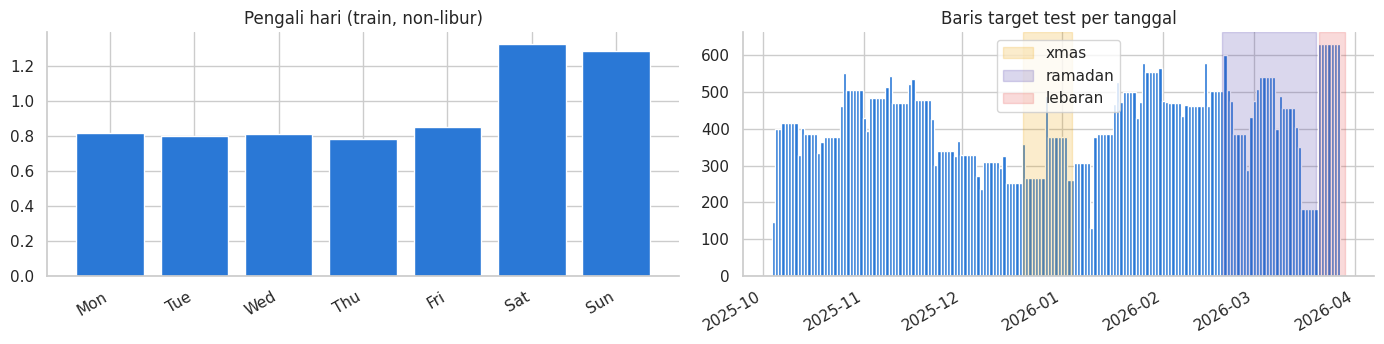

In [9]:
DOW = ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']
x = train.set_index('date_show').groupby(KEY).total_ticket.apply(lambda s: s.asfreq('D', fill_value=0)).reset_index()
x['m7'] = x.groupby(KEY).total_ticket.transform(lambda s: s.rolling(7, center=True).mean())
x = x[(x.m7 >= 20) & ~x.date_show.isin(CFG.OUTAGE)].merge(hol, left_on='date_show', right_on='date', how='left')
x['mult'] = x.total_ticket / x.m7
day = x.groupby('date_show').agg(mult=('mult', 'median'), hol=('holiday_tipe', 'first'), name=('holiday_name', 'first'))
day['dow'] = day.index.dayofweek
prof = day[day.hol == 'normal'].groupby('dow').mult.median()
day['excess'] = day.mult / day.dow.map(prof)
print('weekday multiplier:', dict(zip(DOW, prof.round(3))))
display(day[day.hol == 'holiday'][['name', 'dow', 'excess']].round(2))

SEGMENTS = {'xmas': ('2025-12-20', '2026-01-04'), 'ramadan': ('2026-02-19', '2026-03-20'), 'lebaran': ('2026-03-21', '2026-03-29')}
for n, (a, b) in SEGMENTS.items():
    m = test.date_show.between(a, b)
    print(f'{n:8s} test rows {m.sum():6d} ({m.mean():.1%}), films {test[m].movie_title.nunique()}')

fig, ax = plt.subplots(1, 2, figsize=(14, 3.6))
ax[0].bar(DOW, prof.values, color=PAL[0]); ax[0].set(title='Pengali hari (train, non-libur)')
cnt = test.groupby('date_show').size()
ax[1].bar(cnt.index, cnt.values, width=1, color=PAL[0])
for (n, (a, b)), c in zip(SEGMENTS.items(), [PAL[3], PAL[6], PAL[7]]):
    ax[1].axvspan(pd.Timestamp(a), pd.Timestamp(b), color=c, alpha=.2, label=n)
ax[1].set(title='Baris target test per tanggal'); ax[1].legend()
fig.autofmt_xdate(); plt.tight_layout(); plt.savefig(CFG.FIG_DIR / 'calendar.png'); plt.show()

#### Insights

> Sabtu dan Minggu sekitar 1,6 kali hari kerja, libur di hari kerja setara akhir pekan, libur di akhir pekan hampir tidak menambah. Sekitar 30% baris uji berada di periode yang tidak pernah ada di train: Ramadan (17,1%), libur Natal dan Tahun Baru (7,2%), dan Lebaran (6,1%). Efek kalender karena itu dimasukkan secara struktural sebagai pengali target, bukan dipelajari pohon keputusan yang tidak bisa ekstrapolasi.

## Level Pasar dan Ukuran Pasangan

Okupansi median per bulan dan distribusi skala pasangan D1 sampai D3 dibandingkan antara train dan data uji. Skala dihitung dengan rumus resmi pada seluruh pasangan yang laku di D3.

test pairs by scale bucket: {Interval(0.0, 5.0, closed='right'): 0.015, Interval(5.0, 20.0, closed='right'): 0.114, Interval(20.0, 50.0, closed='right'): 0.198, Interval(50.0, 100.0, closed='right'): 0.2, Interval(100.0, 200.0, closed='right'): 0.195, Interval(200.0, 500.0, closed='right'): 0.178, Interval(500.0, 1000000000.0, closed='right'): 0.1}


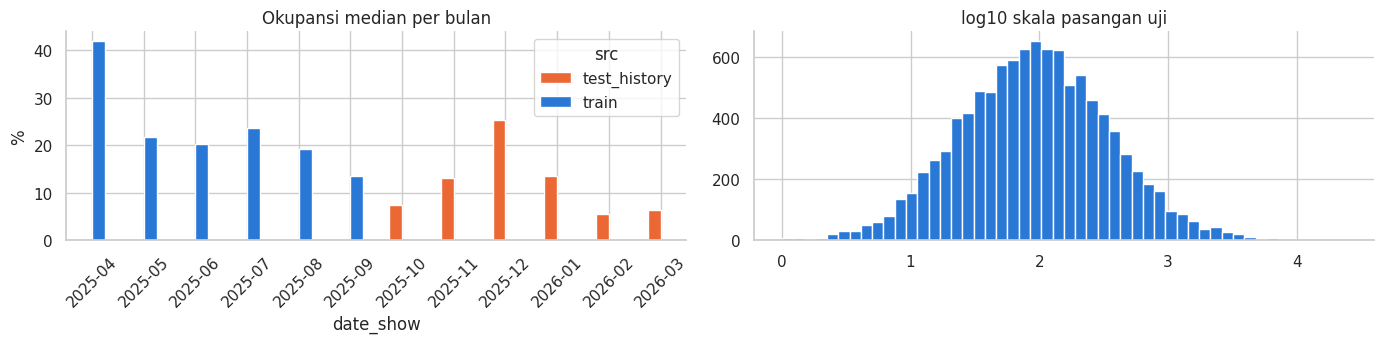

In [10]:
occ = pd.concat([train.assign(src='train'), hist.assign(src='test_history')])
occ_m = occ.groupby([occ.date_show.dt.to_period('M'), 'src']).occupation_rate.median().unstack()
s_te = (hist.groupby(KEY).total_ticket.sum() / 3).clip(lower=1).reindex(pd.MultiIndex.from_frame(test[KEY].drop_duplicates()))
bins = CFG.TW_BINS
print('test pairs by scale bucket:', pd.cut(s_te, bins).value_counts(normalize=True).sort_index().round(3).to_dict())

fig, ax = plt.subplots(1, 2, figsize=(14, 3.6))
occ_m.plot.bar(ax=ax[0], rot=45, color=[PAL[1], PAL[0]]); ax[0].set(title='Okupansi median per bulan', ylabel='%')
ax[1].hist(np.log10(s_te), bins=50, color=PAL[0]); ax[1].set(title='log10 skala pasangan uji')
plt.tight_layout(); plt.savefig(CFG.FIG_DIR / 'market.png'); plt.show()

#### Insights

> Okupansi median Oktober 2025 (7,6%), Februari (5,5%), dan Maret 2026 (6,4%) berada di bawah semua bulan train (13,6% sampai 41,8%). Pasar periode uji jauh lebih sepi, sehingga pasangan uji jauh lebih kecil: 13% baris uji memiliki skala di bawah 20. Konsekuensinya diukur di Bagian 6 dan Bagian 8.

---

# Data Cleaning <a name="5"></a>

---

Target dibentuk dengan zero-fill, sehingga hari ketika sistem pelaporan mati akan menjadi nol palsu. Selain itu, akhir pekan pratinjau berbayar sebelum rilis resmi dapat terbaca sebagai D1. Pemeriksaan memakai dua ukuran jaringan per hari: jumlah klaster yang melapor dan total pertunjukan semua film. Kapasitas tayang jaringan sangat stabil (median koefisien variasi harian per klaster 0,06), sehingga penurunan serentak pertunjukan adalah tanda gangguan pencatatan walaupun klaster masih melapor.

dates with no data: [datetime.date(2025, 6, 13)]
dates with < 70% of clusters reporting: {Timestamp('2025-06-07 00:00:00'): 10.0, Timestamp('2025-06-09 00:00:00'): 1.0, Timestamp('2025-06-10 00:00:00'): 67.0, Timestamp('2025-06-11 00:00:00'): 76.0, Timestamp('2025-06-16 00:00:00'): 62.0}
dates with < 70% of the usual network shows: [datetime.date(2025, 6, 1), datetime.date(2025, 6, 2), datetime.date(2025, 6, 3), datetime.date(2025, 6, 4), datetime.date(2025, 6, 5), datetime.date(2025, 6, 6), datetime.date(2025, 6, 7), datetime.date(2025, 6, 8), datetime.date(2025, 6, 9), datetime.date(2025, 6, 10), datetime.date(2025, 6, 11), datetime.date(2025, 6, 12), datetime.date(2025, 6, 14), datetime.date(2025, 6, 15), datetime.date(2025, 6, 16)]
31 May -> 1 Jun: shows 6272 -> 2044, tickets 311321 -> 87403, clusters 116 -> 114
A MINECRAFT MOVIE coverage 1-10 Apr: {Timestamp('2025-04-04 00:00:00'): 55, Timestamp('2025-04-05 00:00:00'): 68, Timestamp('2025-04-06 00:00:00'): 67, Timestamp('2025-04-0

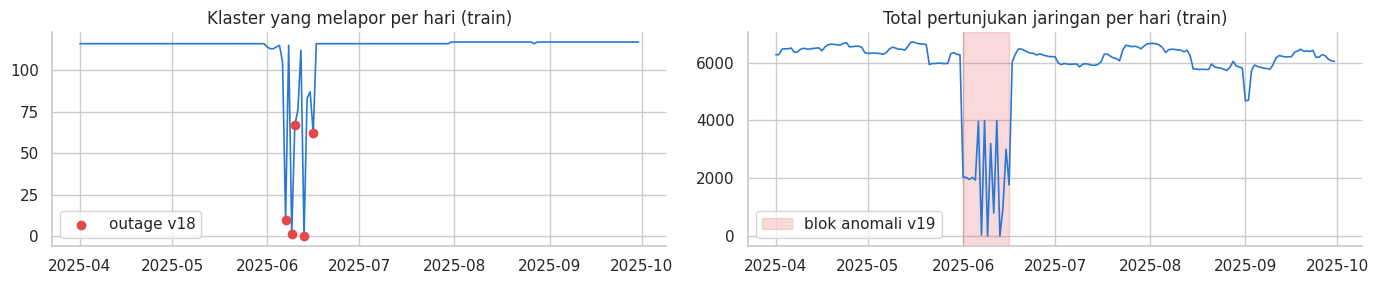

In [11]:
net = train.groupby('date_show').agg(clusters=('cinema_ids', 'nunique'), shows=('total_show', 'sum'), tickets=('total_ticket', 'sum'))
net = net.reindex(pd.date_range('2025-04-01', CFG.TRAIN_END))
print('dates with no data:', net[net.clusters.isna()].index.date.tolist())
print('dates with < 70% of clusters reporting:', net.clusters[net.clusters < 0.7 * net.clusters.median()].to_dict())
low_shows = net.shows < 0.7 * net.shows.median()
print('dates with < 70% of the usual network shows:', net.index[low_shows.values].date.tolist())
sat_sun = net.loc['2025-05-31':'2025-06-01']
print(f"31 May -> 1 Jun: shows {int(sat_sun.shows.iloc[0])} -> {int(sat_sun.shows.iloc[1])}, "
      f"tickets {int(sat_sun.tickets.iloc[0])} -> {int(sat_sun.tickets.iloc[1])}, clusters {int(sat_sun.clusters.iloc[0])} -> {int(sat_sun.clusters.iloc[1])}")
mc = train[train.movie_title == 'A MINECRAFT MOVIE'].groupby('date_show').cinema_ids.nunique()
print('A MINECRAFT MOVIE coverage 1-10 Apr:', mc.loc[:'2025-04-10'].to_dict())
fig, ax = plt.subplots(1, 2, figsize=(14, 3))
ax[0].plot(net.index, net.clusters.fillna(0), lw=1.2)
ax[0].scatter(CFG.OUTAGE_V18, net.clusters.reindex(CFG.OUTAGE_V18).fillna(0), color=PAL[7], zorder=3, label='outage v18')
ax[0].set(title='Klaster yang melapor per hari (train)'); ax[0].legend()
ax[1].plot(net.index, net.shows.fillna(0), lw=1.2)
ax[1].axvspan(CFG.OUTAGE.min(), CFG.OUTAGE.max(), color=PAL[7], alpha=.2, label='blok anomali v19')
ax[1].set(title='Total pertunjukan jaringan per hari (train)'); ax[1].legend()
plt.tight_layout(); plt.savefig(CFG.FIG_DIR / 'outage.png'); plt.show()

#### Insights

> Lima tanggal Juni 2025 adalah outage pelaporan (13 Juni kosong, 9 Juni hanya 1 klaster) dan sudah dibuang sejak v3. Pemeriksaan jumlah pertunjukan menemukan anomali yang lebih panjang: dari Sabtu 31 Mei ke Minggu 1 Juni, total pertunjukan jaringan turun dari 6.272 ke 2.044 dan tiket dari 311 ribu ke 87 ribu, sementara klaster yang melapor hanya turun dari 116 ke 114. Pada 112 dari 114 klaster, pertunjukan 1 Juni paling banyak separuh 31 Mei, padahal dua pasangan Sabtu-Minggu pembanding (24 ke 25 Mei, 21 ke 22 Juni) tidak berubah. Pertunjukan baru pulih ke sekitar 6.000 pada 17 Juni.

> Karena itu `OUTAGE` diperluas menjadi seluruh 1 sampai 16 Juni: baris target di blok ini dibuang, dan film yang D1 sampai D3-nya menyentuh blok tidak dijadikan sampel. Penurunan pertunjukan nyata tetap mungkin, tetapi keserempakan di seluruh jaringan membuat tafsiran permintaan biasa lemah. Dampaknya pada label diperiksa setelah simulasi sampel di Bagian 6. A MINECRAFT MOVIE memiliki pratinjau 4 sampai 6 April lalu jeda sebelum rilis resmi 9 April: D1 dicari hanya di dalam segmen tayang kontinu yang memuat puncak cakupan.

---

# Preprocessing <a name="6"></a>

---

`train.csv` tidak memiliki penanda D1 sampai D10. Aturan panitia direplikasi: D1 rilis resmi, rilis luas, pasangan laku di D3, target nol diisi eksplisit. Hasilnya diverifikasi terhadap data uji, termasuk dengan tugas proxy yang memiliki label di dalam periode uji.

## Rekonstruksi D1 dan Simulasi Sampel

D1 adalah hari pertama cakupan klaster judul dasar mencapai 50% puncak, dicari di dalam segmen tayang kontinu yang memuat puncak. Judul dengan cakupan D1 di bawah 25 klaster dipisahkan sebagai film rilis terbatas: tidak pernah dievaluasi, tetapi dipakai sebagai data latih tambahan untuk pasangan kecil.

In [12]:
def release_dates(tx, frac=CFG.D1_FRAC, min_nc=CFG.MIN_NC):
    x = tx.assign(base=base_title(tx.movie_title))
    nc = x.groupby(['base', 'date_show']).cinema_ids.nunique()
    out = {}
    for b, s in nc.groupby(level=0):
        s = s.droplevel(0)
        s = s.reindex(pd.date_range(s.index.min(), s.index.max()), fill_value=0)
        pk = s.idxmax()
        z = s[:pk][s[:pk] == 0]
        seg = s[z.index.max() + pd.Timedelta(days=1):] if len(z) else s
        c = seg[seg >= frac * s.max()]
        if len(c) and c.iloc[0] >= min_nc:
            out[b] = c.index[0]
    t = x.drop_duplicates('movie_title').set_index('movie_title').base
    return t.map(pd.Series(out, dtype='datetime64[ns]')).dropna().rename('d1')


def simulate(tx, d1, last_date=CFG.TRAIN_END, bad=CFG.OUTAGE):
    d1 = d1[d1 + pd.Timedelta(days=9) <= last_date]
    if len(bad):
        d1 = d1[~np.any([(d1 <= b) & (d1 + pd.Timedelta(days=2) >= b) for b in bad], axis=0)]
    x = tx.merge(d1, left_on='movie_title', right_index=True)
    x['d'] = (x.date_show - x.d1).dt.days + 1
    hs = x[x.d.between(1, 3)].drop(columns=['d1', 'd']).reset_index(drop=True)
    pairs = x.loc[x.d == 3, KEY].drop_duplicates().merge(d1, left_on='movie_title', right_index=True)
    tg = pairs.loc[pairs.index.repeat(7)].copy()
    tg['date_show'] = tg.d1 + pd.to_timedelta(np.tile(np.arange(3, 10), len(pairs)), unit='D')
    y = x[x.d.between(4, 10)][KEY + ['date_show', 'total_ticket']]
    tg = tg.merge(y, on=KEY + ['date_show'], how='left').fillna({'total_ticket': 0})
    tg = tg[~tg.date_show.isin(bad)]
    tg['city_name'] = tg.cinema_ids.map(tx.drop_duplicates('cinema_ids').set_index('cinema_ids').city_name)
    return hs, tg.drop(columns='d1').reset_index(drop=True)


def pair_scale(h):
    return (h.groupby(KEY).total_ticket.sum() / 3).clip(lower=1).rename('scale')


def mase(y, p, s):
    return float(np.mean(np.abs(np.asarray(y) - np.asarray(p)) / np.asarray(s)))


first = train.groupby('movie_title').date_show.min()
running = first[first == first.min()].index
D_wide = release_dates(train)
D_lim = release_dates(train, CFG.D1_FRAC, 0).drop(D_wide.index, errors='ignore').drop(running, errors='ignore')
hs, ts = simulate(train, D_wide.drop(running, errors='ignore'))
hl, tl = simulate(train, D_lim)
print(f'wide releases: {ts.movie_title.nunique()} films, {len(ts)} target rows | limited (train only): {tl.movie_title.nunique()} films, {len(tl)} rows')
print('A MINECRAFT MOVIE D1:', D_wide['A MINECRAFT MOVIE'].date())

wide releases: 141 films, 54314 target rows | limited (train only): 36 films, 1433 rows
A MINECRAFT MOVIE D1: 2025-04-09


Fungsi `simulate` diuji pada film sintetis: klaster B tidak laku di D3 sehingga harus dibuang, dan hari tanpa transaksi harus menjadi nol.

In [13]:
dd = pd.date_range('2025-05-01', periods=12)
toy = pd.DataFrame({'date_show': list(dd) + [dd[0], dd[1]], 'cinema_ids': ['A'] * 12 + ['B', 'B'], 'city_name': 'X',
                    'movie_title': 'M', 'total_ticket': list(range(1, 13)) + [5, 5], 'occupation_rate': 1.0,
                    'total_show': 1}).drop(index=5)
th_, tg_ = simulate(toy, pd.Series({'M': dd[0]}, name='d1'), bad=pd.DatetimeIndex([]))
assert set(tg_.cinema_ids) == {'A'} and tg_.total_ticket.tolist() == [4, 5, 0, 7, 8, 9, 10]
assert np.isclose(pair_scale(th_)[('M', 'B')], 10 / 3)
print('simulate() self-check passed')

simulate() self-check passed


#### Insights

> Aturan D1 memakai puncak cakupan sepanjang riwayat film, yaitu informasi masa depan. Audit lokal (`eda/53`) membandingkannya dengan aturan yang benar-benar kausal: D1 = hari pertama yang jendela D1 sampai D3-nya sendiri memiliki minimal 25 klaster setiap hari, tanpa melihat puncak. Aturan itu memindahkan 6 film (A MINECRAFT MOVIE ke pratayang berbayar 4 April, BELIEVE 20 hari lebih awal), mengubah skala 191 pasangan bersama (varian yang masih memakai segmen puncak: 125), dan membuang 15 film yang dibuka di minimal 25 klaster lalu runtuh di D2 sampai D3 (rasio cakupan D3/D1 median 0,34, misalnya ARTI CINTA 52 menjadi 2 klaster). Jarak KS rasio cakupan ke data uji memang turun (0,196 menjadi 0,106), tetapi hanya karena ekor bawah itu dibuang.

> Data uji justru memuat pembukaan yang runtuh seperti itu: 8 film uji punya hari dengan kurang dari 25 klaster (SEND HELP 52, 49, lalu 1 klaster; G-DRAGON IN CINEMA 55, 30, 3) dan 30 film uji memiliki rasio cakupan D3/D1 di bawah 0,8. Seleksi panitia karena itu konsisten dengan aturan cakupan D1 (aturan sekarang), bukan dengan syarat jendela lebar tiga hari. Aturan D1 dipertahankan dengan dasar ini, bukan karena perubahannya kecil.

## Verifikasi: Label yang Dibuang oleh Blok Anomali Juni

Simulasi diulang dengan lima tanggal outage lama (`OUTAGE_V18`) untuk melihat baris target yang kini dibuang. Bila blok itu memang gangguan pencatatan, baris yang dibuang harus jauh lebih rendah dari baris lain pada horizon yang sama: label turun palsu yang mengajari model bahwa film meluruh lebih cepat setelah D3.

target rows v18 rule 56372 | v19 rule 54314 | removed 2058 from 5 titles
removed rows by title: {'BALLERINA': 294, 'DENDAM MALAM KELAM': 336, 'KARATE KID: LEGENDS': 648, 'THE RITUAL': 162, 'WAKTU MAGHRIB 2': 618}


,removed median r,kept median r,removed zero share,kept zero share,removed rows
h,,,,,
4,0.048,0.953,0.481,0.078,27
5,0.293,0.689,0.196,0.122,392
6,0.131,0.505,0.238,0.189,294
7,0.112,0.401,0.235,0.270,294
8,0.000,0.211,0.515,0.407,392
9,0.000,0.073,0.564,0.489,392
10,0.000,0.000,0.547,0.525,267


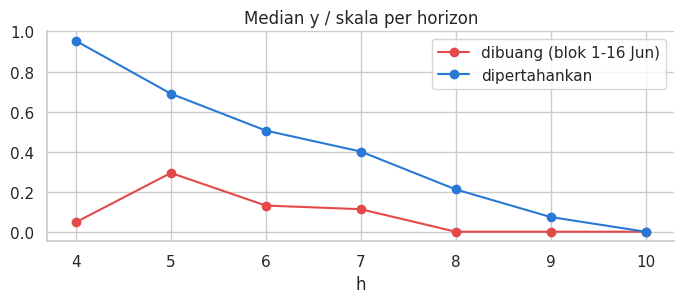

In [14]:
hs_old, ts_old = simulate(train, D_wide.drop(running, errors='ignore'), bad=CFG.OUTAGE_V18)
k_old = ts_old.assign(h=(ts_old.date_show - ts_old.movie_title.map(D_wide)).dt.days + 1).join(pair_scale(hs_old), on=KEY)
gone = ~k_old.set_index(KEY + ['date_show']).index.isin(ts.set_index(KEY + ['date_show']).index)
k_old['r'] = k_old.total_ticket / k_old.scale
print(f'target rows v18 rule {len(ts_old)} | v19 rule {len(ts)} | removed {int(gone.sum())} from {k_old.movie_title[gone].nunique()} titles')
print('removed rows by title:', k_old[gone].groupby('movie_title').size().to_dict())
chk = pd.DataFrame({'removed median r': k_old[gone].groupby('h').r.median(), 'kept median r': k_old[~gone].groupby('h').r.median(),
                    'removed zero share': k_old[gone].groupby('h').total_ticket.apply(lambda v: (v == 0).mean()),
                    'kept zero share': k_old[~gone].groupby('h').total_ticket.apply(lambda v: (v == 0).mean()),
                    'removed rows': k_old[gone].groupby('h').size()})
display(chk.round(3))
assert not ts.date_show.isin(CFG.OUTAGE).any(), 'no target row may fall inside the anomaly block'
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.plot(chk.index, chk['removed median r'], marker='o', color=PAL[7], label='dibuang (blok 1-16 Jun)')
ax.plot(chk.index, chk['kept median r'], marker='o', color=PAL[0], label='dipertahankan')
ax.set(title='Median y / skala per horizon', xlabel='h'); ax.legend()
plt.tight_layout(); plt.savefig(CFG.FIG_DIR / 'june_block_labels.png'); plt.show()

#### Insights

> Analisis lokal (`eda/126`) memprediksi sekitar 2.058 baris target dari lima judul (KARATE KID: LEGENDS, WAKTU MAGHRIB 2, DENDAM MALAM KELAM, BALLERINA, THE RITUAL) dibuang, dengan median $y/s$ 0,05 sampai 0,29 pada horizon 4 sampai 7 dibanding 0,44 sampai 0,98 pada baris yang dipertahankan. Tabel di atas mengulang pemeriksaan itu di notebook. Hasilnya sesuai harapan teori: baris di blok anomali adalah label turun palsu, bukan perilaku penonton, sehingga membuangnya adalah pembersihan data, bukan pemilihan baris yang mudah.

> Karena baris yang dibuang ikut keluar dari populasi validasi, TW-MASE v19 tidak dapat dibandingkan langsung dengan v18. Perbandingan yang adil dilakukan pada baris yang ada di kedua versi.

## Label Partial-Window yang Sudah Teramati

`simulate` membuang film yang D10-nya melewati akhir data latih, karena target D4 sampai D10 tidak lengkap. Untuk validasi itu benar, tetapi untuk data latih terlalu ketat: D4 sampai D7 film yang dirilis pada pekan terakhir September sudah teramati. `observed_partial` membentuk sampel dengan aturan panitia yang sama untuk film yang D1 sampai D3-nya selesai sebelum cutoff, lalu hanya menyimpan target pada tanggal yang sudah lewat (tidak ada nol palsu untuk hari yang belum terjadi). Pemeriksaan: label sama persis dengan transaksi mentah, tidak ada kunci yang tumpang tindih dengan sampel utama, tidak ada tanggal setelah cutoff, dan film sintetis yang dipotong di D8 hanya menghasilkan target D4 sampai D8.

In [15]:
def observed_partial(tx, anchors, cutoff):
    elig = anchors[(anchors + pd.Timedelta(days=2) <= cutoff) & (anchors + pd.Timedelta(days=9) > cutoff)]
    hp_, tp_ = simulate(tx[tx.date_show <= cutoff], elig, last_date=cutoff + pd.Timedelta(days=9))
    return hp_, tp_[tp_.date_show <= cutoff].reset_index(drop=True)


ANCHORS = D_wide.drop(running, errors='ignore')
hp, tp = observed_partial(train, ANCHORS, CFG.TRAIN_END)
chk_ = tp.merge(train[KEY + ['date_show', 'total_ticket']], on=KEY + ['date_show'], how='left', suffixes=('', '_raw'))
assert np.array_equal(chk_.total_ticket.values, chk_.total_ticket_raw.fillna(0).values)
assert not pd.MultiIndex.from_frame(tp[KEY + ['date_show']]).isin(pd.MultiIndex.from_frame(ts[KEY + ['date_show']])).any()
assert (tp.date_show <= CFG.TRAIN_END).all() and not tp.date_show.isin(CFG.OUTAGE).any()
dd8 = pd.date_range('2025-08-01', periods=8)
toy8 = pd.DataFrame({'movie_title': 'toy', 'cinema_ids': 'c', 'city_name': 'x', 'date_show': dd8, 'total_ticket': np.arange(1, 9),
                     'occupation_rate': 10.0, 'total_show': 1})
_, tq_ = observed_partial(toy8, pd.Series({'toy': dd8[0]}, name='d1'), dd8[-1])
assert tq_.total_ticket.tolist() == [4, 5, 6, 7, 8], 'right-censored days must be absent, never zero'
PART_D1 = tp.movie_title.map(ANCHORS)
PART_H = (tp.date_show - PART_D1).dt.days + 1
print('observed_partial checks passed (raw labels, no overlap, no future dates, toy censoring)')
display(tp.assign(base=base_title(tp.movie_title), h=PART_H).groupby('base').agg(rows=('h', 'size'), pairs=('cinema_ids', 'nunique'),
                                                                               h_max=('h', 'max'), zero_share=('total_ticket', lambda v: (v == 0).mean())))
print('extra rows by horizon:', PART_H.value_counts().sort_index().to_dict(), '| main rows per horizon:', len(ts) // 7)

observed_partial checks passed (raw labels, no overlap, no future dates, toy censoring)


,rows,pairs,h_max,zero_share
base,,,,
CHAINSAW MAN - THE MOVIE: REZE ARC,190,80,5,0.036842
DIA BUKAN IBU,252,84,6,0.095238
DILANJUTKAN SALAH DISUDAHI PERIH,162,54,6,0.092593
GABBYS DOLLHOUSE: THE MOVIE,74,37,5,0.324324
KANG SOLAH FROM KANG MAK X NENEK GAYUNG,333,111,6,0.000000
ONE BATTLE AFTER ANOTHER,392,82,7,0.073980


extra rows by horizon: {4: 479, 5: 479, 6: 347, 7: 98} | main rows per horizon: 7759


#### Insights

> Audit lokal (`eda/108`) menemukan 1.403 label tambahan dari enam film rilis akhir September (D4 +479, D5 +479, D6 +347, D7 +98; tidak ada D8 sampai D10), sekitar 6% tambahan pada D4 dan D5, horizon dengan galat terbesar. Label ini asli, bukan simulasi, tetapi tetap ditambahkan hanya ke data latih: film yang belum lengkap tidak pernah menjadi film validasi, dan semua film dalam satu minggu rilis tetap di fold yang sama. Pasangan berskala kecil hanya sekitar 2% dari label ini (uji 13%), jadi manfaatnya, bila ada, terutama di pasangan besar.

## Verifikasi: Komposisi dan Periode Uji

Sampel simulasi dibandingkan dengan data uji. Karena target uji tidak tersedia, dibuat tugas proxy yang memiliki label di **dalam periode uji**: memprediksi D3 dari D1 dan D2. Model proxy dilatih pada train, lalu galatnya per bucket skala dibandingkan antara validasi silang train dan periode uji.

,train_share,test_share,train_cv_mase,test_period_mase,train_zero_D3,test_zero_D3
s,,,,,,
"(0.0, 5.0]",0.004,0.024,1.089,1.168,0.771,0.544
"(5.0, 20.0]",0.053,0.134,0.649,0.691,0.575,0.308
"(20.0, 50.0]",0.133,0.208,0.543,0.592,0.394,0.107
"(50.0, 100.0]",0.172,0.195,0.482,0.484,0.129,0.028
"(100.0, 200.0]",0.217,0.185,0.385,0.413,0.030,0.011
"(200.0, 500.0]",0.250,0.160,0.326,0.348,0.003,0.002
"(500.0, 1000000000.0]",0.172,0.093,0.342,0.287,0.001,0.000


proxy MASE: train CV 0.4174 | re-weighted to test scale mix 0.4760 | real test period 0.4977


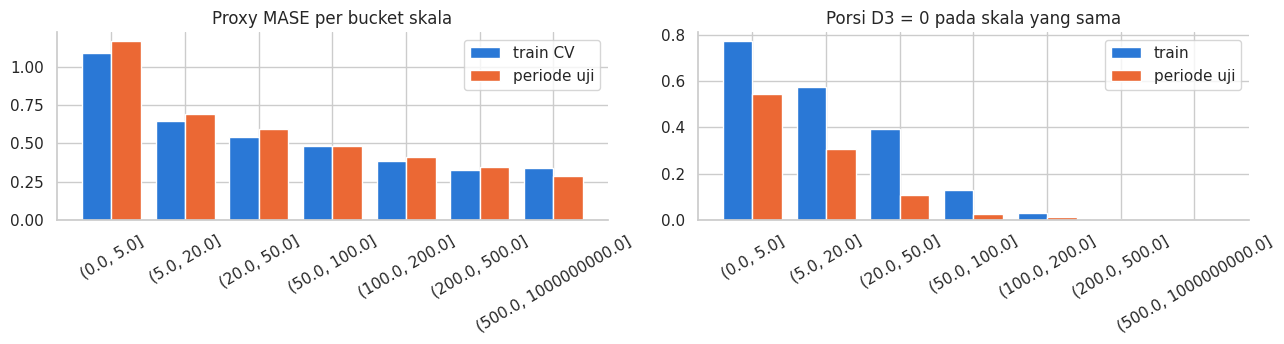

In [16]:
def proxy(hh):
    d1 = hh.groupby('movie_title').date_show.min().rename('d1')
    x = hh.join(d1, on='movie_title')
    x['d'] = (x.date_show - x.d1).dt.days + 1
    P = x.pivot_table(index=KEY, columns='d', values='total_ticket', fill_value=0).reindex(columns=[1, 2, 3], fill_value=0)
    S = x.pivot_table(index=KEY, columns='d', values='total_show', fill_value=0).reindex(columns=[1, 2], fill_value=0)
    O = x.pivot_table(index=KEY, columns='d', values='occupation_rate', fill_value=0).reindex(columns=[1, 2], fill_value=0)
    P = P[P[2] > 0]
    f = pd.DataFrame({'s': ((P[1] + P[2]) / 2).clip(lower=1), 'y': P[3]}, index=P.index)
    f['q1'], f['q2'], f['log_s'] = P[1] / f.s, P[2] / f.s, np.log1p(f.s)
    f['sh1'], f['sh2'] = S.reindex(P.index)[1], S.reindex(P.index)[2]
    f['sh_tr'] = (f.sh2 + 1) / (f.sh1 + 1)
    f['occ2'] = O.reindex(P.index)[2]
    f = f.reset_index().join(d1, on='movie_title')
    g = x[x.d <= 2].groupby(['movie_title', 'd']).total_ticket.sum().unstack().reindex(columns=[1, 2], fill_value=0)
    f['f_tr'] = f.movie_title.map((g[2] + 1) / (g[1] + 1))
    f['f_log'] = f.movie_title.map(np.log1p(g.mean(axis=1)))
    f['f_nc'] = f.movie_title.map(x[x.d == 2].groupby('movie_title').cinema_ids.nunique())
    f['d1_dow'] = f.d1.dt.dayofweek
    return f


PA, PB = proxy(hs), proxy(hist)
pc = ['q1', 'q2', 'log_s', 'sh_tr', 'f_tr', 'f_log', 'd1_dow']
pm = dict(objective='l1', n_estimators=400, learning_rate=0.03, num_leaves=31, min_child_samples=100, verbose=-1, deterministic=True, force_row_wise=True)
oofA = np.zeros(len(PA))
for a, b in GroupKFold(5).split(PA, groups=base_title(PA.movie_title)):
    m = lgb.LGBMRegressor(**pm, random_state=CFG.SEED).fit(PA.iloc[a][pc], PA.y.iloc[a] / PA.s.iloc[a])
    oofA[b] = np.clip(m.predict(PA.iloc[b][pc]), 0, None) * PA.s.values[b]
m = lgb.LGBMRegressor(**pm, random_state=CFG.SEED).fit(PA[pc], PA.y / PA.s)
pB = np.clip(m.predict(PB[pc]), 0, None) * PB.s.values
eA, eB = np.abs(PA.y - oofA) / PA.s, np.abs(PB.y - pB) / PB.s
cutA, cutB = pd.cut(PA.s, bins), pd.cut(PB.s, bins)
tab = pd.DataFrame({'train_share': cutA.value_counts(normalize=True), 'test_share': cutB.value_counts(normalize=True),
                    'train_cv_mase': eA.groupby(cutA, observed=False).mean(), 'test_period_mase': eB.groupby(cutB, observed=False).mean(),
                    'train_zero_D3': (PA.y == 0).groupby(cutA, observed=False).mean(), 'test_zero_D3': (PB.y == 0).groupby(cutB, observed=False).mean()}).sort_index()
display(tab.round(3))
print(f'proxy MASE: train CV {eA.mean():.4f} | re-weighted to test scale mix {(tab.test_share * tab.train_cv_mase).sum():.4f} | real test period {eB.mean():.4f}')

fig, ax = plt.subplots(1, 2, figsize=(13, 3.6))
xx = np.arange(len(tab))
ax[0].bar(xx - .2, tab.train_cv_mase, .4, label='train CV'); ax[0].bar(xx + .2, tab.test_period_mase, .4, label='periode uji')
ax[0].set_xticks(xx, [str(i) for i in tab.index], rotation=30); ax[0].set(title='Proxy MASE per bucket skala'); ax[0].legend()
ax[1].bar(xx - .2, tab.train_zero_D3, .4, label='train'); ax[1].bar(xx + .2, tab.test_zero_D3, .4, label='periode uji')
ax[1].set_xticks(xx, [str(i) for i in tab.index], rotation=30); ax[1].set(title='Porsi D3 = 0 pada skala yang sama'); ax[1].legend()
plt.tight_layout(); plt.savefig(CFG.FIG_DIR / 'proxy.png'); plt.show()

#### Insights

> Galat per bucket skala hampir sama antara validasi silang train dan periode uji, tetapi data uji memuat jauh lebih banyak pasangan kecil yang galatnya terbesar. Karena itu metrik keputusan adalah **TW-MASE**. TW-MASE v2 (0,377) dan v3 (0,388) memberi peringkat yang sama dengan leaderboard (0,4506 dan 0,4573), tetapi keduanya berjarak tetap sekitar 0,07.

> Pada skala absolut yang sama, porsi pasangan yang berhenti di D3 jauh lebih kecil di periode uji (skala 20 sampai 50: 0,39 di train vs 0,11 di uji). Bagian berikut menguji apakah ini efek musim atau perubahan perilaku bioskop.

## Kebijakan Pencopotan di Periode Uji

Porsi pasangan yang berhenti laku di D3 dibandingkan pada **permintaan per pertunjukan yang sama** (tiket per show D1 sampai D2), sehingga perbedaan ukuran pasar tidak ikut terhitung. Besarnya pergeseran diestimasi di Bagian 8 setelah kalender tersedia.

,train_drop_D3,test_drop_D3,train_n,test_n
"(0.226, 7.778]",0.500,0.220,940,3053
"(7.778, 14.8]",0.257,0.063,1380,2619
"(14.8, 25.2]",0.082,0.030,1773,2224
"(25.2, 44.923]",0.022,0.014,2272,1704
"(44.923, 425.167]",0.002,0.005,2517,1474


D3 stop rate by release month: {Period('2025-04', 'M'): 0.082, Period('2025-05', 'M'): 0.13, Period('2025-06', 'M'): 0.174, Period('2025-07', 'M'): 0.083, Period('2025-08', 'M'): 0.137, Period('2025-09', 'M'): 0.096, Period('2025-10', 'M'): 0.096, Period('2025-11', 'M'): 0.08, Period('2025-12', 'M'): 0.062, Period('2026-01', 'M'): 0.081, Period('2026-02', 'M'): 0.107, Period('2026-03', 'M'): 0.066}


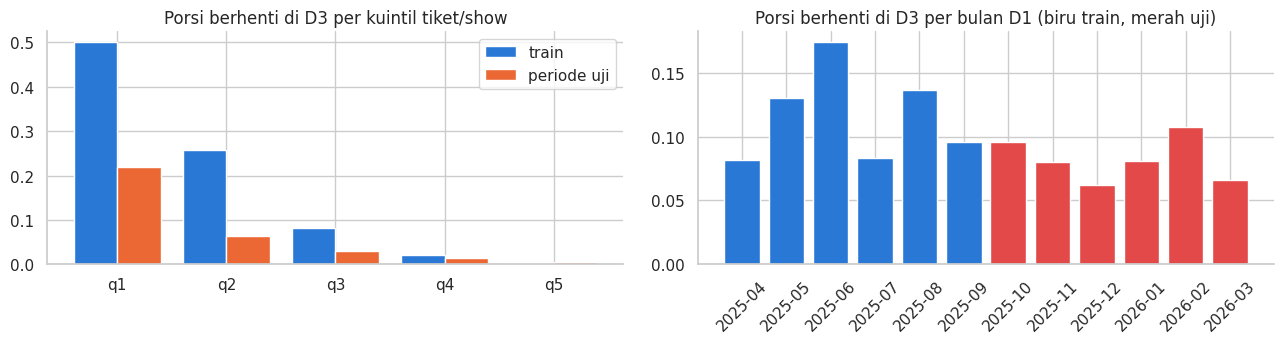

In [17]:
DA = PA.assign(z=PA.y == 0, tps=PA.s * 2 / (PA.sh1 + PA.sh2).clip(lower=1))
DB = PB.assign(z=PB.y == 0, tps=PB.s * 2 / (PB.sh1 + PB.sh2).clip(lower=1))
q = pd.qcut(pd.concat([DA.tps, DB.tps]), 5)
qa, qb = q.iloc[:len(DA)].values, q.iloc[len(DA):].values
tq = pd.DataFrame({'train_drop_D3': DA.z.groupby(qa, observed=False).mean(), 'test_drop_D3': DB.z.groupby(qb, observed=False).mean(),
                   'train_n': pd.Series(qa).value_counts(), 'test_n': pd.Series(qb).value_counts()})
display(tq.round(3))
zm = pd.concat([DA.assign(m=DA.d1.dt.to_period('M')), DB.assign(m=DB.d1.dt.to_period('M'))]).groupby('m').z.mean()
print('D3 stop rate by release month:', zm.round(3).to_dict())

fig, ax = plt.subplots(1, 2, figsize=(13, 3.6))
xx = np.arange(len(tq))
ax[0].bar(xx - .2, tq.train_drop_D3, .4, label='train'); ax[0].bar(xx + .2, tq.test_drop_D3, .4, label='periode uji')
ax[0].set_xticks(xx, [f'q{i + 1}' for i in xx]); ax[0].set(title='Porsi berhenti di D3 per kuintil tiket/show'); ax[0].legend()
ax[1].bar(zm.index.astype(str), zm.values, color=[PAL[0] if str(m) < '2025-10' else PAL[7] for m in zm.index])
ax[1].set(title='Porsi berhenti di D3 per bulan D1 (biru train, merah uji)'); ax[1].tick_params(axis='x', rotation=45)
plt.tight_layout(); plt.savefig(CFG.FIG_DIR / 'pull_policy.png'); plt.show()

#### Insights

> Pada tiket per show absolut yang sama, porsi pasangan yang berhenti di D3 di periode uji hanya sekitar setengah sampai seperempat porsi train. Sejak v4 ini dibaca sebagai perubahan kebijakan bioskop dan dikoreksi dengan $\lambda a$. Tetapi porsi berhenti per bulan tetap 5 sampai 17% di kedua periode walaupun okupansi periode uji turun ke separuhnya (Februari 2026: okupansi median 5%, porsi berhenti tetap sekitar 10%). Ambang absolut yang konstan tidak menghasilkan pola itu; bagian berikut menguji penjelasan lain.

> Di train, kecenderungan klaster mencopot di D3 juga hampir tidak terbawa ke nol D4 sampai D10: klaster yang 1 logit lebih "lengket" di D3 hanya 0,09 logit lebih lengket di D4 sampai D10 setelah koreksi reliabilitas (`eda/67`, 116 klaster). Jadi besar pergeseran di D3 tidak bisa dipindahkan begitu saja ke horizon target.

## Tolok Ukur Relatif: Pergeseran Kebijakan atau Pasar yang Sepi?

Bila bioskop memutuskan mencopot film berdasarkan kinerjanya **dibanding film lain di bioskop yang sama**, maka di pasar yang sepi semua film terlihat kecil secara absolut, tetapi yang dicopot tetap yang paling lemah secara relatif. Tiket per show setiap pasangan dibagi median tiket per show film lain di klaster yang sama yang D1-nya berjarak paling jauh 14 hari. Referensi hanya memakai jendela D1 sampai D3 film lain (train dan `test_history`), informasi yang sama di kedua periode. Tabel lookup desil dibangun dari train, lalu offset logit periode uji dihitung untuk kedua tolok ukur.

,test_pairs,expected_test,observed_test,logit_offset
absolute tickets/show,11074.0,0.220,0.085,-1.31
tickets/show vs other films in cluster,11066.0,0.114,0.085,-0.43


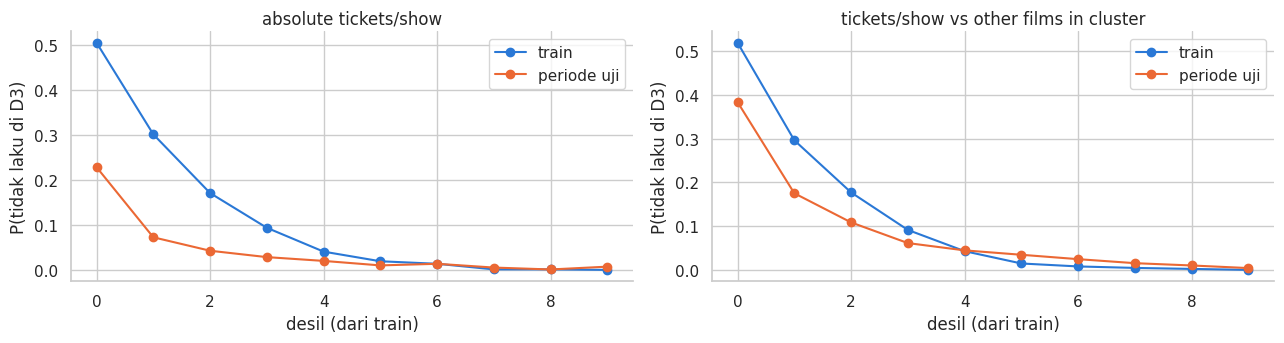

In [18]:
def visible_windows(tx, d1):
    x = tx.merge(d1.rename('d1'), left_on='movie_title', right_index=True)
    return x[(x.date_show >= x.d1) & (x.date_show <= x.d1 + pd.Timedelta(days=2))].drop(columns='d1')


vis_tr = visible_windows(train, D_wide)
VIS = pd.concat([vis_tr, hist], ignore_index=True)
VIS['base'] = base_title(VIS.movie_title)
VIS_D1 = VIS.groupby('base').date_show.min().rename('d1')
VP = VIS.groupby(['base', 'cinema_ids']).agg(tix=('total_ticket', 'sum'), shows=('total_show', 'sum')).reset_index().join(VIS_D1, on='base')
VP['sc'], VP['tps'] = VP.tix / 3, VP.tix / VP.shows.clip(lower=1)
VF = (VIS.groupby('base').total_ticket.sum() / 3).rename('ft').to_frame().join(VIS_D1).reset_index()


def ref_cluster(Q, col, win=CFG.REL_WIN, min_n=2):
    q = Q[['movie_title', 'cinema_ids', 'd1']].drop_duplicates()
    q = q.assign(base=base_title(q.movie_title))
    m = q.merge(VP[['base', 'cinema_ids', 'd1', col]].rename(columns={'base': 'base_o', 'd1': 'd1_o'}), on='cinema_ids')
    m = m[((m.d1 - m.d1_o).dt.days.abs() <= win) & (m.base != m.base_o)]
    g = m.groupby(['movie_title', 'cinema_ids'])[col].agg(['median', 'size'])
    med = g['median'].where(g['size'] >= min_n)
    return pd.MultiIndex.from_frame(Q[['movie_title', 'cinema_ids']]).map(med).values.astype(float)


def ref_national(Q, pool, col, win=CFG.REL_WIN):
    fd = Q.drop_duplicates('movie_title').set_index('movie_title').d1
    fb = base_title(pd.Series(fd.index, index=fd.index))
    days = pool.d1.values.astype('datetime64[D]').astype(np.int64)
    out = {}
    for m_, t_ in fd.items():
        k = (np.abs(days - np.datetime64(t_, 'D').astype(np.int64)) <= win) & (pool.base.values != fb[m_])
        out[m_] = np.median(pool[col].values[k])
    return Q.movie_title.map(out).values.astype(float)


logit = lambda p: np.log(p / (1 - p))
sigm = lambda t: 1 / (1 + np.exp(-t))
nll = lambda p, z, a: -np.mean(z * np.log(sigm(logit(p) + a)) + (1 - z) * np.log(1 - sigm(logit(p) + a)))
grid_a = np.linspace(-4, 2, 601)
for D_ in (DA, DB):
    D_['tps_clu'] = D_.tps / ref_cluster(D_, 'tps')


def stop_lookup(col):
    a_, b_ = DA.dropna(subset=[col]), DB.dropna(subset=[col])
    e = np.unique(np.quantile(np.log(a_[col].clip(lower=1e-3)), np.linspace(0, 1, 11)))
    bin_ = lambda D_: np.clip(np.searchsorted(e, np.log(D_[col].clip(lower=1e-3)), side='right') - 1, 0, len(e) - 2)
    look = a_.z.groupby(bin_(a_)).mean()
    pe = np.clip(pd.Series(bin_(b_)).map(look).values, 1e-3, 1 - 1e-3)
    zb = b_.z.values.astype(float)
    off = float(grid_a[np.argmin([nll(pe, zb, a) for a in grid_a])])
    curves = pd.DataFrame({'train': look, 'test': b_.z.groupby(bin_(b_)).mean()})
    return dict(test_pairs=len(b_), expected_test=pe.mean(), observed_test=zb.mean(), logit_offset=off), curves


YARD = {'absolute tickets/show': 'tps', 'tickets/show vs other films in cluster': 'tps_clu'}
yard = {k: stop_lookup(c) for k, c in YARD.items()}
display(pd.DataFrame({k: v[0] for k, v in yard.items()}).T.round(3))
fig, ax = plt.subplots(1, 2, figsize=(13, 3.6))
for a_, (k, (_, cv)) in zip(ax, yard.items()):
    a_.plot(cv.index, cv.train, marker='o', label='train'); a_.plot(cv.index, cv.test, marker='o', label='periode uji')
    a_.set(title=k, xlabel='desil (dari train)', ylabel='P(tidak laku di D3)'); a_.legend()
plt.tight_layout(); plt.savefig(CFG.FIG_DIR / 'stop_yardstick.png'); plt.show()

#### Insights

> Dengan tolok ukur absolut, peluang berhenti di D3 pada desil terbawah sekitar 0,50 di train tetapi 0,22 di periode uji (offset logit sekitar -1,3). Dengan tolok ukur relatif terhadap film lain di klaster yang sama, kurva periode uji mendekati kurva train dan offset menyusut ke sekitar -0,4 di sel ini (referensi D1 sampai D3 semua film yang terlihat) atau -0,2 di analisis lokal `eda/68` (referensi D1 sampai D2 pasangan proxy), dengan daya pisah di train yang sama (log-loss 0,227 vs 0,230). Sisa selisih ada di dua desil terbawah (sekitar 0,38 vs 0,52), jadi tidak seluruh pergeseran adalah artefak, tetapi sebagian besarnya berasal dari mengukur film dengan penggaris absolut di pasar yang levelnya turun ke separuh. Sisa pergeseran itu diukur ulang di Bagian 8 dengan fitur yang sama dengan model, dan koreksi $\lambda a$ tetap diuji per model.

> Konsekuensinya lebih luas dari keputusan mencopot. Model yang memakai level absolut (`log_s`, `f_logT`) membaca pasangan uji yang kecil karena pasar sepi sebagai pasangan yang sedang mati, sehingga semua model, apa pun arsitekturnya, menebak terlalu rendah dengan arah yang sama. Ini cocok dengan offset leaderboard yang sama untuk semua versi. Bagian 7 membangun fitur level relatif, dan Bagian 8 mengujinya dengan label periode uji.

---

# Feature Engineering <a name="7"></a>

---

Satu fungsi `build` dipanggil identik untuk sampel simulasi dan data uji. Fitur hanya memakai informasi yang tersedia pada D3: riwayat D1 sampai D3, kalender resmi, jadwal rilis film lain yang terlihat di jendela D1 sampai D3 masing-masing, statistik klaster dari masa lalu, dan metadata film.

## Data Eksternal: Kalender Resmi

Hanya sumber yang publik paling lambat 30 September 2025 yang dipakai, seluruhnya fakta kalender pemerintah.

| Sumber | Penerbit | Tanggal terbit | Dipakai untuk |
| :--- | :--- | :--- | :--- |
| [SKB 3 Menteri Libur Nasional dan Cuti Bersama 2025](https://www.kemenkopmk.go.id/skb-3-menteri-libur-nasional-dan-cuti-bersama-tahun-2025) | Kemenko PMK | Oktober 2024 (revisi Agustus 2025) | cuti bersama 2025 |
| [SKB 3 Menteri Libur Nasional dan Cuti Bersama 2026](https://setneg.go.id/baca/index/inilah_skb_3_menteri_libur_nasional_dan_cuti_bersama_2026) | Kemensetneg | 19 September 2025 | cuti bersama 2026; 1 Syawal 1447 H = 21 Maret 2026 |
| [Kalender Pendidikan DKI Jakarta 2024/2025](https://tirto.id/kalender-pendidikan-dki-jakarta-tahun-2024-2025-link-unduh-pdf-g1vR) | Disdik DKI via Tirto | 2024 | libur 28 Juni sampai 12 Juli 2025 |
| [Keputusan Kadisdik DKI Jakarta 89/2025, Kalender Pendidikan 2025/2026](https://edu.jakarta.go.id/cdn/files/photos/cms/2025-06-25_09%3A11%3A38_275c35de-fe11-e719-f1bb-d17171c08a68_pdf.pdf) | Disdik DKI (ditetapkan 19 Juni 2025, berkas diunggah 25 Juni 2025) | 19 Juni 2025 | libur semester 20 Desember 2025 sampai 3 Januari 2026 |
| [SE Kadisdik Jabar 21808/PK.02.01.05/Sekre, Pedoman Kalender Pendidikan 2024/2025](https://mmc.tirto.id/documents/2024/06/24/2479-surat-plh-kadisdik-jabar-kalender-pendidikan-2024-2025-1-14062024-025316-signed.pdf) | Disdik Jawa Barat | 10 Juni 2024 | Jawa Barat: libur akhir tahun pelajaran 30 Juni sampai 12 Juli 2025 |
| [SE Kadisdik Jabar 14995/TU.03/PSMA, Pedoman Kalender Pendidikan 2025/2026](https://www.komunitasbelajar.id/2025/06/kalender-pendidikan-provinsi-jawa-barat.html) ([turunan Disdik Ciamis, Juli 2025](https://disdik.ciamiskab.go.id/storage/2025/07/Kaldik_2025-2026_SD-SMP_DISDIK_FIX.pdf)) | Disdik Jawa Barat | 20 Juni 2025 | Jawa Barat: libur semester ganjil 29 Desember 2025 sampai 10 Januari 2026 |

Ramadan 1447 H (19 Februari sampai 20 Maret 2026) diturunkan dari 1 Syawal pada SKB 2026 dikurangi 30 hari.

v18 mengutip tanggal libur semester DKI dari pemberitaan (22 sampai 31 Desember). Dokumen primer Kepdis 89/2025 menetapkan 20 Desember 2025 sampai 3 Januari 2026, sehingga v19 memakai tanggal primer. Faktor hari kerja libur sekolah hanya berlaku Senin sampai Kamis, dan tanggal tambahan (20 sampai 21 Desember akhir pekan, 1 Januari libur nasional, 2 Januari Jumat) tidak mengubah $c(t)$; yang berubah hanya flag `t_school`. Kepdis yang sama juga menetapkan libur awal Ramadan dan libur Idulfitri (enam hari sebelum dan sesudah 1 Syawal). Keduanya tidak dipakai sebagai pengali: pekan terakhir Ramadan adalah masa mudik (aturan yang sama dengan cuti bersama di dalam Ramadan), dan minggu Lebaran memakai analog di Bagian 10.

## Pengali Kalender Struktural

Nilai kalender $c(t)$ = profil hari, dinaikkan ke level akhir pekan pada libur nasional atau cuti bersama di luar Ramadan (cuti bersama akhir Ramadan adalah masa mudik), dan dikali 1,15 pada hari kerja libur sekolah. Pengali target $c_{mult} = c(t) / \overline{c(D1..D3)}$.

Kalender sekolah DKI dipakai untuk semua klaster kecuali Jawa Barat (22% baris uji), yang memakai kalender Disdik Jabar. Provinsi besar lain yang dicek (Banten, Jawa Tengah, Jawa Timur, DIY, Bali, Lampung, Sulawesi Selatan) libur 20 atau 22 Desember sampai 1 sampai 4 Januari: jendela hari kerja (Senin sampai Kamis) libur sekolahnya sama dengan DKI, karena 25 dan 26 Desember serta 1 Januari sudah libur nasional atau cuti bersama. Jawa Barat berbeda: 22 sampai 24 Desember masih hari sekolah, sedangkan 5 sampai 9 Januari libur. Di periode latih, jendela hari kerja Jawa Barat (30 Juni sampai 12 Juli) identik dengan DKI: $c_{mult}$ latih tidak berubah, hanya flag `t_school` pada akhir pekan 28 sampai 29 Juni (202 baris latih) yang berbeda.

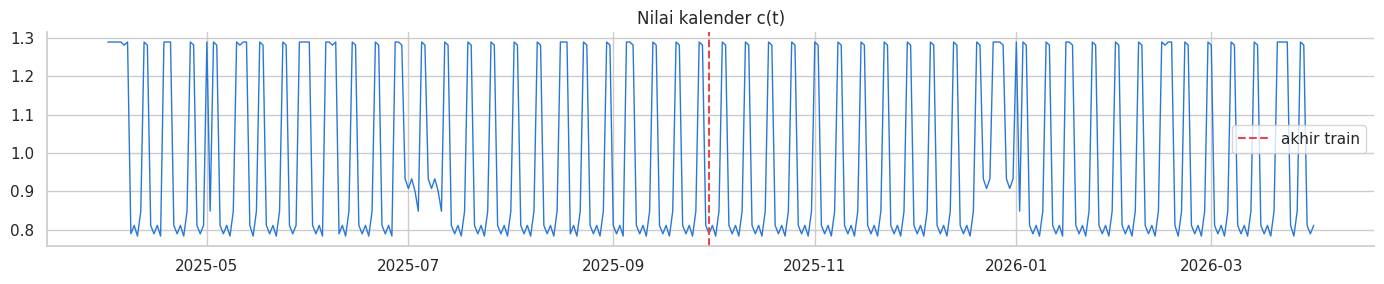

In [19]:
SCHOOL_BREAKS = [('2025-06-28', '2025-07-12'), ('2025-12-20', '2026-01-03')]
JABAR_BREAKS = [('2025-06-30', '2025-07-12'), ('2025-12-29', '2026-01-10')]
JABAR_CITIES = ['BOGOR', 'BEKASI', 'BANDUNG', 'DEPOK', 'CIKARANG', 'KARAWANG', 'CIREBON', 'GARUT', 'TASIKMALAYA',
                'SUMEDANG', 'CIANJUR', 'INDRAMAYU']
CUTI_BERSAMA = pd.to_datetime(['2025-04-02', '2025-04-03', '2025-04-04', '2025-04-07', '2025-05-13', '2025-05-30',
                               '2025-06-09', '2025-08-18', '2025-12-26', '2026-02-16', '2026-03-18', '2026-03-20',
                               '2026-03-23', '2026-03-24'])
RAMADAN = ('2026-02-19', '2026-03-20')


def calendar(hol, breaks=SCHOOL_BREAKS):
    c = hol.rename(columns={'date': 'date_show'})[['date_show', 'holiday_tipe']].copy()
    c['dow'] = c.date_show.dt.dayofweek
    c['is_hol'] = ((c.holiday_tipe == 'holiday') | c.date_show.isin(CUTI_BERSAMA)).astype(int)
    c['school'] = 0
    for a, b in breaks:
        c.loc[c.date_show.between(a, b), 'school'] = 1
    c['ramadan'] = c.date_show.between(*RAMADAN).astype(int)
    base = CFG.DOW_PROF[c.dow]
    base = np.where((c.school == 1) & (c.dow < 4), base * CFG.SCHOOL_WD, base)
    c['cal'] = np.where((c.is_hol == 1) & (c.ramadan == 0), np.maximum(base, CFG.HOL_LEVEL), base)
    return c.drop(columns='holiday_tipe').set_index('date_show')


CAL = calendar(hol)
CAL_JB = calendar(hol, JABAR_BREAKS)
fig, ax = plt.subplots(figsize=(14, 3))
ax.plot(CAL.index, CAL.cal, lw=1)
ax.axvline(CFG.TRAIN_END, color=PAL[7], ls='--', label='akhir train')
ax.set(title='Nilai kalender c(t)'); ax.legend()
plt.tight_layout(); plt.savefig(CFG.FIG_DIR / 'cal_value.png'); plt.show()

## Fungsi Build Fitur

Kelompok fitur: (1) bentuk kurva pasangan D1 sampai D3, (2) agregat film nasional dan pangsa format, (3) kalender target dan riwayat, (4) jadwal rilis film lain, termasuk film baru yang dibuka di klaster yang sama pada tanggal target (terlihat di jendela D1 sampai D3 film tersebut), (5) ukuran klaster dan harga kota, (6) metadata film, (7) level relatif pasar (median film yang rilis 28 hari sebelumnya, gabungan jendela D1 sampai D3 train dan uji). Fitur level relatif v13 ditambahkan setelah `build` di sel berikutnya.

In [20]:
GENRES = ['Horror', 'Drama', 'Action', 'Comedy', 'Romance', 'Animation', 'Family', 'Thriller', 'Mystery']
RATING = {'Semua Umur': 0, 'Remaja': 1, 'Dewasa': 2, 'Dewasa 21': 3}


def film_table(vis):
    g = vis.groupby('movie_title')
    return pd.DataFrame({'d1': g.date_show.min(), 'occ': g.occupation_rate.mean(),
                         'tps': g.total_ticket.sum() / g.total_show.sum().clip(lower=1),
                         'logT': np.log1p(g.total_ticket.sum() / 3),
                         'lpc': np.log1p(g.total_ticket.sum() / 3 / g.cinema_ids.nunique().clip(lower=1))})


def make_ctx(visible, size_tx, market):
    rel = visible.assign(base=base_title(visible.movie_title)).groupby('base').agg(
        d1=('date_show', 'min'), tix=('total_ticket', 'sum')).reset_index()
    rel['tix'] /= 3
    cs = size_tx.groupby('cinema_ids').total_ticket.sum() / size_tx.groupby('cinema_ids').date_show.nunique()
    nf = size_tx.groupby(['cinema_ids', 'date_show']).movie_title.nunique().groupby('cinema_ids').mean()
    csh = size_tx.groupby(['cinema_ids', 'date_show']).total_show.sum().groupby('cinema_ids').median()
    return dict(releases=rel, market=market, visible=visible, cin_size=np.log10(cs), cin_nfilms=nf, cin_shows=csh)


def cinema_comp(X, vis, cin_shows):
    v = vis.assign(base=base_title(vis.movie_title))
    agg = v.groupby(['cinema_ids', 'date_show', 'base']).agg(sh=('total_show', 'sum'), tx=('total_ticket', 'sum')).reset_index()
    m = X[['cinema_ids', 'date_show']].assign(base=base_title(X.movie_title)).reset_index().merge(
        agg, on=['cinema_ids', 'date_show'], how='left', suffixes=('', '_o'))
    m = m[m.base != m.base_o]
    g = m.groupby('index').agg(c_new_n=('base_o', 'nunique'), c_new_sh=('sh', 'sum'), c_new_tx=('tx', 'sum'))
    X = X.join(g).fillna({'c_new_n': 0, 'c_new_sh': 0, 'c_new_tx': 0})
    X['c_new_sh_rel'] = X.c_new_sh / X.cinema_ids.map(cin_shows).fillna(X.c_new_sh.median() + 1)
    X['c_new_sh_vs_own'] = X.c_new_sh / X.sh3.clip(lower=1)
    X['c_new_tx_vs_own'] = np.log1p(X.c_new_tx) - np.log1p(X.y3)
    return X


def open_count(X, rel):
    d = np.sort(rel.d1.values.astype('datetime64[D]'))
    a = np.searchsorted(d, X.d1.values.astype('datetime64[D]'), side='right')
    b = np.searchsorted(d, X.date_show.values.astype('datetime64[D]'), side='right')
    return b - a


def build(hh, tgt, ctx):
    mv = movies.set_index('original_title')
    d1 = hh.groupby('movie_title').date_show.min().rename('d1')
    hh = hh.join(d1, on='movie_title')
    hh['d'] = (hh.date_show - hh.d1).dt.days + 1
    piv = lambda v, p: hh.pivot_table(index=KEY, columns='d', values=v, fill_value=0).reindex(columns=[1, 2, 3], fill_value=0).add_prefix(p)
    P = pd.concat([piv('total_ticket', 'y'), piv('total_show', 'sh')], axis=1)
    P['mean3'] = P[['y1', 'y2', 'y3']].mean(axis=1)
    P['scale'] = P.mean3.clip(lower=1)
    P['log_s'] = np.log1p(P.mean3)
    for i in (1, 2, 3):
        P[f'p{i}'] = P[f'y{i}'] / P.scale
    P['n_hist'] = (P[['y1', 'y2', 'y3']] > 0).sum(axis=1)
    P['sh_trend'] = P.sh3 / P[['sh1', 'sh2']].max(axis=1).clip(lower=1)
    P = P.reset_index()

    Fd = hh.groupby(['movie_title', 'd']).agg(T=('total_ticket', 'sum'), nc=('cinema_ids', 'nunique')).unstack().fillna(0)
    Fd.columns = [f'f{a}{b}' for a, b in Fd.columns]
    Fd = Fd.reindex(columns=[f'f{a}{b}' for a in ['T', 'nc'] for b in (1, 2, 3)], fill_value=0)
    Fm = Fd[['fT1', 'fT2', 'fT3']].mean(axis=1).clip(lower=1)
    for i in (1, 2, 3):
        Fd[f'fp{i}'] = Fd[f'fT{i}'] / Fm
    ncmax = Fd[['fnc1', 'fnc2', 'fnc3']].max(axis=1).clip(lower=1)
    Fd['f_logT'] = np.log1p(Fm)
    Fd['f_nc_trend'] = Fd.fnc3 / Fd.fnc1.clip(lower=1)
    Fd['f_occ'] = hh.groupby('movie_title').occupation_rate.mean()
    h3 = hh[hh.d == 3].groupby('movie_title')
    Fd['f_tps3'] = h3.total_ticket.sum() / h3.total_show.sum()
    Fd = Fd.join(d1)
    Fd['base'] = base_title(pd.Series(Fd.index, index=Fd.index))
    Fd['fmt'] = fmt(pd.Series(Fd.index, index=Fd.index)).map({'2D': 0, '3D': 1, 'IMAX 2D': 2, 'IMAX 3D': 3})
    bT = hh.assign(base=base_title(hh.movie_title)).groupby('base').total_ticket.sum() / 3
    Fd['fmt_share'] = np.log1p(Fm) - np.log1p(Fd.base.map(bT))
    Fd['d1_dow'] = Fd.d1.dt.dayofweek
    m = mv.reindex(Fd.base)
    Fd['rating'] = m.age_rating.map(RATING).values
    for g_ in GENRES:
        Fd[f'g_{g_}'] = m.genre.fillna('').str.contains(g_).astype(int).values
    Fd['n_genre'] = m.genre.fillna('').str.count(',').values + 1
    Fd['n_cast'] = m.casts.fillna('').str.count(',').values + 1
    rel = ctx['releases']
    Fd['comp_n'] = [((rel.base != r.base) & (rel.d1 > r.d1) & (rel.d1 <= r.d1 + pd.Timedelta(days=9))).sum() for _, r in Fd.iterrows()]
    Fd['f_share_cohort'] = np.log1p(Fd.base.map(bT)) - np.log1p(Fd.d1.map(rel.groupby('d1').tix.sum()))
    mk = ctx['market']
    win = lambda t: mk[(mk.d1 < t) & (mk.d1 >= t - pd.Timedelta(days=28))]
    Fd[['mk_occ', 'mk_tps', 'mk_logT', 'mk_lpc']] = [win(t)[['occ', 'tps', 'logT', 'lpc']].median().tolist() for t in Fd.d1]
    Fd['occ_rel'] = Fd.f_occ / Fd.mk_occ
    Fd['tps_rel'] = Fd.f_tps3 / Fd.mk_tps
    Fd['logT_rel'] = Fd.f_logT - Fd.mk_logT
    Fd['film_pc_vs_mkt'] = np.log1p(Fm / ncmax) - Fd.mk_lpc

    X = tgt.merge(P, on=KEY, how='left').merge(Fd.drop(columns=['base']), left_on='movie_title', right_index=True, how='left')
    X['h'] = (X.date_show - X.d1).dt.days + 1
    jb = (X.city_name.isin(JABAR_CITIES) & CFG.REGIONAL_CAL).values
    cal_at = lambda dates, col: np.where(jb, CAL_JB[col].reindex(dates).values, CAL[col].reindex(dates).values)
    X['dow'] = X.date_show.dt.dayofweek.values
    X['t_hol'], X['t_school'], X['t_ramadan'] = cal_at(X.date_show, 'is_hol'), cal_at(X.date_show, 'school'), cal_at(X.date_show, 'ramadan')
    ch = np.stack([cal_at(X.d1 + pd.Timedelta(days=k), 'cal') for k in range(3)], 1)
    X['cal_mult'] = cal_at(X.date_show, 'cal') / ch.mean(1)
    X['hol_in_hist'] = np.stack([cal_at(X.d1 + pd.Timedelta(days=k), 'is_hol') for k in range(3)], 1).sum(1)
    # D1-D3 tickets divided by the calendar value of their own day; labels and the MASE scale are untouched
    q = np.stack([X[f'y{i}'].values / cal_at(X.d1 + pd.Timedelta(days=i - 1), 'cal') for i in (1, 2, 3)], 1)
    for i in (1, 2, 3):
        X[f'cal_p{i}'] = q[:, i - 1] / np.maximum(q.mean(1), 1)
    X['cal_log31'] = np.log1p(q[:, 2]) - np.log1p(q[:, 0])
    X['n_comp_open'] = open_count(X, rel)
    X = cinema_comp(X, ctx['visible'], ctx['cin_shows'])
    X['share'] = X.log_s - np.log1p(X[['fT1', 'fT2', 'fT3']].mean(axis=1) / X.fnc3.clip(lower=1))
    X['pair_vs_mkt'] = X.log_s - X.mk_lpc
    X['p3_rel'] = X.p3 - X.fp3
    X['p1_rel'] = X.p1 - X.fp1
    X['cin_size'] = X.cinema_ids.map(ctx['cin_size'])
    X['cin_nfilms'] = X.cinema_ids.map(ctx['cin_nfilms'])
    X['cin_new'] = X.cin_size.isna().astype(int)
    pr = price.pivot(index='city_name', columns='price_day', values='ceil')
    X['price_wkd'] = X.city_name.map(pr.Weekday)
    X['price_prem'] = X.city_name.map(pr.Weekend / pr.Weekday)
    return X

Fitur dibangun untuk film rilis luas, film rilis terbatas (hanya latih), dan data uji. Tiga pemeriksaan wajib: jumlah baris tetap, urutan `id` uji tetap, dan skala sama persis dengan fungsi `hitung_skala` resmi.

In [21]:
market = pd.concat([film_table(vis_tr), film_table(hist)])
ctx_tr = make_ctx(vis_tr, train, market)
Xtr = build(hs, ts, ctx_tr)
Xlim = build(hl, tl, ctx_tr)
Xte = build(hist, test, make_ctx(hist, train, market))

assert len(Xtr) == len(ts) and len(Xte) == len(test) and (Xte.id.values == test.id.values).all()
ref = Xte.join(pair_scale(hist), on=KEY, rsuffix='_ref')
assert np.allclose(ref.scale, ref.scale_ref)

BASE_FEATS = ['log_s', 'p1', 'p2', 'p3', 'n_hist', 'sh_trend', 'fnc1', 'fnc2', 'fnc3', 'fp1', 'fp2', 'fp3', 'f_logT',
              'f_nc_trend', 'fmt', 'fmt_share', 'd1_dow', 'rating'] + [f'g_{g_}' for g_ in GENRES] + [
              'n_genre', 'n_cast', 'comp_n', 'f_share_cohort', 'h', 'dow', 't_hol', 't_school', 't_ramadan', 'cal_mult',
              'hol_in_hist', 'n_comp_open', 'share', 'p3_rel', 'p1_rel', 'cin_size', 'cin_nfilms', 'cin_new',
              'price_wkd', 'price_prem']
COMP_FEATS = ['c_new_n', 'c_new_sh', 'c_new_sh_rel', 'c_new_sh_vs_own', 'c_new_tx_vs_own']
CAL_FEATS = ['cal_p1', 'cal_p2', 'cal_p3', 'cal_log31']
FEATS = BASE_FEATS
ZFEATS = FEATS + COMP_FEATS
jb_changed = Xte.t_school.values != CAL.school.reindex(Xte.date_show).values
print(f'West Java calendar: {jb_changed.sum()} test rows change school flag ({jb_changed.mean():.2%}); train rows changed: '
      f'{int((Xtr.t_school.values != CAL.school.reindex(Xtr.date_show).values).sum())}')
for X_ in (Xtr, Xlim, Xte):
    assert np.isfinite(X_[CAL_FEATS].values).all()
print('calendar-normalised inputs (median train | test):', {c: (round(float(Xtr[c].median()), 3), round(float(Xte[c].median()), 3)) for c in CAL_FEATS})
print(f'train {len(Xtr)} rows | limited extra {len(Xlim)} | test {len(Xte)} | features {len(FEATS)}')
display(pd.DataFrame({'train_median': Xtr[['log_s', 'f_logT', 'pair_vs_mkt', 'film_pc_vs_mkt', 'share']].median(),
                      'test_median': Xte[['log_s', 'f_logT', 'pair_vs_mkt', 'film_pc_vs_mkt', 'share']].median()}).round(3))

West Java calendar: 1060 test rows change school flag (1.46%); train rows changed: 202
calendar-normalised inputs (median train | test): {'cal_p1': (1.219, 1.213), 'cal_p2': (0.96, 0.944), 'cal_p3': (0.801, 0.814), 'cal_log31': (-0.417, -0.392)}
train 54314 rows | limited extra 1433 | test 72611 | features 47


,train_median,test_median
log_s,5.191,4.529
f_logT,9.928,9.450
pair_vs_mkt,0.018,-0.123
film_pc_vs_mkt,0.318,0.286
share,-0.378,-0.435


## Fitur Level Relatif

Tiga fitur menggantikan dua fitur level absolut. `rel_nat` = log skala pasangan dikurangi log median skala pasangan film lain yang D1-nya berjarak paling jauh 14 hari; `rel_clu` = sama, tetapi hanya pasangan di klaster yang sama (minimal dua pembanding, selain itu memakai `rel_nat`); `f_rel` = log rata-rata tiket harian film dikurangi log median film lain pada jendela yang sama. Film pembanding tidak pernah judul dasar yang sama, sehingga versi IMAX atau 3D tidak menjadi pembandingnya sendiri. Referensi hanya memakai D1 sampai D3 film lain, bukan label D4 sampai D10, sehingga tidak ada kebocoran target, dan aturan informasi yang sama berlaku untuk train dan uji. Implementasinya diverifikasi dengan perhitungan brute-force pada sampel baris.

brute-force check of the cluster reference passed (80 rows); fallback to national reference: {'train': 0.0006, 'limited': 0.0, 'test': 0.001}


,train_median,test_median,shift,ks
feature,,,,
log_s,5.191,4.529,-0.662,0.228
f_logT,9.928,9.450,-0.478,0.229
rel_nat,0.290,0.229,-0.061,0.038
rel_clu,0.269,0.199,-0.070,0.037
f_rel,0.656,0.501,-0.154,0.101


cluster reference median (tickets/day): train 142 | test 77


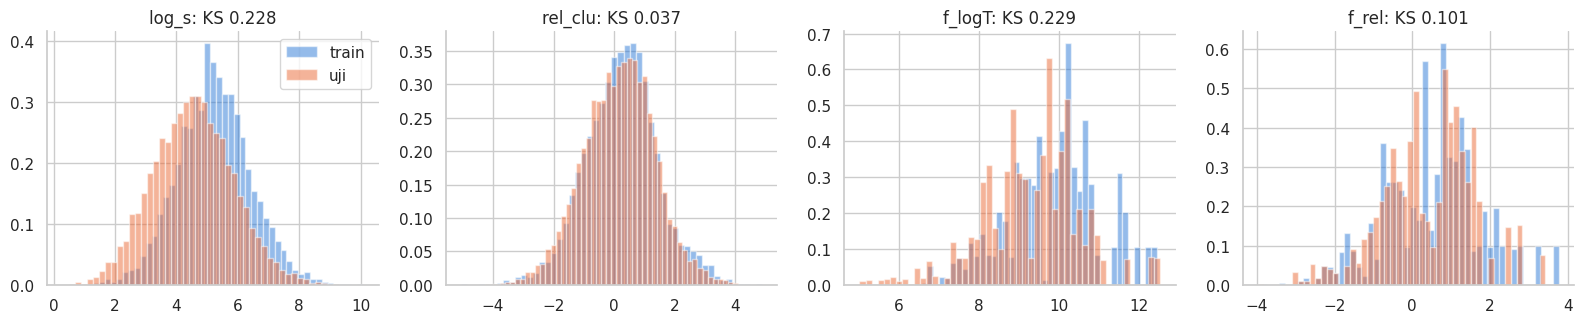

In [22]:
REL_FEATS = ['rel_nat', 'rel_clu', 'f_rel']
ABS_LEVEL = ['log_s', 'f_logT']


def add_relative(X):
    X = X.copy()
    X['ref_clu'], X['ref_nat'] = ref_cluster(X, 'sc'), ref_national(X, VP, 'sc')
    ls = np.log(X.scale.values)
    X['rel_nat'] = ls - np.log(np.clip(X.ref_nat.values, 1, None))
    X['rel_clu'] = np.where(np.isfinite(X.ref_clu), ls - np.log(np.clip(X.ref_clu.values, 1, None)), X.rel_nat)
    fm = X[['fT1', 'fT2', 'fT3']].mean(axis=1).clip(lower=1).values
    X['f_rel'] = np.log(fm) - np.log(np.clip(ref_national(X, VF, 'ft'), 1, None))
    return X


XP = build(hp, tp, ctx_tr)
assert len(XP) == len(tp)
Xtr, Xlim, Xte, XP = add_relative(Xtr), add_relative(Xlim), add_relative(Xte), add_relative(XP)
assert len(Xte) == len(test) and (Xte.id.values == test.id.values).all()
assert all(np.isfinite(X_[REL_FEATS].values).all() for X_ in (Xtr, Xlim, Xte, XP))
FEATS_ABS = BASE_FEATS
FEATS_REL = [f for f in BASE_FEATS if f not in ABS_LEVEL] + REL_FEATS

rng_ = np.random.default_rng(CFG.SEED)
for X_ in (Xtr, Xte):
    for i in rng_.choice(len(X_), 40, replace=False):
        r_ = X_.iloc[i]
        k = (VP.cinema_ids == r_.cinema_ids) & ((VP.d1 - r_.d1).dt.days.abs() <= CFG.REL_WIN) & (VP.base != base_title(pd.Series([r_.movie_title]))[0])
        ref_bf = VP.sc[k].median() if k.sum() >= 2 else np.nan
        assert np.isclose(ref_bf, r_.ref_clu, equal_nan=True), (r_.movie_title, r_.cinema_ids)
print('brute-force check of the cluster reference passed (80 rows); fallback to national reference:',
      {n: round(float(np.isnan(X_.ref_clu).mean()), 4) for n, X_ in [('train', Xtr), ('limited', Xlim), ('test', Xte)]})

kt = pd.DataFrame([dict(feature=c, train_median=Xtr[c].median(), test_median=Xte[c].median(),
                        shift=Xte[c].median() - Xtr[c].median(), ks=ks_2samp(Xtr[c], Xte[c]).statistic)
                   for c in ABS_LEVEL + REL_FEATS]).set_index('feature')
display(kt.round(3))
print(f'cluster reference median (tickets/day): train {np.nanmedian(Xtr.ref_clu):.0f} | test {np.nanmedian(Xte.ref_clu):.0f}')
fig, ax = plt.subplots(1, 4, figsize=(16, 3.4))
for a_, c in zip(ax, ['log_s', 'rel_clu', 'f_logT', 'f_rel']):
    a_.hist(Xtr[c], bins=50, density=True, alpha=.5, label='train'); a_.hist(Xte[c], bins=50, density=True, alpha=.5, label='uji')
    a_.set(title=f"{c}: KS {kt.loc[c, 'ks']:.3f}")
ax[0].legend()
plt.tight_layout(); plt.savefig(CFG.FIG_DIR / 'relative_features.png'); plt.show()

#### Insights

> Pasar uji sekitar separuh pasar train (median referensi klaster lokal 75 vs 146 tiket per hari). `log_s` dan `f_logT` bergeser sekitar -0,5 sampai -0,7 dengan jarak KS sekitar 0,23, sedangkan `rel_nat` dan `rel_clu` hampir identik di kedua periode (KS sekitar 0,04) dan `f_rel` turun ke sekitar 0,1. Level relatif mempertahankan informasi "pasangan ini lemah atau kuat" tanpa ikut membawa level pasar yang berubah.

> Di dalam train kedua jenis level saling berkorelasi, sehingga grouped CV hampir tidak bisa membedakannya. Tabel lookup lokal (`eda/69`) memperlihatkan bedanya baru muncul di luar distribusi train: dengan level absolut, porsi nol yang tersirat untuk baris uji 0,42 dan median $r$ 0,30, sedangkan dengan level relatif 0,30 dan 0,38.

## Verifikasi Drift: Adversarial Validation

Classifier dilatih membedakan baris simulasi dari baris uji dengan fold dikelompokkan per film (split acak memberi AUC palsu 1,0 karena fitur level film konstan dalam satu film).

In [23]:
def adv_auc(cols):
    A = pd.concat([Xtr[cols].assign(t=0, g=Xtr.movie_title), Xte[cols].assign(t=1, g=Xte.movie_title)], ignore_index=True)
    oof = np.zeros(len(A))
    for a, b in StratifiedGroupKFold(5, shuffle=True, random_state=CFG.SEED).split(A, A.t, A.g):
        m = lgb.LGBMClassifier(n_estimators=200, learning_rate=0.05, random_state=CFG.SEED, verbose=-1)
        oof[b] = m.fit(A.iloc[a][cols], A.t.iloc[a]).predict_proba(A.iloc[b][cols])[:, 1]
    return roc_auc_score(A.t, oof)


shape_cols = ['p1', 'p2', 'p3', 'fp1', 'fp3', 'share', 'sh_trend', 'd1_dow', 'n_hist']
print(f"AUC shape features only:         {adv_auc(shape_cols):.3f}")
print(f"AUC + absolute level (log_s, f_logT): {adv_auc(shape_cols + ['log_s', 'f_logT']):.3f}")
print(f"AUC + market-relative level:     {adv_auc(shape_cols + ['pair_vs_mkt', 'film_pc_vs_mkt']):.3f}")
print(f"AUC + v13 relative level:        {adv_auc(shape_cols + REL_FEATS):.3f}")
print(f"AUC full feature set, absolute:  {adv_auc(FEATS_ABS):.3f}")
print(f"AUC full feature set, relative:  {adv_auc(FEATS_REL):.3f}")

AUC shape features only:         0.552
AUC + absolute level (log_s, f_logT): 0.599
AUC + market-relative level:     0.498
AUC + v13 relative level:        0.526
AUC full feature set, absolute:  0.755
AUC full feature set, relative:  0.677


#### Insights

> Fitur bentuk kurva tidak bisa membedakan train dan uji (AUC sekitar 0,51). Level absolut menaikkan AUC karena pasar uji lebih sepi, sedangkan level relatif tidak. Pada set fitur lengkap, sisa AUC berasal dari fitur lain yang memang berbeda antarperiode (kalender, jadwal rilis, cakupan klaster), bukan dari level pasangan. Penurunan AUC set lengkap dari absolut ke relatif menunjukkan seberapa besar pergeseran yang dihapus oleh penggantian dua fitur level.

---

# Modeling <a name="8"></a>

---

Bagian ini membekukan fitur v13 dan validasi v15 lalu menguji dua perubahan terhadap kontrol pada fold yang sama: (1) label partial-window di data latih (C1 vs C0), dan (2) blend dengan dua foundation model terkompresi. Lensa: **CV kohort minggu rilis** dengan bobot komposisi uji (TW) dan **backtest temporal** Juli, Agustus, September. Setiap model kuantil memilih sendiri koreksi pencopotan ($\lambda$ 0 atau 0,5). Bobot blend dipilih dengan minimax regret atas dua lensa dengan batas ukuran 200 MB.

## Ringkasan Analisis untuk v18 dan v19

| Analisis | Angka | Konsekuensi di v18 |
| :--- | :--- | :--- |
| v15 di Kaggle | Blend LightGBM 0,1 + TabPFN-3.5 int7 0,9; TW kohort 0,3315, temporal 0,2971; public 0,39918 | Resep v15 menjadi kontrol C0 |
| v16, v17 | Kandidat v16 TW -0,000004 tetapi temporal +0,0007; genre +0,0006, konteks gabungan +0,0069 | Tidak dipakai |
| `eda/105` sampai `eda/108` (audit v1 sampai v17) | Film bergalat besar sama di semua versi; 1.403 label partial-window terbuang | **Label partial-window (C1)** |
| `eda/109` Blend OOF v15 | TabPFN-3.5 0,7 + Causilo log1p 0,3: TW -0,0014 [-0,0037; +0,0010] per minggu rilis | Causilo diuji sebagai pasangan |
| `eda/110` Paid preview | 109 dari 126 film punya transaksi sebelum D1; jendela pre-D1 hanya teramati untuk 7,7% baris uji | Tidak dipakai |
| `eda/111` Kompresi Causilo | int7 per baris + zlib: 29,2 MB, galat bobot 1,7%; bersama TabPFN-3.5 int7: 198,4 MB | **Causilo int7** |

Panitia menyatakan kompresi bobot boleh asalkan berkas yang diterima maksimal 200 MB. Galat bobot bukan galat prediksi; dampak kompresi kedua model diukur di bawah (float32 vs int7 pada fold yang sama).

Analisis lokal untuk v19 (tanpa melatih model, hanya data dan OOF v18 yang tersimpan):

| Analisis | Angka | Konsekuensi di v19 |
| :--- | :--- | :--- |
| `eda/120` Level hari libur | Per pasangan film lama: libur hari kerja 2,33x minggu tetangga vs kalender 1,59x; per film nasional D2/D3: 0,97 sampai 0,99 kali kalender | Lihat `eda/125` |
| `eda/125` Koreksi target hari libur | Pengali leave-one-holiday-out: optimum 0,95 (bukan uplift), TW baris libur 0,5601 menjadi 0,5675, 3 dari 10 tanggal membaik | **Tidak dipakai**: galat tinggi di hari libur adalah varians, bukan bias median |
| `eda/123` Profil hari masa sekolah | Sabtu/Senin-Kamis: minggu sekolah 1,77, minggu libur 1,40, profil saat ini 1,62; D1-D3 uji: lonjakan Jumat ke Sabtu +0,13 log vs train; OOF v18 P(y > prediksi) per hari 0,47 sampai 0,51 | **Tidak dipakai**: selisih level sekitar 10% hanya berdampak orde dua pada MASE |
| `eda/126` Blok anomali Juni | 2.058 baris target di 1 sampai 16 Juni, median $y/s$ 0,05 sampai 0,29 vs 0,44 sampai 0,98 | **Blok 1-16 Juni dibuang** |
| `eda/121` Kejenuhan kapasitas Lebaran | Okupansi slate Lebaran 2025 median 73% vs 37% minggu normal, pertunjukan tetap; kapasitas kursi slate 2026 970 ribu vs 2025 918 ribu per hari; total nasional model kapasitas 570 ribu vs analog $\rho = 0{,}92$ 543 ribu tiket per hari | **$\rho$ diukur dari train**, level nasional dikonfirmasi dua jalur |
| `eda/122` Alokasi saat lonjakan | Dengan rasio klaster benar: MASE Lebaran 2025 0,628, rasio nasional saja 1,238; okupansi di dalam klaster -0,010 (CI melewati nol); antar film slope 0,0 | Pembagian antar film di dalam klaster **tidak** diubah |
| `eda/124` Rasio klaster lintas kejadian | Tujuh lonjakan libur berlabel: korelasi split-half 0,65; skill prediksi pola masa lalu 0,20, okupansi 0,39, rata-ratanya 0,44 | **Rasio klaster Lebaran = rata-rata geometrik analog dan kapasitas** |
| `eda/127` Cek prepro Lebaran v2 | Total nasional per hari identik; faktor per baris 0,77 sampai 1,24; terbesar Padang (ID yang menyerap pembukaan Basko XXI Juli 2025) 1,99 | Diterapkan di Bagian 10 |

## Lensa Validasi: Fold Kohort Minggu Rilis

Setiap judul dasar dipetakan ke minggu rilisnya (minggu sejak 31 Maret 2025 dari D1), lalu minggu-minggu itu dibagi acak ke 5 fold dengan seed tetap. Semua film satu minggu, termasuk versi IMAX dan 3D, berada di fold yang sama, sehingga model tidak pernah melihat pesaing, kalender, atau kondisi pasar minggu validasinya. Bobot `TW` menyamakan porsi setiap sel (bucket skala x hari pertama laku) dengan data uji.

In [24]:
groups = base_title(Xtr.movie_title).values
WEEK = ((Xtr.d1 - pd.Timestamp('2025-03-31')).dt.days // 7).values
weeks_ = np.array(sorted(set(WEEK)))
fold_of_week = dict(zip(weeks_, np.random.RandomState(CFG.SEED).permutation(len(weeks_)) % CFG.N_FOLDS))
FOLD = np.array([fold_of_week[w_] for w_ in WEEK])
assert pd.Series(FOLD).groupby(groups).nunique().max() == 1
WEEK_P = ((XP.d1 - pd.Timestamp('2025-03-31')).dt.days // 7).values
FOLD_P = np.array([fold_of_week.get(w_, -1) for w_ in WEEK_P])
print('partial-window rows by fold (-1 = week never validated):', pd.Series(FOLD_P).value_counts().sort_index().to_dict())
y, s, cm, hh_ = Xtr.total_ticket.values, Xtr.scale.values, Xtr.cal_mult.values, Xtr.h.values

fday = lambda D: pd.Series(np.where(D.y1 > 0, 1, np.where(D.y2 > 0, 2, 3)), index=D.index)
cell = lambda D: pd.cut(D.scale, CFG.TW_BINS).astype(str) + '|' + fday(D).astype(str)
tw = cell(Xtr).map(cell(Xte).value_counts(normalize=True) / cell(Xtr).value_counts(normalize=True)).fillna(0).astype(float).values
TW = tw / tw.mean()
fold_tab = pd.DataFrame({'films': pd.Series(groups).groupby(FOLD).nunique(), 'weeks': pd.Series(WEEK).groupby(FOLD).nunique(),
                         'rows': pd.Series(FOLD).value_counts().sort_index(), 'TW share': pd.Series(TW).groupby(FOLD).sum() / TW.sum()})
display(fold_tab.round(3))


def score(p, name):
    e = np.abs(y - p) / s
    r = dict(model=name, MASE=e.mean(), TW_MASE=np.average(e, weights=TW), small=e[s <= 20].mean(), big=e[s > 200].mean())
    print(f"{name:40s} MASE {r['MASE']:.4f} | TW-MASE {r['TW_MASE']:.4f} | s<=20 {r['small']:.4f} | s>200 {r['big']:.4f}")
    return r


def train_part(k, cfg):
    parts = [Xtr[FOLD != k]] + ([Xlim] if CFG.USE_LIMITED else []) + ([XP[FOLD_P != k]] if cfg['partial'] else [])
    return pd.concat(parts, ignore_index=True)


results = []
rc = y / s / cm
oof_base = np.zeros(len(Xtr))
for k in range(CFG.N_FOLDS):
    a, b = FOLD != k, FOLD == k
    med = pd.Series(rc[a]).groupby([hh_[a], Xtr.d1_dow.values[a]]).median()
    oof_base[b] = med.reindex(pd.MultiIndex.from_arrays([hh_[b], Xtr.d1_dow.values[b]])).fillna(np.median(rc[a])).values * cm[b] * s[b]
results.append(score(oof_base, 'median r/c by (h, D1 dow)'))

partial-window rows by fold (-1 = week never validated): {-1: 1403}


,films,weeks,rows,TW share
0,29,5,11047,0.186
1,31,5,14308,0.272
2,26,4,11081,0.214
3,17,4,8071,0.130
4,21,4,9807,0.198


median r/c by (h, D1 dow)                MASE 0.4009 | TW-MASE 0.4339 | s<=20 0.9939 | s>200 0.3255


## Offset Pencopotan dari Proxy Periode Uji

Klasifier proxy (D3 dari D1 dan D2) dilatih pada train dan dinilai pada pasangan periode uji, sama seperti v4 sampai v13. Offset logit $a$ dipakai oleh koreksi $\lambda a$ yang diuji per model.

In [25]:
for Pp in (PA, PB):
    c3 = np.stack([CAL.cal.reindex(Pp.d1 + pd.Timedelta(days=k)).values for k in range(3)], 1)
    Pp['cm'] = c3[:, 2] / c3[:, :2].mean(1)
PCOLS = ['q1', 'q2', 'log_s', 'sh1', 'sh2', 'sh_tr', 'occ2', 'f_tr', 'f_log', 'f_nc', 'cm', 'd1_dow']
clf = lgb.LGBMClassifier(n_estimators=300, learning_rate=0.05, num_leaves=31, min_child_samples=100, verbose=-1,
                         deterministic=True, force_row_wise=True, random_state=CFG.SEED).fit(PA[PCOLS], PA.y == 0)
pB0 = np.clip(clf.predict_proba(PB[PCOLS])[:, 1], 1e-4, 1 - 1e-4)
zB = (PB.y == 0).values
PULL_A = float(grid_a[np.argmin([nll(pB0, zB, a) for a in grid_a])])
print(f'pull-odds shift a = {PULL_A:.3f} (odds x {np.exp(PULL_A):.2f}); mean p0 {pB0.mean():.3f} -> shifted {sigm(logit(pB0) + PULL_A).mean():.3f} | observed {zB.mean():.3f}')

pull-odds shift a = -1.420 (odds x 0.24); mean p0 0.154 -> shifted 0.085 | observed 0.085


## Statistik Klaster Fold-Local

Statistik klaster (ukuran, jumlah film per hari, jumlah show) dihitung ulang per fold tanpa seluruh transaksi film fold validasi, dan per cutoff temporal hanya dari transaksi sebelum cutoff. Data uji memakai seluruh train.

In [26]:
def cin_stats(tx):
    cs = tx.groupby('cinema_ids').total_ticket.sum() / tx.groupby('cinema_ids').date_show.nunique()
    nf = tx.groupby(['cinema_ids', 'date_show']).movie_title.nunique().groupby('cinema_ids').mean()
    csh = tx.groupby(['cinema_ids', 'date_show']).total_show.sum().groupby('cinema_ids').median()
    return np.log10(cs), nf, csh


def with_cin(X, stats):
    cs, nf, csh = stats
    X = X.copy()
    X['cin_size'] = X.cinema_ids.map(cs)
    X['cin_nfilms'] = X.cinema_ids.map(nf)
    X['cin_new'] = X.cin_size.isna().astype(int)
    X['c_new_sh_rel'] = X.c_new_sh / X.cinema_ids.map(csh).fillna(X.c_new_sh.median() + 1)
    return X


TRAIN_BASE = base_title(train.movie_title)
STATS_ALL = cin_stats(train)
assert np.allclose(with_cin(Xtr, STATS_ALL).cin_size.fillna(-9), Xtr.cin_size.fillna(-9))
STATS_FOLD = {k: cin_stats(train[~TRAIN_BASE.isin(set(groups[FOLD == k]))]) for k in range(CFG.N_FOLDS)}
rk = np.mean([pd.Series(with_cin(Xtr[FOLD == k], STATS_FOLD[k]).cin_size.values).corr(pd.Series(Xtr.cin_size[FOLD == k].values), method='spearman') for k in range(CFG.N_FOLDS)])
print(f'rank correlation of cin_size, global vs fold-local: {rk:.4f}')

rank correlation of cin_size, global vs fold-local: 0.9991


## Mesin Evaluasi, C0 dan C1

LightGBM sama dengan v15: L1 (3 seed) ditambah hurdle, bobot hurdle 0,75, $\lambda = 0{,}5$. `run_cv` menjalankan CV kohort dan `temporal` backtest bulanan untuk satu konfigurasi; bagian latih disimpan agar semua foundation model memakai bagian latih yang persis sama. **C0** = resep v15. **C1** = C0 + label partial-window: di CV, label film yang minggunya sedang divalidasi tidak ikut; di backtest temporal, untuk setiap cutoff dibentuk ulang label partial-window yang sudah teramati sebelum cutoff (film yang D1 sampai D3-nya selesai sebelum cutoff tetapi D10-nya belum).

In [27]:
LGB_BASE = {k: v for k, v in CFG.LGB_PARAMS.items() if k not in ('objective', 'n_estimators')}
LGB_FAST = {**LGB_BASE, 'n_estimators': 300, 'learning_rate': 0.05}
MONTHS = ['2025-07', '2025-08', '2025-09']
FEATS = FEATS_ABS
ZFEATS = FEATS + COMP_FEATS


def r_target(Xa):
    return (Xa.total_ticket / Xa.scale / Xa.cal_mult).values


def fit_lgb_all(Xa):
    l1 = [lgb.LGBMRegressor(objective='l1', n_estimators=CFG.LGB_PARAMS['n_estimators'], **LGB_BASE, random_state=sd)
          .fit(Xa[FEATS], r_target(Xa), sample_weight=Xa.cal_mult.values) for sd in CFG.SEEDS]
    zc = lgb.LGBMClassifier(objective='binary', **{**LGB_FAST, 'num_leaves': 31}, random_state=CFG.SEED).fit(Xa[ZFEATS], Xa.total_ticket == 0)
    pos = Xa[Xa.total_ticket > 0]
    qm = [lgb.LGBMRegressor(objective='quantile', alpha=float(q), **LGB_FAST, random_state=CFG.SEED).fit(pos[FEATS], r_target(pos))
          for q in CFG.QS]
    return dict(l1=l1, zc=zc, qm=qm)


def lgb_size_mb(m):
    return sum(len(zlib.compress(x.booster_.model_to_string().encode(), 9)) for x in m['l1'] + [m['zc']] + m['qm']) / 1e6


def predict_lgb_all(m, Xb):
    l1 = np.clip(np.mean([mm.predict(Xb[FEATS]) for mm in m['l1']], 0), 0, None)
    p0 = m['zc'].predict_proba(Xb[ZFEATS])[:, 1]
    Q = np.sort(np.column_stack([mm.predict(Xb[FEATS]) for mm in m['qm']]), axis=1)
    return l1, p0, Q


def mixture_median(p0, Q, qs, lam):
    p = sigm(logit(np.clip(p0, 1e-4, 1 - 1e-4)) + lam * PULL_A)
    t = np.clip((0.5 - p) / (1 - p), qs[0], qs[-1])
    val = np.array([np.interp(ti, qs, qi) for ti, qi in zip(t, Q)])
    return np.where(p >= 0.5, 0.0, np.clip(val, 0, None))


def lgb_mix(l1, p0, Q, lam=None):
    lam = CFG.LAMBDA if lam is None else lam
    return (1 - CFG.HURDLE_W) * l1 + CFG.HURDLE_W * mixture_median(p0, Q, CFG.QS, lam)


def run_cv(cfg):
    oof = dict(l1=np.zeros(len(Xtr)), p0=np.zeros(len(Xtr)), Q=np.zeros((len(Xtr), len(CFG.QS))))
    frames, size = {}, 0.0
    for k in range(CFG.N_FOLDS):
        v = FOLD == k
        Xa, Xb = with_cin(train_part(k, cfg), STATS_FOLD[k]), with_cin(Xtr[v], STATS_FOLD[k])
        m = fit_lgb_all(Xa)
        oof['l1'][v], oof['p0'][v], oof['Q'][v] = predict_lgb_all(m, Xb)
        frames[k] = (Xa, Xb)
        size = max(size, lgb_size_mb(m))
    return oof, frames, size


def temporal(cfg):
    out = {}
    for mth in MONTHS:
        cut = pd.Timestamp(mth + '-01')
        va = (Xtr.d1.dt.strftime('%Y-%m') == mth).values
        ready = lambda X: X[(X.d1 + pd.Timedelta(days=9) < cut).values]
        Xa = pd.concat([ready(Xtr)] + ([ready(Xlim)] if CFG.USE_LIMITED else []) + ([PART_T[mth]] if cfg['partial'] else []), ignore_index=True)
        stats = cin_stats(train[train.date_show < cut])
        Xa_, Xb_ = with_cin(Xa, stats), with_cin(Xtr[va], stats)
        out[mth] = dict(idx=np.where(va)[0], parts=predict_lgb_all(fit_lgb_all(Xa_), Xb_), frames=(Xa_, Xb_))
    return out


def lgb_component(R, lam=None):
    o = R['oof']
    tp = {m: (t['idx'], lgb_mix(*t['parts'], lam=lam) * cm[t['idx']] * s[t['idx']]) for m, t in R['temporal'].items()}
    return lgb_mix(o['l1'], o['p0'], o['Q'], lam=lam) * cm * s, tp


def lens(p, tpred):
    e = np.abs(y - p) / s
    r = dict(TW=np.average(e, weights=TW), MASE=e.mean())
    r.update({f'fold{k}': np.average(e[FOLD == k], weights=TW[FOLD == k]) for k in range(CFG.N_FOLDS)})
    tm = {m: np.average(np.abs(y[i] - pr) / s[i], weights=TW[i]) for m, (i, pr) in tpred.items()}
    r.update({f'temp_{m}': v for m, v in tm.items()})
    r['temporal_mean'] = np.mean(list(tm.values()))
    return r


def blend(ws, comps):
    p = sum(w_ * comps[n][0] for n, w_ in ws.items())
    tp = {m: (i, sum(w_ * comps[n][1][m][1] for n, w_ in ws.items())) for m, (i, _) in comps['lgb'][1].items()}
    return p, tp


def partial_frame(cut):
    hp_, tp_ = observed_partial(train, ANCHORS, cut - pd.Timedelta(days=1))
    return add_relative(build(hp_, tp_, ctx_tr)) if len(tp_) else Xtr.iloc[:0].copy()


PART_T = {m: partial_frame(pd.Timestamp(m + '-01')) for m in MONTHS}
for m, P_ in PART_T.items():
    assert P_.empty or (P_.date_show < pd.Timestamp(m + '-01')).all()
print('partial-window training rows per temporal cutoff:', {m: len(P_) for m, P_ in PART_T.items()})
CONFIGS = {'C0': dict(partial=False), 'C1': dict(partial=True)}
RUNS = {}
for cname, cfgx in CONFIGS.items():
    t0 = time.time()
    oof_, frames_, size_ = run_cv(cfgx)
    RUNS[cname] = dict(cfg=cfgx, oof=oof_, frames=frames_, temporal=temporal(cfgx), lgb_mb=size_)
    RUNS[cname]['comp'] = lgb_component(RUNS[cname])
    print(f'{cname} LightGBM: {time.time() - t0:.0f}s | size {size_:.1f} MB')
display(pd.DataFrame({f'LightGBM {n}': lens(*R['comp']) for n, R in RUNS.items()}).T.round(4))

partial-window training rows per temporal cutoff: {'2025-07': 874, '2025-08': 2169, '2025-09': 284}
C0 LightGBM: 561s | size 20.1 MB
C1 LightGBM: 550s | size 20.1 MB


,TW,MASE,fold0,fold1,fold2,fold3,fold4,temp_2025-07,temp_2025-08,temp_2025-09,temporal_mean
LightGBM C0,0.3406,0.3223,0.3791,0.2665,0.3322,0.4637,0.3349,0.3216,0.2873,0.2909,0.2999
LightGBM C1,0.3407,0.3216,0.3775,0.2669,0.3308,0.4597,0.3405,0.3193,0.2868,0.2897,0.2986


Sensitivitas $\lambda$ LightGBM (dibekukan 0,5) pada kedua lensa, hanya untuk informasi.

In [28]:
display(pd.DataFrame({lam: lens(*lgb_component(RUNS['C0'], lam)) for lam in (0.0, 0.25, 0.5, 0.75, 1.0)}).T[['TW', 'temporal_mean']].round(4))

,TW,temporal_mean
0.00,0.3362,0.2993
0.25,0.3377,0.2992
0.50,0.3406,0.2999
0.75,0.3447,0.3016
1.00,0.3500,0.3053


## Foundation Model Terkompresi

Kedua model dipakai in-context dengan bagian latih per fold dan per cutoff yang sama dengan LightGBM, untuk C0 dan C1, dan mengeluarkan 49 kuantil $r$. Keduanya dikompresi dengan cara yang sama: setiap matriks float32 dikuantisasi simetris per baris (kode int7 -63 sampai 63, skala float16 per baris), kode disimpan dengan zlib level 9, vektor tetap float32. Paket inilah yang disimpan di berkas bobot dan didekompresi kembali ke float32 setiap kali dipakai, dari validasi sampai inferensi.

- **TabPFN-3.5 penuh int7** ([Prior-Labs/tabpfn_3_5](https://huggingface.co/Prior-Labs/tabpfn_3_5), `tabpfn-v3.5-20260909.safetensors`, revisi `06bf2ba3`, SHA-256 `ece4d67e...`, 876 MB float32 menjadi sekitar 169 MB), 16 anggota per horizon seperti v8 dan v15.
- **Causilo log1p int7** ([nums-ai/causilo](https://huggingface.co/nums-ai/causilo), `causilo==1.0.3`, revisi `94f2bd91`, regresor 148,4 MB float32 menjadi sekitar 29 MB), per horizon, dilatih pada $\log(1 + r)$ dan kuantilnya dikembalikan dengan $\exp(Q) - 1$ (eksak karena transformasi monoton).

Kedua model dirilis setelah 30 September 2025; panitia mengonfirmasi bahwa batas tanggal tidak berlaku untuk pretrained model dan bahwa kompresi bobot boleh asalkan berkas yang diterima maksimal 200 MB.

In [29]:
TAB_QS = CFG.TAB_QS


def hf_token():
    if os.environ.get('HF_TOKEN'):
        return os.environ['HF_TOKEN']
    if UserSecretsClient is not None:
        try:
            return UserSecretsClient().get_secret('HF_TOKEN')
        except Exception:
            return None
    return None


def sha256(path):
    h = hashlib.sha256()
    with open(path, 'rb') as f:
        for chunk in iter(lambda: f.read(1 << 20), b''):
            h.update(chunk)
    return h.hexdigest()


def find_local(fname):
    roots = [Path('/kaggle/input')] if CFG._ON_KAGGLE else []
    for root in roots:
        hit = [p for p in root.rglob(Path(fname).name) if str(p).endswith(fname)]
        if hit:
            return str(hit[0])
        for pk in root.rglob('*.pkl'):
            try:
                with open(pk, 'rb') as f:
                    blob = pickle.load(f).get('fm_files', {})
            except Exception:
                continue
            if fname in blob:
                out = CFG.OUTPUT_DIR / 'fm' / fname
                out.parent.mkdir(parents=True, exist_ok=True)
                out.write_bytes(blob[fname])
                return str(out)
    return None


def checkpoint_path(repo, fname, rev, digest):
    # local_dir keeps the real file name: loaders pick the format from the suffix
    path = find_local(fname) or hf_hub_download(repo, fname, revision=rev, token=hf_token(), local_dir=str(CFG.OUTPUT_DIR / 'fm'))
    got = sha256(path)
    if got != digest:
        raise RuntimeError(f'{fname}: SHA-256 {got} does not match the pinned revision ({digest})')
    print(f'{fname}: SHA-256 verified ({path})')
    return path


def fast16_checkpoint():
    hit = find_local(CFG.FAST16_FILE)
    if hit:
        return hit
    src = checkpoint_path(CFG.FAST_REPO, CFG.FAST_FILE, CFG.FAST_REV, CFG.FAST_SHA256)
    out = CFG.OUTPUT_DIR / 'fm' / CFG.FAST16_FILE
    out.parent.mkdir(parents=True, exist_ok=True)
    with safe_open(src, framework='np') as f:
        meta = f.metadata()
        arrays = {k_: (lambda a: a.astype(np.float16) if (a.dtype == np.float32 and a.ndim >= 2) else a)(f.get_tensor(k_)) for k_ in f.keys()}
    save_file(arrays, str(out), metadata=meta)
    Path(src).unlink()
    print(f'{CFG.FAST16_FILE}: {out.stat().st_size / 1e6:.1f} MB')
    return str(out)


def pack_int(src, bits):
    lev = 2 ** (bits - 1) - 1
    tensors, e2, r2 = {}, 0.0, 0.0
    with safe_open(src, framework='np') as f:
        meta = f.metadata()
        for k_ in f.keys():
            a = f.get_tensor(k_)
            if a.dtype == np.float32 and a.ndim >= 2:
                m = a.reshape(a.shape[0], -1)
                sc = (np.abs(m).max(axis=1, keepdims=True) / lev).astype(np.float16)
                sc[sc == 0] = 1
                q = np.clip(np.round(m / sc.astype(np.float32)), -lev, lev).astype(np.int8)
                e2 += float(np.square(q * sc.astype(np.float32) - m.astype(np.float64)).sum())
                r2 += float(np.square(m.astype(np.float64)).sum())
                tensors[k_] = ('q', a.shape, zlib.compress(q.tobytes(), 9), sc.tobytes())
            else:
                tensors[k_] = ('raw', a.shape, a.dtype.str, a.tobytes())
    print(f'{Path(src).name}: int{bits} per-row quantisation, relative L2 weight error {np.sqrt(e2 / r2):.4f}')
    return pickle.dumps({'meta': meta, 'bits': bits, 'tensors': tensors})


def unpack_int(blob, out_path):
    d = pickle.loads(blob)
    arrays = {}
    for k_, v in d['tensors'].items():
        if v[0] == 'q':
            q = np.frombuffer(zlib.decompress(v[2]), dtype=np.int8).reshape(v[1][0], -1)
            sc = np.frombuffer(v[3], dtype=np.float16).astype(np.float32).reshape(-1, 1)
            arrays[k_] = (q.astype(np.float32) * sc).reshape(v[1])
        else:
            arrays[k_] = np.frombuffer(v[3], dtype=np.dtype(v[2])).reshape(v[1]).copy()
    save_file(arrays, str(out_path), metadata=d['meta'])


TP35_FP32 = None


def tp35_checkpoint():
    global TP35_FP32
    pack_path = find_local(CFG.TP35_PACK)
    if pack_path is None:
        TP35_FP32 = checkpoint_path(CFG.TP35_REPO, CFG.TP35_FILE, CFG.TP35_REV, CFG.TP35_SHA256)
        pack_path = CFG.OUTPUT_DIR / 'fm' / CFG.TP35_PACK
        pack_path.write_bytes(pack_int(TP35_FP32, CFG.TP35_BITS))
    out = CFG.OUTPUT_DIR / 'fm' / f'tabpfn-v3.5-full-int{CFG.TP35_BITS}-dequant.safetensors'
    unpack_int(Path(pack_path).read_bytes(), out)
    print(f'{CFG.TP35_PACK}: {Path(pack_path).stat().st_size / 1e6:.1f} MB packed, SHA-256 {sha256(pack_path)}')
    return str(out), str(pack_path)


CAUSILO_FP32_DIR = None


def causilo_checkpoint():
    global CAUSILO_FP32_DIR
    cfg_path = checkpoint_path(CFG.CAUSILO_REPO, 'regressor/config.json', CFG.CAUSILO_REV, CFG.CAUSILO_FILES['regressor/config.json'])
    pack_path = find_local(CFG.CAUSILO_PACK)
    if pack_path is None:
        src = checkpoint_path(CFG.CAUSILO_REPO, 'regressor/model.safetensors', CFG.CAUSILO_REV, CFG.CAUSILO_FILES['regressor/model.safetensors'])
        CAUSILO_FP32_DIR = Path(src).parent
        pack_path = CFG.OUTPUT_DIR / 'fm' / CFG.CAUSILO_PACK
        pack_path.write_bytes(pack_int(src, CFG.CAUSILO_BITS))
    out_dir = CFG.OUTPUT_DIR / 'fm' / f'causilo_int{CFG.CAUSILO_BITS}' / 'regressor'
    out_dir.mkdir(parents=True, exist_ok=True)
    (out_dir / 'config.json').write_bytes(Path(cfg_path).read_bytes())
    unpack_int(Path(pack_path).read_bytes(), out_dir / 'model.safetensors')
    print(f'{CFG.CAUSILO_PACK}: {Path(pack_path).stat().st_size / 1e6:.1f} MB packed, SHA-256 {sha256(pack_path)}')
    return out_dir, str(pack_path), cfg_path


def make_tabpfn(version, ckpt, n_est):
    def fn(Xa, Xb):
        tf = [c for c in FEATS if c != 'h']
        out = np.zeros((len(Xb), len(TAB_QS)))
        for hz in range(4, 11):
            ia, ib = (Xa.h == hz).values, (Xb.h == hz).values
            if ib.sum() == 0:
                continue
            m = TabPFNRegressor.create_default_for_version(version, model_path=ckpt, device=CFG.DEVICE,
                                                           n_estimators=n_est, random_state=CFG.SEED, ignore_pretraining_limits=True)
            m.fit(Xa[ia][tf].values.astype(np.float32), r_target(Xa)[ia])
            Qb = Xb[ib][tf].values.astype(np.float32)
            out[ib] = np.concatenate([np.asarray(m.predict(Qb[i:i + 3000], output_type='quantiles', quantiles=list(TAB_QS))).T
                                      for i in range(0, len(Qb), 3000)])
            del m
            torch.cuda.empty_cache()
        return np.sort(out, axis=1)
    return fn


def make_causilo(ckdir):
    def fn(Xa, Xb):
        # load the given (dequantised or float32) local copy instead of the package's own Hub download
        causilo_ckpt.load_pretrained_model = lambda task: causilo_ckpt.load_checkpoint(Path(ckdir))
        pooled = False
        tf = FEATS if pooled else [c for c in FEATS if c != 'h']
        ya = np.log1p(np.clip(r_target(Xa), 0, None))
        out = np.zeros((len(Xb), len(TAB_QS)))
        for hz in ([None] if pooled else range(4, 11)):
            ia = np.ones(len(Xa), bool) if hz is None else (Xa.h == hz).values
            ib = np.ones(len(Xb), bool) if hz is None else (Xb.h == hz).values
            if ib.sum() == 0:
                continue
            m = CausiloRegressor(n_estimators=CFG.CAUSILO_EST, random_state=CFG.SEED, device=CFG.DEVICE)
            m.fit(Xa[ia][tf].values.astype(np.float32), ya[ia])
            Qb = Xb[ib][tf].values.astype(np.float32)
            q = np.concatenate([m.predict(Qb[i:i + 2000], output_type='quantiles', quantiles=list(TAB_QS)) for i in range(0, len(Qb), 2000)])
            out[ib] = np.expm1(q)
            del m
            torch.cuda.empty_cache()
        return np.sort(np.clip(out, 0, None), axis=1)
    return fn


def quant_median(Q, lam):
    p0 = np.array([np.interp(CFG.ZERO_EPS, q, TAB_QS, left=0.0, right=1.0) for q in Q])
    p = sigm(logit(np.clip(p0, 1e-4, 1 - 1e-4)) + lam * PULL_A)
    u = np.clip(p0 + (1 - p0) * (0.5 - p) / (1 - p), TAB_QS[0], TAB_QS[-1])
    val = np.array([np.interp(ui, TAB_QS, qi) for ui, qi in zip(u, Q)])
    return np.where(p >= 0.5, 0.0, np.clip(val, 0, None))


def run_quant(fn, R):
    oof = np.zeros((len(Xtr), len(TAB_QS)))
    for k in range(CFG.N_FOLDS):
        oof[FOLD == k] = fn(*R['frames'][k])
    return oof, {m: fn(*t['frames']) for m, t in R['temporal'].items()}


FM_FILES = {}
QUANT, QFN, FM_TIME, FM_FAIL = {}, {}, {}, {}
SIZE_MB = {'lgb': max(R['lgb_mb'] for R in RUNS.values())}
for n in CFG.FM_LIST:
    t0 = time.time()
    try:
        if n == 'tp35_int7':
            ckpt, pack = tp35_checkpoint()
            QFN[n], FM_FILES[n], SIZE_MB[n] = make_tabpfn(ModelVersion.V3_5, ckpt, CFG.TP35_EST), {CFG.TP35_PACK: pack}, Path(pack).stat().st_size / 1e6
        elif n == 'causilo_h':
            if CausiloRegressor is None:
                raise RuntimeError('causilo package not importable')
            ckdir, pack, cfg_path = causilo_checkpoint()
            QFN[n], FM_FILES[n] = make_causilo(ckdir), {CFG.CAUSILO_PACK: pack, 'regressor/config.json': cfg_path}
            SIZE_MB[n] = (Path(pack).stat().st_size + Path(cfg_path).stat().st_size) / 1e6
        for cname, R in RUNS.items():
            QUANT[(cname, n)] = run_quant(QFN[n], R)
        FM_TIME[n] = time.time() - t0
        print(f'{n}: CV + temporal for {list(RUNS)} {FM_TIME[n]:.0f}s | stored size {SIZE_MB[n]:.1f} MB')
    except Exception as e:
        if CFG.FM_STRICT:
            raise
        FM_FAIL[n] = f'{type(e).__name__}: {str(e)[:300]}'
        QFN.pop(n, None); FM_FILES.pop(n, None); SIZE_MB.pop(n, None)
        for cname in RUNS:
            QUANT.pop((cname, n), None)
        print(f'!!! {n} FAILED and is skipped -> {FM_FAIL[n]}')
        torch.cuda.empty_cache()
print('component sizes (MB):', {k: round(v, 1) for k, v in SIZE_MB.items()}, '| failed:', FM_FAIL)

tabpfn-v3.5-20260909.safetensors:   0%|          | 0.00/876M [00:00<?, ?B/s]

tabpfn-v3.5-20260909.safetensors: SHA-256 verified (/kaggle/working/fm/tabpfn-v3.5-20260909.safetensors)
tabpfn-v3.5-20260909.safetensors: int7 per-row quantisation, relative L2 weight error 0.0206
tabpfn-v3.5-full-int7.pack: 169.1 MB packed, SHA-256 fe121b4b11b5eb4ed5e00bcfb650ed9e9ec2ad48754c533549c1dbcd47182f5c
tp35_int7: CV + temporal for ['C0', 'C1'] 2640s | stored size 169.1 MB


config.json:   0%|          | 0.00/466 [00:00<?, ?B/s]

regressor/config.json: SHA-256 verified (/kaggle/working/fm/regressor/config.json)


regressor/model.safetensors:   0%|          | 0.00/148M [00:00<?, ?B/s]

regressor/model.safetensors: SHA-256 verified (/kaggle/working/fm/regressor/model.safetensors)
model.safetensors: int7 per-row quantisation, relative L2 weight error 0.0173
causilo-regressor-int7.pack: 29.3 MB packed, SHA-256 9961de9701f9a6c93103ac42e057ba9c41f56adbc6d06ea1f61cf707724fef71
causilo_h: CV + temporal for ['C0', 'C1'] 576s | stored size 29.3 MB
component sizes (MB): {'lgb': 20.1, 'tp35_int7': 169.1, 'causilo_h': 29.3} | failed: {}


## Dampak Kompresi int7 pada Prediksi

Galat bobot (TabPFN 2,1%, Causilo 1,7%) tidak otomatis berarti galat prediksi kecil. Bila checkpoint float32 asli tersedia di run ini (diunduh untuk membuat paket), setiap model dijalankan dalam float32 dan int7 pada fold 0 konfigurasi C0, lalu dibandingkan: TW-MASE fold itu dan selisih absolut median $r$. Float32 hanya pembanding dan tidak pernah disimpan.

In [30]:
v0 = FOLD == 0
chk_rows = []
for n, fp32 in [('tp35_int7', TP35_FP32), ('causilo_h', CAUSILO_FP32_DIR)]:
    if (('C0', n) not in QUANT) or fp32 is None:
        print(f'{n}: float32 reference not available in this run (package loaded from the weights file) or model skipped')
        continue
    t0 = time.time()
    fn32 = make_tabpfn(ModelVersion.V3_5, fp32, CFG.TP35_EST) if n == 'tp35_int7' else make_causilo(fp32)
    q32, q7 = fn32(*RUNS['C0']['frames'][0]), QUANT[('C0', n)][0][v0]
    m32, m7 = quant_median(q32, 0.0), quant_median(q7, 0.0)
    e32, e7 = np.abs(y[v0] - m32 * cm[v0] * s[v0]) / s[v0], np.abs(y[v0] - m7 * cm[v0] * s[v0]) / s[v0]
    chk_rows.append(dict(model=n, TW_float32=np.average(e32, weights=TW[v0]), TW_int7=np.average(e7, weights=TW[v0]),
                         mean_abs_median_diff=np.mean(np.abs(m32 - m7)), mean_median_r=np.mean(m32), seconds=time.time() - t0))
if chk_rows:
    display(pd.DataFrame(chk_rows).set_index('model').round(4))

,TW_float32,TW_int7,mean_abs_median_diff,mean_median_r,seconds
model,,,,,
tp35_int7,0.3698,0.3701,0.0055,0.4687,178.3670
causilo_h,0.3626,0.3649,0.0152,0.4965,35.4857


## Keputusan C1 dan Koreksi Pencopotan per Model

Untuk setiap konfigurasi, setiap model kuantil dinilai dengan $\lambda = 0$ dan $\lambda = 0{,}5$, dan dipilih varian dengan regret maksimum terkecil atas TW-MASE CV kohort dan rata-rata temporal. **Aturan adopsi C1 (ditulis sebelum hasil):** dengan resep v15 yang sama (LightGBM 0,1 + TabPFN-3.5 int7 0,9, atau LightGBM saja bila TabPFN gagal), C1 diadopsi bila TW turun minimal `PART_MIN_GAIN` (0,0005), rata-rata temporal tidak naik, dan tidak ada bulan temporal yang naik lebih dari 0,003. Bila gagal, C0 dipakai.

In [31]:
lenses_ = ['TW', 'temporal_mean']


def quant_component(oq, tq, lam, R):
    return (quant_median(oq, lam) * cm * s,
            {m: (t['idx'], quant_median(tq[m], lam) * cm[t['idx']] * s[t['idx']]) for m, t in R['temporal'].items()})


def components_for(cname):
    R = RUNS[cname]
    comps, lam_choice, rows = {'lgb': R['comp']}, {}, []
    for (c_, n), (oq, tq) in QUANT.items():
        if c_ != cname:
            continue
        for lam in (0.0, CFG.LAMBDA):
            rows.append(dict(config=cname, model=n, lam=lam, **lens(*quant_component(oq, tq, lam, R))))
    V = pd.DataFrame(rows)
    for n, g in V.groupby('model'):
        reg = (g[lenses_] - g[lenses_].min()).max(axis=1)
        lam_choice[n] = float(g.loc[reg.idxmin(), 'lam'])
        comps[n] = quant_component(*QUANT[(cname, n)], lam_choice[n], R)
    return comps, lam_choice, V


CMP, LAMS, VARS = {}, {}, []
for cname in RUNS:
    CMP[cname], LAMS[cname], V_ = components_for(cname)
    VARS.append(V_)
display(pd.concat(VARS)[['config', 'model', 'lam'] + lenses_ + [f'temp_{m}' for m in MONTHS] + [f'fold{k}' for k in range(CFG.N_FOLDS)]].round(4))
recipe = lambda c: blend({'lgb': 0.1, 'tp35_int7': 0.9} if 'tp35_int7' in c else {'lgb': 1.0}, c)
LR = pd.DataFrame({f'{n} recipe': lens(*recipe(CMP[n])) for n in RUNS}).T
display(LR[lenses_ + [f'temp_{m}' for m in MONTHS] + ['MASE']].round(4))
a_, b_ = LR.loc['C1 recipe'], LR.loc['C0 recipe']
part_checks = {'tw_gain': b_.TW - a_.TW >= CFG.PART_MIN_GAIN, 'temporal_mean': a_.temporal_mean <= b_.temporal_mean,
               'no_month_worse': max(a_[f'temp_{m}'] - b_[f'temp_{m}'] for m in MONTHS) <= 0.003}
SEL_CFG = 'C1' if all(part_checks.values()) else 'C0'
d_ = (np.abs(y - recipe(CMP['C1'])[0]) - np.abs(y - recipe(CMP['C0'])[0])) / s * TW
G_ = pd.DataFrame({'g': WEEK, 'd': d_, 'w': TW}).groupby('g').sum()
ix_ = np.random.default_rng(CFG.SEED).integers(0, len(G_), (2000, len(G_)))
ci_ = np.quantile(G_.d.values[ix_].sum(1) / G_.w.values[ix_].sum(1), [0.025, 0.975])
print(f'C1 vs C0: {part_checks} -> selected {SEL_CFG} | release-week bootstrap 95% CI of TW change [{ci_[0]:+.4f}, {ci_[1]:+.4f}]')
SEL = RUNS[SEL_CFG]
COMP, LAM_CHOICE = CMP[SEL_CFG], LAMS[SEL_CFG]
SELECTED = f'{SEL_CFG} cohort CV'
oof_lgbmix = SEL['comp'][0]
results.append(score(oof_lgbmix, f'LightGBM mix ({SEL_CFG})'))
for n in COMP:
    if n != 'lgb':
        results.append(score(COMP[n][0], f'{n} median (lambda {LAM_CHOICE[n]}, {SEL_CFG})'))
print('pull-shift choice per model:', LAM_CHOICE)

,config,model,lam,TW,temporal_mean,temp_2025-07,temp_2025-08,temp_2025-09,fold0,fold1,fold2,fold3,fold4
0,C0,tp35_int7,0.0,0.3248,0.3003,0.3106,0.2965,0.2938,0.3701,0.2542,0.2957,0.4577,0.3237
1,C0,tp35_int7,0.5,0.3280,0.2954,0.3085,0.2935,0.2843,0.3725,0.2586,0.3105,0.4608,0.3138
2,C0,causilo_h,0.0,0.3301,0.2961,0.3079,0.2960,0.2845,0.3649,0.2570,0.3159,0.4555,0.3314
3,C0,causilo_h,0.5,0.3369,0.2973,0.3095,0.2992,0.2832,0.3689,0.2660,0.3335,0.4588,0.3284
0,C1,tp35_int7,0.0,0.3233,0.2997,0.3099,0.2957,0.2934,0.3697,0.2519,0.2946,0.4555,0.3227
1,C1,tp35_int7,0.5,0.3269,0.2955,0.3077,0.2946,0.2843,0.3722,0.2572,0.3095,0.4582,0.3129
2,C1,causilo_h,0.0,0.3293,0.2945,0.3062,0.2932,0.2842,0.3659,0.2560,0.3158,0.4539,0.3285
3,C1,causilo_h,0.5,0.3362,0.2957,0.3069,0.2971,0.2831,0.3699,0.2648,0.3339,0.4572,0.3259


,TW,temporal_mean,temp_2025-07,temp_2025-08,temp_2025-09,MASE
C0 recipe,0.3283,0.2949,0.3089,0.2918,0.2840,0.3125
C1 recipe,0.3272,0.2949,0.3081,0.2927,0.2839,0.3113


C1 vs C0: {'tw_gain': np.True_, 'temporal_mean': np.False_, 'no_month_worse': np.True_} -> selected C0 | release-week bootstrap 95% CI of TW change [-0.0017, -0.0005]
LightGBM mix (C0)                        MASE 0.3223 | TW-MASE 0.3406 | s<=20 0.8516 | s>200 0.2657
causilo_h median (lambda 0.0, C0)        MASE 0.3146 | TW-MASE 0.3301 | s<=20 0.8355 | s>200 0.2612
tp35_int7 median (lambda 0.5, C0)        MASE 0.3127 | TW-MASE 0.3280 | s<=20 0.8210 | s>200 0.2604
pull-shift choice per model: {'causilo_h': 0.0, 'tp35_int7': 0.5}


## Blending dengan Batas Bobot 200 MB

Bobot komponen pada konfigurasi terpilih dicari pada grid simpleks berjarak 0,1. Dua foundation model boleh masuk bersama; batas kerasnya total ukuran komponen berbobot positif ditambah `SIZE_MARGIN_MB` tidak melewati 200 MB (TabPFN-3.5 int7 + Causilo int7 hanya muat tanpa LightGBM). Kombinasi dipakai bila, terhadap LightGBM saja, TW-MASE CV kohort membaik minimal `BLEND_MIN_GAIN` (0,001) dan rata-rata temporal tidak memburuk. Di antara yang lolos dipilih **regret maksimum terkecil** atas kedua lensa, dan blend terbaik dengan satu foundation model dicetak sebagai pembanding.

In [32]:
names = list(COMP)
base_l = lens(*COMP['lgb'])
grid = np.round(np.arange(0, 1.01, 0.1), 1)
FM_NAMES = [n for n in names if n not in ('lgb', 'tabm')]
rows = []
for w in itertools.product(grid, repeat=len(names)):
    if abs(sum(w) - 1) > 1e-9:
        continue
    ws = {n: wi for n, wi in zip(names, w) if wi > 0}
    rows.append(dict(zip([f'w_{n}' for n in names], w), size_mb=sum(SIZE_MB.get(n, 0.0) for n in ws), **lens(*blend(ws, COMP))))
BW = pd.DataFrame(rows)
BW['max_regret'] = (BW[lenses_] - BW[lenses_].min()).max(axis=1)
BW['fits'] = BW.size_mb + CFG.SIZE_MARGIN_MB <= CFG.MAX_WEIGHTS_MB
BW['pass'] = BW.fits & (BW['w_lgb'] < 1) & (base_l['TW'] - BW.TW >= CFG.BLEND_MIN_GAIN) & (BW.temporal_mean <= base_l['temporal_mean'])
wcols = [f'w_{n}' for n in names]
print(f'{len(BW)} weight combinations {int(BW.fits.sum())} fit 200 MB, {int(BW["pass"].sum())} pass')
display(BW.sort_values('max_regret').head(12)[wcols + ['size_mb'] + lenses_ + ['max_regret', 'pass']].round(4))
WEIGHTS = {'lgb': 1.0}
if BW['pass'].any():
    ok_ = BW[BW['pass']]
    pick = ok_.loc[ok_.max_regret.idxmin()]
    WEIGHTS = {n: float(pick[f'w_{n}']) for n in names if pick[f'w_{n}'] > 0}
    print('best by cohort TW only:', {k[2:]: v for k, v in ok_.loc[ok_.TW.idxmin(), wcols].to_dict().items() if v > 0})
    for fm_ in FM_NAMES + ['+'.join(FM_NAMES)]:
        q_ = ok_[np.all([ok_[f'w_{f_}'] > 0 for f_ in fm_.split('+')], axis=0)]
        if len(q_):
            b_ = q_.loc[q_.max_regret.idxmin()]
            print(f'  best passing blend with {fm_:12s}: TW {b_.TW:.4f} | temporal {b_.temporal_mean:.4f} | size {b_.size_mb:.1f} MB |',
                  {n: b_[f'w_{n}'] for n in names if b_[f'w_{n}'] > 0})
print('signed-error correlation:')
display(pd.DataFrame({n: (y - COMP[n][0]) / s for n in names}).corr().round(3))
oof_final, tp_final = blend(WEIGHTS, COMP)
FEATURE_CFG = SELECTED
print('chosen weights:', WEIGHTS, '| estimated weights size', round(sum(SIZE_MB.get(n, 0) for n in WEIGHTS), 1), 'MB')
results.append(score(oof_final, 'final blend'))
display(pd.DataFrame(results).set_index('model').round(4))
display(pd.DataFrame({'final': lens(oof_final, tp_final), 'LightGBM only': base_l}).T[lenses_ + ['MASE']].round(4))

66 weight combinations 30 fit 200 MB, 29 pass


,w_lgb,w_causilo_h,w_tp35_int7,size_mb,TW,temporal_mean,max_regret,pass
5,0.0,0.5,0.5,198.4232,0.3266,0.2937,0.0005,True
14,0.1,0.3,0.6,218.5510,0.3270,0.2935,0.0005,False
4,0.0,0.4,0.6,198.4232,0.3264,0.2937,0.0006,True
15,0.1,0.4,0.5,218.5510,0.3270,0.2933,0.0006,False
6,0.0,0.6,0.4,198.4232,0.3269,0.2938,0.0006,True
3,0.0,0.3,0.7,198.4232,0.3265,0.2939,0.0007,True
13,0.1,0.2,0.7,218.5510,0.3272,0.2938,0.0008,False
16,0.1,0.5,0.4,218.5510,0.3272,0.2934,0.0008,False
7,0.0,0.7,0.3,198.4232,0.3274,0.2941,0.0010,True
2,0.0,0.2,0.8,198.4232,0.3268,0.2942,0.0011,True


best by cohort TW only: {'causilo_h': 0.4, 'tp35_int7': 0.6}
  best passing blend with causilo_h   : TW 0.3266 | temporal 0.2937 | size 198.4 MB | {'causilo_h': np.float64(0.5), 'tp35_int7': np.float64(0.5)}
  best passing blend with tp35_int7   : TW 0.3266 | temporal 0.2937 | size 198.4 MB | {'causilo_h': np.float64(0.5), 'tp35_int7': np.float64(0.5)}
  best passing blend with causilo_h+tp35_int7: TW 0.3266 | temporal 0.2937 | size 198.4 MB | {'causilo_h': np.float64(0.5), 'tp35_int7': np.float64(0.5)}
signed-error correlation:


,lgb,causilo_h,tp35_int7
lgb,1.000,0.984,0.987
causilo_h,0.984,1.000,0.989
tp35_int7,0.987,0.989,1.000


chosen weights: {'causilo_h': 0.5, 'tp35_int7': 0.5} | estimated weights size 198.4 MB
final blend                              MASE 0.3109 | TW-MASE 0.3266 | s<=20 0.8256 | s>200 0.2582


,MASE,TW_MASE,small,big
model,,,,
"median r/c by (h, D1 dow)",0.4009,0.4339,0.9939,0.3255
LightGBM mix (C0),0.3223,0.3406,0.8516,0.2657
"causilo_h median (lambda 0.0, C0)",0.3146,0.3301,0.8355,0.2612
"tp35_int7 median (lambda 0.5, C0)",0.3127,0.3280,0.8210,0.2604
final blend,0.3109,0.3266,0.8256,0.2582


,TW,temporal_mean,MASE
final,0.3266,0.2937,0.3109
LightGBM only,0.3406,0.2999,0.3223


#### Insights

> Semua perbandingan di bagian ini memakai fold, baris, dan bobot yang sama, jadi selisih antar-baris adalah efek perubahannya. Analisis lokal memberi ekspektasi kecil: blend median TabPFN-3.5 + Causilo pada OOF v15 hanya -0,0014 dengan interval yang melewati nol, dan label partial-window hanya menambah enam film. Tabel float32 vs int7 memperlihatkan apakah kompresi mengubah prediksi; untuk TabPFN-3.5 di v15 selisih TW fold 0 hanya 0,0004.

> Selisih di bawah sekitar 0,002 berada di dalam noise bootstrap per minggu rilis; keputusan diambil dengan aturan yang ditulis sebelum hasil, bukan dengan memilih angka terkecil setelah melihat semua varian.

---

# Evaluation <a name="9"></a>

---

Galat out-of-fold model final dibedah per bucket skala, per horizon, per bulan rilis, dan per film. Kontribusi per bucket dihitung dengan porsi uji, dan sensitivitas skor terhadap komposisi film diukur dengan bootstrap per film.

,test_share,train_share,mase,zero_rate,contribution_to_test
scale,,,,,
"(0.0, 5.0]",0.015,0.003,2.552,0.758,0.039
"(5.0, 20.0]",0.114,0.030,0.654,0.759,0.075
"(20.0, 50.0]",0.198,0.102,0.409,0.617,0.081
"(50.0, 100.0]",0.200,0.169,0.318,0.514,0.063
"(100.0, 200.0]",0.195,0.236,0.295,0.329,0.057
"(200.0, 500.0]",0.178,0.273,0.280,0.145,0.050
"(500.0, 1000000000.0]",0.100,0.187,0.226,0.023,0.023


TW-MASE by horizon: {4: 0.409, 5: 0.446, 6: 0.321, 7: 0.321, 8: 0.263, 9: 0.265, 10: 0.259}
TW-MASE by release month: {'2025-04': 0.348, '2025-05': 0.506, '2025-06': 0.289, '2025-07': 0.296, '2025-08': 0.277, '2025-09': 0.28}
top-5 films carry 29.0% of the weighted error: ['LILO & STITCH', 'SAYAP SAYAP PATAH 2: OLIVIA', 'SORE ISTRI DARI MASA DEPAN', 'UNTIL DAWN', 'WEAPONS']
final vs LightGBM film bootstrap 95% CI of TW change: [-0.0229, -0.0054] | films better 75/124


,LightGBM,causilo_h,tp35_int7,final,TW share
target zero,0.1397,0.0850,0.1141,0.0995,0.4235
target positive,0.4882,0.5102,0.4852,0.4934,0.5765
growth (y > D3),1.0410,1.0683,1.0441,1.0520,0.1742
"positive, no growth",0.2489,0.2686,0.2433,0.2516,0.4024
D4-D5,0.4441,0.4357,0.4262,0.4271,0.2886


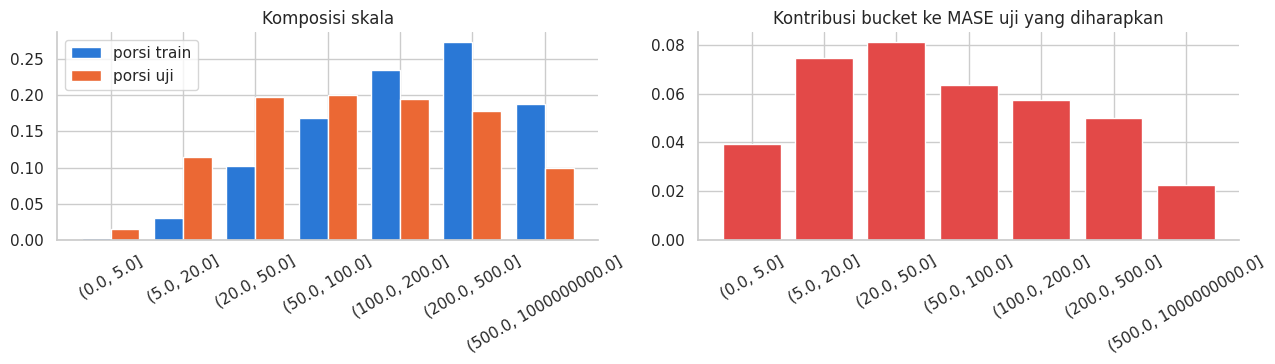

In [33]:
E = Xtr[['movie_title', 'h', 'scale', 'total_ticket', 'd1']].assign(pred=oof_final, w=TW)
E['ae'] = np.abs(E.total_ticket - E.pred) / E.scale
cut = pd.cut(E.scale, CFG.TW_BINS)
bk = pd.DataFrame({'test_share': pd.cut(Xte.scale, CFG.TW_BINS).value_counts(normalize=True), 'train_share': cut.value_counts(normalize=True),
                   'mase': E.groupby(cut, observed=False).ae.mean(), 'zero_rate': (E.total_ticket == 0).groupby(cut, observed=False).mean()}).sort_index()
bk['contribution_to_test'] = bk.test_share * bk.mase
display(bk.round(3))
wm = lambda g: np.average(g.ae, weights=g.w)
print('TW-MASE by horizon:', E.groupby('h').apply(wm, include_groups=False).round(3).to_dict())
print('TW-MASE by release month:', E.groupby(E.d1.dt.strftime('%Y-%m')).apply(wm, include_groups=False).round(3).to_dict())
fe = E.assign(c=E.ae * E.w / E.w.sum()).groupby(base_title(E.movie_title)).c.sum()
print(f'top-5 films carry {fe.nlargest(5).sum() / fe.sum():.1%} of the weighted error:', fe.nlargest(5).index.tolist())
d_ = (np.abs(y - oof_final) - np.abs(y - SEL['comp'][0])) / s * TW
G_ = pd.DataFrame({'g': groups, 'd': d_, 'w': TW}).groupby('g').sum()
ix_ = np.random.default_rng(CFG.SEED).integers(0, len(G_), (2000, len(G_)))
ci = np.quantile(G_.d.values[ix_].sum(1) / G_.w.values[ix_].sum(1), [0.025, 0.975])
print(f'final vs LightGBM film bootstrap 95% CI of TW change: [{ci[0]:+.4f}, {ci[1]:+.4f}] | films better {int((G_.d < 0).sum())}/{len(G_)}')

SEGS = {'target zero': y == 0, 'target positive': y > 0, 'growth (y > D3)': y > Xtr.y3.values,
        'positive, no growth': (y > 0) & (y <= Xtr.y3.values), 'D4-D5': hh_ <= 5}
PRED = {'LightGBM': SEL['comp'][0], **{n: COMP[n][0] for n in COMP if n != 'lgb'}, 'final': oof_final}
seg_tab = pd.DataFrame({k: {sg: np.average(np.abs(y[m] - p[m]) / s[m], weights=TW[m]) for sg, m in SEGS.items()} for k, p in PRED.items()})
seg_tab['TW share'] = {sg: TW[m].sum() / TW.sum() for sg, m in SEGS.items()}
display(seg_tab.round(4))

fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
xx = np.arange(len(bk))
ax[0].bar(xx - .2, bk.train_share, .4, label='porsi train'); ax[0].bar(xx + .2, bk.test_share, .4, label='porsi uji')
ax[0].set_xticks(xx, [str(i) for i in bk.index], rotation=30); ax[0].legend(); ax[0].set_title('Komposisi skala')
ax[1].bar(xx, bk.contribution_to_test, color=PAL[7]); ax[1].set_xticks(xx, [str(i) for i in bk.index], rotation=30)
ax[1].set_title('Kontribusi bucket ke MASE uji yang diharapkan')
plt.tight_layout(); plt.savefig(CFG.FIG_DIR / 'evaluation.png'); plt.show()

#### Insights

> Pasangan dengan skala di bawah 50 hanya sekitar 13% baris train tetapi 33% baris uji dan menyumbang porsi terbesar MASE uji yang diharapkan. Lima film menyumbang kira-kira seperempat sampai sepertiga galat berbobot (`eda/51`), sehingga perbedaan versi di bawah lebar interval bootstrap per film tidak boleh dibaca sebagai perbaikan pasti.

> Tabel segmen memisahkan galat pada target nol, target positif, dan pertumbuhan setelah D3 (audit v12: v12 membaik pada nol tetapi memburuk pada film yang masih tumbuh). Segmen tumbuh adalah bagian dari segmen positif, bukan kelompok tambahan. Perbaikan yang hanya memindahkan galat dari satu segmen ke segmen lain harus terlihat di sini sebelum dipercaya.

---

# Inference & Submission <a name="10"></a>

---

Model final dilatih pada seluruh sampel (rilis luas dan rilis terbatas) dengan konfigurasi terpilih. Statistik klaster untuk data uji memakai seluruh train (masa lalu film uji). Tidak ada parameter yang disetel pada leaderboard.

## Porsi Pasar Slate Lebaran 2025

Analog Lebaran mengalikan total pasar per klaster pada minggu Lebaran 2025 dengan $\rho$, yaitu porsi pasar yang diambil slate film Lebaran. v8 sampai v18 memakai $\rho = 0{,}5$ sebagai asumsi. Porsi ini bisa diukur langsung: `train.csv` dimulai 1 April 2025 (Lebaran hari ke-2), dan film yang dirilis serentak untuk Lebaran sudah tayang di hampir semua klaster sejak hari pertama data. Slate 2025 didefinisikan sebagai judul dasar yang transaksi pertamanya di train jatuh pada 1 April 2025 dan tayang di 100 klaster atau lebih pada hari itu.

In [34]:
leb_week = train[train.date_show.between('2025-04-01', '2025-04-07')].assign(base=base_title(train.movie_title))
first_day = train.assign(base=base_title(train.movie_title)).groupby('base').date_show.min()
nc_day1 = leb_week[leb_week.date_show == '2025-04-01'].groupby('base').cinema_ids.nunique()
slate25 = sorted(nc_day1[(nc_day1 >= 100) & (first_day.reindex(nc_day1.index) == pd.Timestamp('2025-04-01'))].index)
by_title = leb_week.groupby('base').total_ticket.sum()
share25 = by_title[slate25].sum() / by_title.sum()
CFG.LEB_RHO = round(float(share25), 2)
print('slate Lebaran 2025:', slate25)
print(f'porsi pasar slate 1-7 April 2025: {share25:.4f} -> LEB_RHO = {CFG.LEB_RHO}')
display((by_title / by_title.sum()).sort_values(ascending=False).head(8).round(3).rename('porsi_tiket').to_frame())

slate Lebaran 2025: ['JUMBO', 'KOMANG', 'NORMA: ANTARA MERTUA DAN MENANTU', 'PABRIK GULA', 'PABRIK GULA UNCUT', 'QODRAT 2']
porsi pasar slate 1-7 April 2025: 0.9225 -> LEB_RHO = 0.92


,porsi_tiket
base,
PABRIK GULA UNCUT,0.199
QODRAT 2,0.192
JUMBO,0.184
KOMANG,0.145
PABRIK GULA,0.134
NORMA: ANTARA MERTUA DAN MENANTU,0.068
A WORKING MAN,0.041
NE ZHA 2,0.012


#### Insights

> Lima film rilis 31 Maret 2025 (PABRIK GULA dalam dua versi, QODRAT 2, JUMBO, KOMANG, NORMA) mengambil sekitar 92% tiket 1 sampai 7 April 2025; film lama yang masih tayang hanya sekitar 8%. Asumsi $\rho = 0{,}5$ di v8 sampai v18 karena itu meremehkan slate hampir separuh. Struktur 2026 serupa: enam judul dirilis serentak 18 Maret untuk Lebaran, bersaing dengan film rilis awal Maret yang sudah menurun.

## Minggu Lebaran: Analog Top-Down dari Lebaran 2025

Tujuh judul slate Lebaran 2026 dirilis 18 Maret, sehingga D4 sampai D10 mereka adalah Lebaran hari 1 sampai 7 (6,1% baris uji), periode yang tidak memiliki padanan di sampel latih. Namun `train.csv` dimulai 1 April 2025, yaitu Lebaran 2025 hari ke-2, sehingga total tiket per klaster selama minggu Lebaran 2025 teramati.

**Analog (v8 sampai v18).** Rasio pasangan pada Lebaran hari ke-$k$ = $\rho \sqrt{r_{cl}(c, k)\, r_{nat}(k)}$, dengan $r_{cl}$ = total klaster pada Lebaran 2025 hari ke-$k$ dibagi rata-rata harian slate 2026 di klaster itu pada D1 sampai D3, dan $r_{nat}$ versi nasionalnya. Semua pasangan dalam satu klaster mendapat rasio yang sama.

**Rasio kapasitas (v19).** Pada minggu Lebaran 2025 okupansi slate naik dari median 37% (minggu normal) ke 73% dengan jumlah pertunjukan tetap: tiket dibatasi kursi. Rasio kapasitas klaster = kursi slate 2026 pada D3 x okupansi slate 2025 di klaster itu pada hari ke-$k$ / rata-rata harian slate 2026 pada D1 sampai D3. Kursi per baris = tiket / okupansi (baris okupansi 1 sampai 100% dengan pertunjukan positif). Rasio ini memakai alokasi layar 2026 yang sebenarnya, termasuk lokasi yang dibuka atau diperluas setelah Lebaran 2025.

**Gabungan.** $r = r_{an}^{1 - w}\, r_{cap}^{w}$ dengan $w$ = `LEB_CAP_W` = 0,5, lalu setiap hari diskalakan ulang agar total nasional slate sama dengan analog. Jadi level nasional tetap milik analog (dikonfirmasi dua jalur di `eda/121`), dan yang berubah hanya pembagian antar klaster. Pada tujuh lonjakan libur berlabel di train (`eda/124`), rata-rata prediksi dari pola klaster masa lalu dan dari okupansi lebih akurat (skill 0,44) daripada pola masa lalu saja (0,20) atau okupansi saja (0,39). Pembagian antar film di dalam klaster tidak diubah, karena pada lonjakan yang sama okupansi film tidak memprediksi uplift film (slope 0,0).

slate 2026: ['DANUR: THE LAST CHAPTER', 'DANUR: THE LAST CHAPTER (IMAX 2D)', 'NA WILLA', 'PELANGI DI MARS', 'SENIN HARGA NAIK', 'SUZZANNA: SANTET DOSA DI ATAS DOSA', 'TUNGGU AKU SUKSES NANTI']
normal 2025 day 217072 | 2025 Lebaran week mean 593714 | 2026 slate mean D1-D3 167461
slate seats per day: 2026 D1-D3 1001729 (occupancy 17%) | 2025 Lebaran 918119 (occupancy 59%)


,rho=0.5,rho=0.7,rho=0.92,rho=1.0,occupancy_needed_rho=0.92
D4 (Lebaran day 1),1.03,1.45,1.90,2.07,32.0
D5 (Lebaran day 2),1.38,1.93,2.54,2.76,42.0
D6 (Lebaran day 3),1.68,2.35,3.09,3.35,52.0
D7 (Lebaran day 4),1.89,2.64,3.47,3.77,58.0
D8 (Lebaran day 5),1.86,2.61,3.43,3.72,57.0
D9 (Lebaran day 6),1.98,2.77,3.64,3.96,61.0
D10 (Lebaran day 7),1.85,2.59,3.41,3.71,57.0


,analog total,v19 total,mean r analog,mean r v19
Lebaran day,,,,
1,316990.33,316990.33,2.00,2.08
2,422653.78,422653.78,2.66,2.77
3,512659.46,512659.46,3.28,3.41
4,576405.09,576405.09,3.69,3.83
5,569791.70,569791.70,3.64,3.76
6,605787.77,605787.77,3.87,4.01
7,566559.89,566559.89,3.64,3.78


v19 / analog factor per row, quantiles 5/25/50/75/95%: [0.769, 0.953, 1.039, 1.11, 1.236]
largest cluster moves: {('14b63ff2b104903ead7d884f25382e57', 'MALANG'): 0.63, ('0191582d75f94a412c0fa12d36bcee3f', 'SURABAYA'): 0.71, ('c71a18e33d4b7c73c8124c65fc3e6f1c', 'MANADO'): 0.74, ('4a4c71e99772e87c9e35a56acd8be21e', 'TERNATE'): 1.32, ('ab66df99207da01f3e300ef0163a1d2e', 'BOGOR'): 1.49, ('53b77c875c67b68561415f23065e6e8d', 'PADANG'): 1.99}


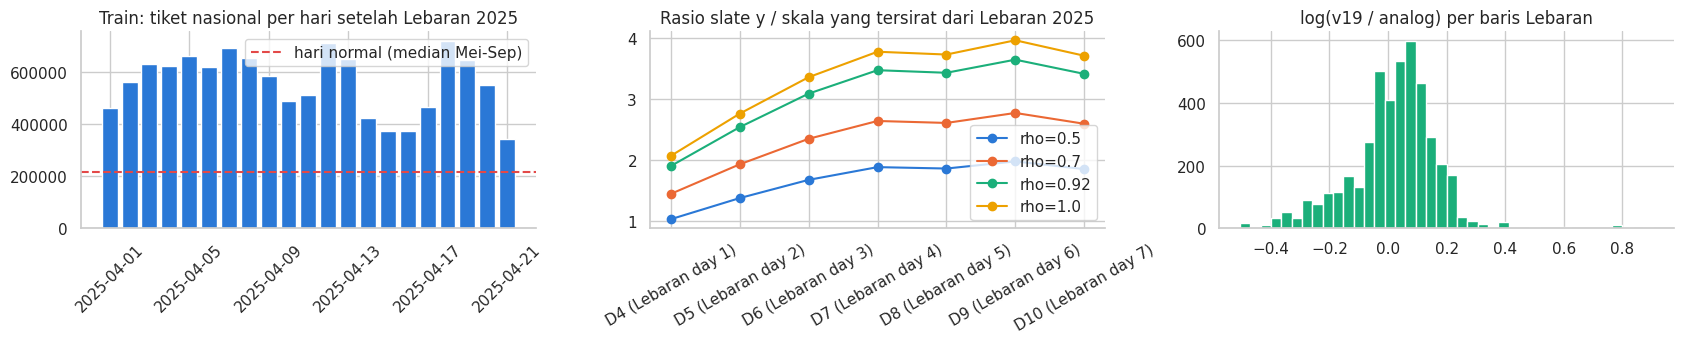

In [35]:
LEB25, LEB26 = pd.Timestamp('2025-03-31'), pd.Timestamp('2026-03-21')
leb_mask = Xte.date_show.between(LEB26, LEB26 + pd.Timedelta(days=6)).values
slate = sorted(Xte.movie_title[leb_mask].unique())
seat_of = lambda d: pd.Series(np.where((d.occupation_rate >= 1) & (d.occupation_rate <= 100) & (d.total_show > 0),
                                       d.total_ticket / (d.occupation_rate / 100), np.nan), index=d.index)
hsl = hist[hist.movie_title.isin(slate)].assign(seats=lambda d: seat_of(d))
s25 = train[base_title(train.movie_title).isin(slate25)].assign(seats=lambda d: seat_of(d))
day25 = train.groupby('date_show').total_ticket.sum()
normal_day = day25.loc['2025-05-01':].median()
m25 = pd.Series({k: day25[LEB25 + pd.Timedelta(days=k - 1)] for k in range(2, 8)})
m25.loc[1] = CFG.LEB_DAY1 * m25.loc[2]
m25 = m25.sort_index()
S26 = hsl.groupby('date_show').total_ticket.sum().mean()
seats26 = hsl.groupby('date_show').seats.sum().mean()
seats25 = s25[s25.date_show.between('2025-04-01', '2025-04-06')].groupby('date_show').seats.sum().mean()
occ25 = s25[s25.date_show.between('2025-04-01', '2025-04-06')]
print('slate 2026:', slate)
print(f'normal 2025 day {normal_day:.0f} | 2025 Lebaran week mean {m25.loc[2:7].mean():.0f} | 2026 slate mean D1-D3 {S26:.0f}')
print(f'slate seats per day: 2026 D1-D3 {seats26:.0f} (occupancy {100 * S26 / seats26:.0f}%) | 2025 Lebaran {seats25:.0f} '
      f'(occupancy {100 * occ25.total_ticket.sum() / occ25.seats.sum():.0f}%)')
imp_r = pd.DataFrame({f'rho={r_}': r_ * m25 / S26 for r_ in (0.5, 0.7, CFG.LEB_RHO, 1.0)})
imp_r.index = [f'D{k + 3} (Lebaran day {k})' for k in imp_r.index]
imp_r[f'occupancy_needed_rho={CFG.LEB_RHO}'] = (CFG.LEB_RHO * m25.values / seats26 * 100).round(0)
display(imp_r.round(2))

c26 = hsl.groupby('cinema_ids').total_ticket.sum() / 3
seat26_cl = hsl[hsl.date_show == hsl.date_show.max()].groupby('cinema_ids').seats.sum(min_count=1)
kday = (Xte.date_show - LEB26).dt.days.values + 1
s_all = Xte.scale.values
r_an, r_v2 = np.zeros(len(Xte)), np.zeros(len(Xte))
for k in range(1, 8):
    m = leb_mask & (kday == k)
    dk = LEB25 + pd.Timedelta(days=max(k, 2) - 1)
    f = CFG.LEB_DAY1 if k == 1 else 1.0
    c25k = train[train.date_show == dk].groupby('cinema_ids').total_ticket.sum() * f
    g25 = s25[s25.date_show == dk].groupby('cinema_ids')
    occ_cl = g25.total_ticket.sum() / g25.seats.sum(min_count=1) * f
    occ_nat = s25[s25.date_show == dk].total_ticket.sum() / s25[s25.date_show == dk].seats.sum() * f
    r_nat = m25.loc[k] / S26
    cl = Xte.cinema_ids[m]
    r_cl = (cl.map(c25k) / cl.map(c26)).values
    r_cl = np.where(np.isfinite(r_cl) & (r_cl > 0), r_cl, r_nat)
    # geometric mean of cluster and national ratio (v8-v18 analog)
    an = CFG.LEB_RHO * np.sqrt(r_cl * r_nat)
    cap = (cl.map(seat26_cl) * cl.map(occ_cl).fillna(occ_nat) / cl.map(c26)).values
    cap = np.where(np.isfinite(cap) & (cap > 0), cap, an)
    v2 = np.exp((1 - CFG.LEB_CAP_W) * np.log(an) + CFG.LEB_CAP_W * np.log(cap))
    # rescale so the national slate total of the day equals the analog's
    v2 *= (an * s_all[m]).sum() / (v2 * s_all[m]).sum()
    r_an[m], r_v2[m] = an, v2
leb_pred = s_all * r_v2
kk = pd.Series(kday[leb_mask])
chk_leb = pd.DataFrame({'analog total': pd.Series(r_an[leb_mask] * s_all[leb_mask]).groupby(kk.values).sum(),
                        'v19 total': pd.Series(r_v2[leb_mask] * s_all[leb_mask]).groupby(kk.values).sum(),
                        'mean r analog': pd.Series(r_an[leb_mask]).groupby(kk.values).mean(),
                        'mean r v19': pd.Series(r_v2[leb_mask]).groupby(kk.values).mean()})
chk_leb.index.name = 'Lebaran day'
display(chk_leb.round(2))
assert np.allclose(chk_leb['analog total'], chk_leb['v19 total']), 'national Lebaran level must equal the analog'
fac = r_v2[leb_mask] / r_an[leb_mask]
print('v19 / analog factor per row, quantiles 5/25/50/75/95%:', np.round(np.quantile(fac, [.05, .25, .5, .75, .95]), 3).tolist())
mov = pd.DataFrame({'cinema_ids': Xte.cinema_ids[leb_mask].values, 'city': Xte.city_name[leb_mask].values, 'lf': np.log(fac)})
mov = mov.groupby(['cinema_ids', 'city']).lf.mean().apply(np.exp).sort_values()
print('largest cluster moves:', pd.concat([mov.head(3), mov.tail(3)]).round(2).to_dict())

dd = day25.loc['2025-04-01':'2025-04-21']
fig, ax = plt.subplots(1, 3, figsize=(17, 3.6))
ax[0].bar(dd.index, dd.values, color=PAL[0]); ax[0].axhline(normal_day, color=PAL[7], ls='--', label='hari normal (median Mei-Sep)')
ax[0].set(title='Train: tiket nasional per hari setelah Lebaran 2025'); ax[0].legend(); ax[0].tick_params(axis='x', rotation=45)
imp_r.drop(columns=imp_r.columns[-1]).plot(ax=ax[1], marker='o'); ax[1].tick_params(axis='x', rotation=30)
ax[1].set(title='Rasio slate y / skala yang tersirat dari Lebaran 2025')
ax[2].hist(np.log(fac), bins=40, color=PAL[2]); ax[2].set(title='log(v19 / analog) per baris Lebaran')
plt.tight_layout(); plt.savefig(CFG.FIG_DIR / 'lebaran.png'); plt.show()

#### Insights

> Minggu Lebaran 2025 berjalan di sekitar 594 ribu tiket per hari (2,7 kali hari normal) dan tetap 2,3 sampai 3 kali normal pada hari kerja setelah cuti bersama. Slate 2026 sudah menawarkan sekitar satu juta kursi per hari pada D1 sampai D3 (2025: sekitar 0,92 juta) dengan okupansi rendah karena D1 sampai D3 jatuh pada hari terakhir Ramadan dan arus mudik. Model statistik memprediksi slate turun ke rasio sekitar 0,7 terhadap skala, setara okupansi sekitar 13% pada minggu puncak tahunan, sehingga baris Lebaran memakai analog.

> Dengan $\rho$ terukur 0,92, total nasional analog sekitar 0,54 juta tiket per hari. Jalur independen (kursi slate 2026 x okupansi Lebaran 2025) memberi sekitar 0,57 juta, sehingga level ini didukung dua cara. Perubahan v19 hanya memindahkan prediksi antar klaster (median faktor sekitar 1,0, kuantil 5 sampai 95% sekitar 0,77 sampai 1,24). Klaster yang naik paling banyak adalah ID Padang yang menyerap pembukaan Basko City Mall XXI (Juli 2025, lima studio): total Lebaran 2025-nya meremehkan kapasitas 2026. Sebelumnya, mengganti $\rho$ 0,5 ke 0,92 pada resep v8 menurunkan public dari 0,39991 ke 0,38111; v19 tidak memakai skor tersebut untuk memilih nilai apa pun, $\rho$ berasal dari train.

In [36]:
t0 = time.time()
Xall = pd.concat([Xtr] + ([Xlim] if CFG.USE_LIMITED else []) + ([XP] if SEL['cfg']['partial'] else []), ignore_index=True)
print(f'final training rows {len(Xall)} (partial-window rows included: {SEL["cfg"]["partial"]})')
XA, XT = with_cin(Xall, STATS_ALL), with_cin(Xte, STATS_ALL)
feats_f, zfeats_f = FEATS, ZFEATS
cm_te, s_te_ = Xte.cal_mult.values, Xte.scale.values
te_comp, final_lgb, lgb_mb = {}, None, 0.0
if WEIGHTS.get('lgb', 0) > 0:
    final_lgb = fit_lgb_all(XA)
    te_comp['lgb'] = lgb_mix(*predict_lgb_all(final_lgb, XT)) * cm_te * s_te_
    lgb_mb = lgb_size_mb(final_lgb)
est_mb = lgb_mb + sum(SIZE_MB[n] for n in WEIGHTS if n != 'lgb')
print(f'weights estimate: LightGBM {lgb_mb:.1f} MB + others {est_mb - lgb_mb:.1f} MB = {est_mb:.1f} MB')
assert est_mb + CFG.SIZE_MARGIN_MB <= CFG.MAX_WEIGHTS_MB, 'weights would exceed the 200 MB rule'
for n in WEIGHTS:
    if n != 'lgb':
        te_comp[n] = quant_median(QFN[n](XA, XT), LAM_CHOICE[n]) * cm_te * s_te_
assert set(te_comp) == set(WEIGHTS), f'component mismatch {set(te_comp)} vs {set(WEIGHTS)}'
pred = np.clip(sum(WEIGHTS[n] * te_comp[n] for n in te_comp), 0, None)
print('model mean r on Lebaran rows:', round(float((pred / s_te_)[leb_mask].mean()), 3), '-> analog', round(float((leb_pred / s_te_)[leb_mask].mean()), 3))
pred = np.where(leb_mask, leb_pred, pred)
print(f'final fit + inference: {time.time() - t0:.0f}s')

seg = pd.Series('normal', index=Xte.index)
for n, (a, b) in SEGMENTS.items():
    seg[Xte.date_show.between(a, b)] = n
rr = pred / s_te_
display(pd.DataFrame({'rows': seg.value_counts(), 'mean_r_hat': pd.Series(rr).groupby(seg.values).mean(),
                      'pred_zero_share': pd.Series(rr < .05).groupby(seg.values).mean()}).round(3))
bk_te = pd.cut(Xte.scale, CFG.TW_BINS).astype(str).values
bk_tr = pd.cut(Xtr.scale, CFG.TW_BINS).astype(str).values
display(pd.DataFrame({'test rows': pd.Series(bk_te).value_counts(), 'test mean r_hat / c_mult': pd.Series(rr / cm_te).groupby(bk_te).mean(),
                      'OOF mean r_hat / c_mult': pd.Series(oof_final / s / cm).groupby(bk_tr).mean(),
                      'OOF mean r / c_mult': pd.Series(y / s / cm).groupby(bk_tr).mean()}).round(3))

final training rows 55747 (partial-window rows included: False)
weights estimate: LightGBM 0.0 MB + others 198.4 MB = 198.4 MB


[W1009 05:48:28.739585688 CUDACachingAllocator.cpp:3934] memory allocation failed with OOM on device 0 while trying to allocate 1275068416 bytes (free: 1038942208, total: 15636037632).


model mean r on Lebaran rows: 0.816 -> analog 3.377
final fit + inference: 1146s


,rows,mean_r_hat,pred_zero_share
lebaran,4417,3.377,0.000
normal,50551,0.469,0.297
ramadan,12408,0.358,0.485
xmas,5235,0.657,0.073


,test rows,test mean r_hat / c_mult,OOF mean r_hat / c_mult,OOF mean r / c_mult
"(0.0, 5.0]",1120,0.286,0.306,2.600
"(100.0, 200.0]",14147,0.711,0.456,0.538
"(20.0, 50.0]",14392,0.390,0.323,0.533
"(200.0, 500.0]",12901,0.790,0.561,0.622
"(5.0, 20.0]",8288,0.261,0.275,0.620
"(50.0, 100.0]",14504,0.517,0.347,0.477
"(500.0, 1000000000.0]",7259,0.813,0.620,0.644


Submisi disimpan dengan format `id,total_ticket` dan urutan `id` yang sama dengan `sample_submission.csv`. Seluruh bobot (booster LightGBM terkompresi, state TabM beserta transformasi inputnya bila dipakai, dan checkpoint TabPFN terpilih dalam format yang sama persis dengan yang divalidasi) disimpan dalam satu berkas `.pkl`, dengan pemeriksaan batas 200 MB yang menghentikan notebook bila terlampaui.

In [37]:
submission = pd.DataFrame({'id': test.id.values, 'total_ticket': pred})
assert len(submission) == len(sub) and (submission.id.values == sub.id.values).all()
assert submission.total_ticket.notna().all() and (submission.total_ticket >= 0).all()
submission.to_csv(CFG.OUTPUT_DIR / 'submission.csv', index=False)
oof_df = pd.DataFrame({'movie_title': Xtr.movie_title, 'cinema_ids': Xtr.cinema_ids, 'h': Xtr.h, 'fold': FOLD, 'y': y, 'scale': s,
                       'week': WEEK,
                       'oof_lgbmix': oof_lgbmix, 'oof_final': oof_final})
for n in COMP:
    oof_df[f'comp_{n}'] = COMP[n][0]
oof_df.to_csv(CFG.OUTPUT_DIR / 'oof.csv', index=False)
np.savez_compressed(CFG.OUTPUT_DIR / 'oof_quantiles.npz', lgb_p0=SEL['oof']['p0'], lgb_Q=SEL['oof']['Q'],
                    **{f'{n}_Q': QUANT[n][0] for n in QUANT})
zs = lambda m: zlib.compress(m.booster_.model_to_string().encode(), 9)
fm_used = [n for n in WEIGHTS if n in FM_FILES]
fm_files = {k_: Path(p_).read_bytes() for n in fm_used for k_, p_ in FM_FILES[n].items()}
lgb_blob = None if final_lgb is None else {'l1': [zs(m) for m in final_lgb['l1']], 'zero_clf': zs(final_lgb['zc']),
                                           'quantiles': [zs(m) for m in final_lgb['qm']]}
payload = {'lightgbm': lgb_blob,
           'tabm': None, 'compression': 'zlib', 'features': feats_f, 'zero_features': zfeats_f,
           'feature_config': FEATURE_CFG, 'pull_a': PULL_A, 'blend_weights': WEIGHTS,
           'pull_shift_per_model': LAM_CHOICE, 'fm_used': fm_used, 'fm_files': fm_files,
           'fm_file_sha256': {k_: sha256(p_) for n in fm_used for k_, p_ in FM_FILES[n].items()},
           'tp35_bits': CFG.TP35_BITS, 'causilo_bits': CFG.CAUSILO_BITS, 'fold_scheme': 'release-week cohort', 'feature_config_partial': SEL['cfg']['partial'], 'fm_failed': FM_FAIL,
           'lebaran': {'rho': CFG.LEB_RHO, 'cap_w': CFG.LEB_CAP_W, 'slate25': slate25},
           'settings': {k: v for k, v in vars(Settings).items() if k.isupper()}}
blob = pickle.dumps(payload)
(CFG.OUTPUT_DIR / 'model_weights.pkl').write_bytes(blob)
print(f'weights: {len(blob) / 1e6:.1f} MB (cap {CFG.MAX_WEIGHTS_MB} MB) | foundation model inside: {list(fm_files)} | TabM inside: {payload["tabm"] is not None}')
assert len(blob) / 1e6 <= CFG.MAX_WEIGHTS_MB, 'model weights exceed the 200 MB rule'
display(submission.head())

weights: 198.4 MB (cap 200 MB) | foundation model inside: ['causilo-regressor-int7.pack', 'regressor/config.json', 'tabpfn-v3.5-full-int7.pack'] | TabM inside: False


,id,total_ticket
0,1,31.016895
1,2,25.423438
2,3,1.205160
3,4,0.000000
4,5,0.000000


#### Insights

> v19 mempertahankan resep v18 (fitur v13, fold kohort minggu rilis, backtest temporal, aturan adopsi partial-window, blend dua foundation model int7 dengan batas 200 MB) dan mengubah tiga hal yang didukung analisis data, bukan leaderboard: blok anomali pelaporan 1 sampai 16 Juni 2025 dibuang dari label latih, porsi pasar slate Lebaran $\rho$ diukur dari train, dan rasio klaster Lebaran digabung dengan rasio kapasitas kursi 2026 tanpa mengubah level nasional.

> TW-MASE v19 dihitung pada populasi tanpa baris blok Juni, sehingga perbandingan dengan v18 harus dilakukan pada baris yang ada di kedua versi. Perubahan Lebaran tidak terlihat di validasi mana pun karena train tidak punya jendela yang melintasi Lebaran; dasarnya adalah pengukuran $\rho$, konfirmasi level lewat kapasitas kursi, dan uji lintas tujuh lonjakan libur berlabel.

> Untuk reproduksi, paket int7 setiap foundation model yang terpilih disimpan di berkas bobot dalam format persis yang divalidasi, dicari dulu di input Kaggle atau di dalam berkas bobot sebelum ke Hugging Face, dan diverifikasi dengan SHA-256. Bila berkas bobot dilampirkan, notebook tidak perlu mengunduh checkpoint float32 sama sekali. Kandidat foundation model yang gagal dicetak dan dilewati (`FM_STRICT = False`).